# Setup

In [1]:
%cd ../

/Users/aleksandrnalitkin/PycharmProjects/jet


In [2]:
%config Completer.use_jedi = False
%load_ext autoreload
%autoreload 3

In [3]:
from IPython.display import display, Markdown
import logging
import pandas as pd
import numpy as np
import lightgbm as lgb
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import statsmodels.formula.api as smf
import cvxpy as cp
from pathlib import Path
import itertools
from collections import defaultdict

def ps538():
    plt.plot([0], [0])
    plt.close()
    plt.style.use('fivethirtyeight')
ps538()

np.set_printoptions(legacy='1.25')

In [4]:
from src.utils import setup_logging, LOGGER_NAME
logger_name = LOGGER_NAME
setup_logging(name = logger_name, to_stdout = True)
logger = logging.getLogger(logger_name)
logger.info(f"logger {logger_name} was set up")

2026-10-28T22:58:01,514  INFO 4279292758.py - logger uplift_model_logger was set up


# Data description

In [5]:
def show_md(path):
    display(Markdown(Path(path).read_text(encoding="utf-8")))

show_md("./docs/data_description.md")

# Personalised promotions dataset

## Context

`e-commerce.co` is an online marketplace. Each row represents one eligible user and one
weekly promotion decision. A user may receive a voucher worth 0%, 10%, 20%, 30%, or 40% of
an order.

Some users also receive free delivery. This is a separate promotion that has already been
decided, so `free_delivery` must be treated as fixed when assigning vouchers.

All monetary values are expressed in currency units (CU).

## Files

- `data/history.parquet` contains eligible user-weeks from weeks 9–14. It includes features
known before the decision, the randomly assigned promotion, and the observed outcomes.
- `data/inference.parquet` contains eligible user-weeks from weeks 15–16. It includes only
information available when making the decision. You must add a voucher decision for every
row.

No additional tables need to be joined.

## Historical assignment

During weeks 9–14, eligible users were randomly assigned to one of ten combinations:

```text
voucher_pct   ∈ {0, 10, 20, 30, 40}
free_delivery ∈ {false, true}
```

Each combination was assigned to approximately 10% of eligible users within each city. This
randomised history can be used to estimate how the available decisions affect ordering and
voucher cost.

For weeks 15–16, `free_delivery` has already been assigned and appears in
`inference.parquet`. Only `voucher_pct` remains for you to choose.

## Voucher use and cost

`voucher_used` records whether the assigned voucher was used on a qualifying order.

- When `voucher_used` is `false`, `voucher_cost` is 0.
- When `voucher_used` is `true`, `voucher_cost` is the actual discount paid by the
marketplace and is greater than 0.
- A 0% voucher cannot be used and has zero cost.

Every voucher has a maximum discount of 9 CU. In other words, a 40% voucher means
“40% off, up to 9 CU.” The marketplace's voucher cost is the discount given to the
customer:

```text
voucher_cost = min(voucher_pct / 100 × order value, 9 CU)
```

## Columns

### Identifiers and decision context

- `user_id` (integer): user identifier.
- `week` (integer): 9–14 in history and 15–16 in inference.
- `city` (string): the user's city.
- `free_delivery` (boolean): whether the user receives free delivery that week.

### Previous order behaviour

- `orders_90d` (integer): orders in the previous 90 days.
- `orders_30d` (integer): orders in the previous 30 days.
- `days_since_last_order` (integer): days since the user's last order; null if none.
- `aov_90d` (float): average order value in CU over the previous 90 days.

### Previous promotion behaviour

- `pct_orders_with_promo_90d` (float): share of previous-90-day orders using a promotion.
- `avg_voucher_pct_received_90d` (float): mean voucher percentage previously assigned over
90 days.
- `voucher_redemption_rate_90d` (float): vouchers used divided by vouchers received over
90 days.
- `manual_voucher_entry_rate_90d` (float): share of previous-90-day orders for which the
user manually entered a voucher code.

### Engagement

- `sessions_30d` (integer): app sessions in the previous 30 days.
- `days_since_last_session` (integer): days since the user's last app session.
- `push_opt_in` (boolean): whether push notifications are enabled.
- `offers_tab_share_of_sessions_30d` (float): share of previous-30-day sessions that
included the Offers tab.

### Historical decision and outcomes

These columns appear only in `history.parquet`:

- `voucher_pct` (integer): randomly assigned voucher percentage.
- `ordered` (boolean): whether the user placed at least one order that week.
- `voucher_used` (boolean): whether the assigned voucher was used.
- `voucher_cost` (float): actual voucher cost paid by the marketplace in CU.

All feature values describe information available before the weekly promotion decision.
Trailing rates may be null when a user has no relevant previous observations.

## Reading the files

```python
import pandas as pd

history = pd.read_parquet("data/history.parquet")
inference = pd.read_parquet("data/inference.parquet")
```

The files require a Parquet reader such as `pyarrow`, Polars, or DuckDB.

# Reading the data

In [6]:
data_path = Path('./data/')

In [7]:
history_data = pd.read_parquet(data_path / 'history.parquet')
display(history_data.tail())
inference_data = pd.read_parquet(data_path / 'inference.parquet')
display(inference_data.tail())

,user_id,week,city,orders_90d,orders_30d,days_since_last_order,aov_90d,pct_orders_with_promo_90d,avg_voucher_pct_received_90d,voucher_redemption_rate_90d,manual_voucher_entry_rate_90d,sessions_30d,days_since_last_session,push_opt_in,offers_tab_share_of_sessions_30d,free_delivery,voucher_pct,ordered,voucher_used,voucher_cost
358931,79995,14,city_04,2.0,0.0,47.0,9.000830,0.000000,16.923077,0.000000,0.500000,9.0,1.0,True,0.222222,False,30,True,False,0.0
358932,79996,14,city_03,2.0,1.0,11.0,26.790615,0.500000,18.333333,0.000000,0.000000,11.0,1.0,True,0.090909,True,20,False,False,0.0
358933,79997,14,city_06,3.0,2.0,14.0,17.357295,0.000000,18.461538,0.000000,0.333333,9.0,4.0,False,0.111111,False,0,True,False,0.0
358934,79998,14,city_01,13.0,4.0,4.0,17.562084,0.307692,10.000000,0.500000,0.384615,18.0,4.0,True,0.444444,False,20,True,False,0.0
358935,79999,14,city_06,5.0,1.0,8.0,29.795227,0.800000,20.769231,0.363636,0.600000,37.0,1.0,True,0.621622,False,10,False,False,0.0


,user_id,week,city,orders_90d,orders_30d,days_since_last_order,aov_90d,pct_orders_with_promo_90d,avg_voucher_pct_received_90d,voucher_redemption_rate_90d,manual_voucher_entry_rate_90d,sessions_30d,days_since_last_session,push_opt_in,offers_tab_share_of_sessions_30d,free_delivery
120482,79994,16,city_01,0.0,0.0,106.0,NaN,NaN,31.538462,0.000000,NaN,11.0,1.0,True,0.272727,False
120483,79995,16,city_04,2.0,1.0,8.0,7.262467,0.000000,16.923077,0.000000,0.500000,6.0,1.0,True,0.166667,True
120484,79996,16,city_03,2.0,1.0,25.0,26.790615,0.500000,18.461538,0.000000,0.000000,9.0,2.0,True,0.111111,False
120485,79998,16,city_01,13.0,4.0,5.0,16.593755,0.307692,11.538462,0.400000,0.461538,20.0,2.0,True,0.400000,True
120486,79999,16,city_06,4.0,2.0,6.0,29.524445,0.750000,20.769231,0.181818,0.250000,45.0,1.0,True,0.555556,True


In [8]:
display(history_data.dtypes.to_frame().T)
display(inference_data.dtypes.to_frame().T)

,user_id,week,city,orders_90d,orders_30d,days_since_last_order,aov_90d,pct_orders_with_promo_90d,avg_voucher_pct_received_90d,voucher_redemption_rate_90d,manual_voucher_entry_rate_90d,sessions_30d,days_since_last_session,push_opt_in,offers_tab_share_of_sessions_30d,free_delivery,voucher_pct,ordered,voucher_used,voucher_cost
0,int32,int8,str,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,float64,boolean,Int8,bool,bool,float64


,user_id,week,city,orders_90d,orders_30d,days_since_last_order,aov_90d,pct_orders_with_promo_90d,avg_voucher_pct_received_90d,voucher_redemption_rate_90d,manual_voucher_entry_rate_90d,sessions_30d,days_since_last_session,push_opt_in,offers_tab_share_of_sessions_30d,free_delivery
0,int32,int8,str,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,float64,boolean


### for some reason numeric features that are integer as per description are actually floats, let's try casting them

In [9]:
int_cols = ['orders_90d', 'orders_30d', 'sessions_30d', 'days_since_last_order', 'days_since_last_session', ]
display(history_data[int_cols].isna().mean().to_frame().T)
display(inference_data[int_cols].isna().mean().to_frame().T)
display(history_data[int_cols].describe().T)
display(inference_data[int_cols].describe().T)

### we might fill them right now, but it might not matter for some models and it will heavily bias some average statistics 
### maybe we will do it later
LONG_AGO_N_DAYS_VALUE = 9999

for i, c in tqdm(enumerate(int_cols)):
    if i >= 3:
        continue
        # history_data[c] = history_data[c].fillna(LONG_AGO_N_DAYS_VALUE)
        # inference_data[c] = inference_data[c].fillna(LONG_AGO_N_DAYS_VALUE)

    history_data[c] = history_data[c].astype(int)
    inference_data[c] = inference_data[c].astype(int)

,orders_90d,orders_30d,sessions_30d,days_since_last_order,days_since_last_session
0,0.0,0.0,0.0,0.106261,0.000404


,orders_90d,orders_30d,sessions_30d,days_since_last_order,days_since_last_session
0,0.0,0.0,0.0,0.092325,0.00029


,count,mean,std,min,25%,50%,75%,max
orders_90d,358936.0,3.149913,3.062352,0.0,1.0,2.0,5.0,13.0
orders_30d,358936.0,1.007149,1.153935,0.0,0.0,1.0,2.0,4.0
sessions_30d,358936.0,11.194494,12.751289,0.0,4.0,7.0,14.0,284.0
days_since_last_order,320795.0,33.287692,36.800566,1.0,7.0,18.0,47.0,182.0
days_since_last_session,358791.0,5.966691,9.411758,1.0,1.0,3.0,7.0,182.0


,count,mean,std,min,25%,50%,75%,max
orders_90d,120487.0,3.269066,3.140830,0.0,1.0,2.0,5.0,13.0
orders_30d,120487.0,1.045200,1.173982,0.0,0.0,1.0,2.0,4.0
sessions_30d,120487.0,11.546374,13.097113,0.0,4.0,8.0,14.0,282.0
days_since_last_order,109363.0,35.194865,41.557944,1.0,6.0,17.0,47.0,196.0
days_since_last_session,120452.0,5.812398,9.311171,1.0,1.0,3.0,6.0,196.0


0it [00:00, ?it/s]

# Config

In [10]:
id_col = 'user_id'
time_col = 'week'
city_col = 'city'

treatment_col = 'voucher_pct'
aux_treatment_col = 'free_delivery'


spec_cols = [
    id_col,
    time_col,
    treatment_col,
    aux_treatment_col,
]


target_col = 'ordered'
utilization_col = 'voucher_used'
cost_col = 'voucher_cost'

post_treatment_cols = [
    target_col, 
    utilization_col,
    cost_col,
]

num_feature_cols = (
    [
        'orders_90d',
        'orders_30d',
        'days_since_last_order',
        'aov_90d',
        'pct_orders_with_promo_90d',
        'avg_voucher_pct_received_90d',
        'voucher_redemption_rate_90d',
        'manual_voucher_entry_rate_90d',   
        'sessions_30d',
        'days_since_last_session',
        'push_opt_in',
        'offers_tab_share_of_sessions_30d',
    ]
)

cat_feature_cols = [
    city_col,
]

In [11]:
### create placeholder treatment_col with default treatment value for inference data
inference_data[treatment_col] = 0
history_data[treatment_col] = history_data[treatment_col].astype(int)

### convert booleans to 0/1 to simplify usage
### 'free_delivery' could be considered as both categorical and numeric - in both feature/treatment usages
for c in ['ordered', 'voucher_used', 'free_delivery', 'push_opt_in', ]:
    history_data[c] = history_data[c].astype(int)
    if c in inference_data.columns:
        inference_data[c] = inference_data[c].astype(int)

# EDA & Sanity Checks

### Before going any further - basic assumptions based on data description:

 - Existing feature aggregates always precede treatment assignment in time
 - Feature aggregates for the following week's start obsevation for the same user already capture his/her behaviour during this preceding week, we might want to (e.g. push_opt_in change over weeks) but we do not need to perform complex feature handling across weeks
 - Post-treatment columns do not participate in estimation for respective week observation as something we condition on - only as outcome variables, but they might be used as input variables for the following week
 - Voucher redemption and order placement tracking horizons are only covering a single week ahead
 - **ordered** flag is binary/boolean, so we don't really have neither any monetary value for such orders nor exact order count - we don't have explicit measurements on whether it was more than 1 order or not, hence we could not really learn a policy optimizing for AOV/margin/order-count increase properly
     - It's not stated explicitly, but we assume the measurement horizon for this flag is 1 week ahead from treatment, until the next week voucher assignment happens
     - Because of that, in the first modelling trial we would try to directionally increase the total weekly orders for the population by coming up with a policy using uplift estimates representing expected incremental quantity measured as **P(week_orders > 0|X, w, d, FD) - P(week_orders = 0|X, w, d, FD)**, essentially user-level expected conversion uplift
     - If we were to move towards long-term value optimization - we need a bit different experiment design (more on this later), towards true profitability or AOV optimization - we need more information available
         - We could only somehow obtain downwards biased estimate of order value for promo orders from capped **min(voucher_pct / 100 × order value, 9 CU)** value, but not for the rest of the orders for users in treatment group
         - If the provided data isn't synthetic - feature values were truly observed and weeks are indeed adjacent in reality, we actually might try to extract this information even using this limited data - e.g. for total spend by taking the difference between **orders_90d*aov_90d|week_t+1** and **orders_90d*aov_90d|week_t** but that would not work if **user_i** is observed for **week_t**, but not observed in **week_t+1** population - we do not know for sure - is it because he/she is churned and no longer eligible to be observed in the population or there's another reason for that. Without knowing that for sure and tracking we're at risk to end up just modelling some noise that doesn't reflect the real Data Generation Process. That said, we might still try that approach later in the research given we have time and resources and see what exactly we have in the data.
- We assume that each of the interventions **voucher_pct ∈ {0, 10, 20, 30, 40}** stays exactly the same across weeks, meaning ways of communication, content, promo delivery and redemption mechanics do not change in time

## Explore users overlap
- by datasets
- by weeks
- by treatments

In [12]:
for d in [history_data, inference_data]:
    gb = (
        d
        .agg({
            id_col: ['count', 'nunique', 'min', 'max'],
        })
        .T
    )
    display(gb)
    gb = (
        d
        .groupby([city_col, time_col])
        .agg({
            id_col: ['count', 'nunique', 'min', 'max'],
        })
        .T
    )
    display(gb)
    gb = (
        d
        .groupby([id_col])
        .agg({
            city_col: 'nunique',
        })
        .sort_values(by = city_col)
        .tail()
    )
    display(gb)    


hist_ids = set(history_data[id_col])
infer_ids = set(inference_data[id_col])

logger.info(f"{len(hist_ids)} users observed in history dataset")
logger.info(f"{len(infer_ids)} users observed in inference dataset")
logger.info(f"{len(hist_ids.intersection(infer_ids))} users observed in both history and inference datasets")

,count,nunique,min,max
user_id,358936,62604,1,79999


city            city_01                                    city_02         \
week                 9      10     11     12     13     14      9      10   
user_id count      7458   7456   7427   7489   7521   7542    7357   7365   
        nunique    7458   7456   7427   7489   7521   7542    7357   7365   
        min          16     16     16     25     16     16       1      1   
        max       79998  79998  79998  79998  79998  79998   79963  79963   

city                           ... city_07                      city_08  \
week                11     12  ...      11     12     13     14      9    
user_id count     7432   7401  ...    7601   7629   7654   7649    7453   
        nunique   7432   7401  ...    7601   7629   7654   7649    7453   
        min          1      1  ...      13     13     13     13       2   
        max      79963  79962  ...   79993  79993  79988  79993   79934   

city                                                
week                10     11     12     13     14  
user_id count     7461   7492   7468   7505   7493  
        nunique   7461   7492   7468   7505   7493  
        min          2      2      2      2      2  
        max      79990  79990  79990  79990  79975  

[4 rows x 48 columns]

,city
user_id,
26705,1
26707,1
26708,1
26710,1
79999,1


,count,nunique,min,max
user_id,120487,62738,1,79999


city            city_01        city_02        city_03        city_04         \
week                 15     16      15     16      15     16      15     16   
user_id count      7505   7555    7426   7472    7475   7483    7433   7443   
        nunique    7505   7555    7426   7472    7475   7483    7433   7443   
        min          16     16       1      1       6      6       8      8   
        max       79998  79998   79963  79963   79996  79996   79995  79995   

city            city_05        city_06        city_07        city_08         
week                 15     16      15     16      15     16      15     16  
user_id count      7564   7579    7595   7562    7692   7645    7518   7540  
        nunique    7564   7579    7595   7562    7692   7645    7518   7540  
        min          12     12       3     36      13     13       2      2  
        max       79969  79969   79999  79999   79993  79988   79990  79990

,city
user_id,
26701,1
26702,1
26704,1
26707,1
79999,1


2026-10-28T22:58:01,851  INFO 3128524462.py - 62604 users observed in history dataset
2026-10-28T22:58:01,851  INFO 3128524462.py - 62738 users observed in inference dataset
2026-10-28T22:58:01,852  INFO 3128524462.py - 62509 users observed in both history and inference datasets


In [13]:
gb = (
    history_data
    .groupby(treatment_col)
    .agg({
        id_col: ['count', 'nunique', 'min', 'max'],
    })
)
display(gb)

gb = (
    history_data
    .groupby([treatment_col, aux_treatment_col])
    .agg({
        id_col: ['count', 'nunique', 'min', 'max'],
        target_col: ['min', 'mean', 'max'],
        utilization_col: ['min', 'mean', 'max'],
        cost_col: ['min', 'mean', 'max', 'sum'],
    })
)
display(gb)

gb = (
    history_data
    .groupby([treatment_col, aux_treatment_col, time_col])
    .agg({
        id_col: ['count', 'nunique',],
    })
    .unstack(-1)
    .swaplevel(axis = 1).sort_index(axis = 1, level = 0, sort_remaining = False)
)
display(gb)


gb = (
    history_data
    .query("voucher_pct > 0")
    .groupby([time_col])
    .agg({
        id_col: ['count',],
        utilization_col: ['mean', 'sum'],
        cost_col: ['min', 'mean', 'max', 'sum'],
    })
)
display(gb)


display(pd.merge(
    left = inference_data[[id_col, time_col]].query("week == 15"), 
    right = inference_data[[id_col, time_col]].query("week == 16"), 
    on = id_col, how = 'inner',
).tail())

user_id                   
              count nunique min    max
voucher_pct                           
0             71828   44944   1  79999
10            71804   44848   1  79999
20            71784   44984   1  79998
30            71769   45007   6  79997
40            71751   45026   1  79999

user_id                    ordered                \
                            count nunique min    max     min      mean max   
voucher_pct free_delivery                                                    
0           0               35918   28297   2  79999       0  0.196169   1   
            1               35910   28257   1  79996       0  0.220384   1   
10          0               35906   28240   2  79999       0  0.222498   1   
            1               35898   28215   1  79999       0  0.243802   1   
20          0               35894   28223   1  79998       0  0.256087   1   
            1               35890   28339   1  79996       0  0.272221   1   
30          0               35887   28270   6  79997       0  0.296096   1   
            1               35882   28217   7  79997       0  0.306951   1   
40          0               35878   28361   3  79999       0  0.335498   1   
            1               35873   28291   1  79998       0  0.344159   1   

                          voucher_used               voucher_cost            \
                                   min      mean max          min      mean   
voucher_pct free_delivery                                                     
0           0                        0  0.000000   0          0.0  0.000000   
            1                        0  0.000000   0          0.0  0.000000   
10          0                        0  0.074222   1          0.0  0.190547   
            1                        0  0.075937   1          0.0  0.201921   
20          0                        0  0.102663   1          0.0  0.535789   
            1                        0  0.101644   1          0.0  0.543182   
30          0                        0  0.134673   1          0.0  0.993590   
            1                        0  0.137841   1          0.0  1.018959   
40          0                        0  0.169965   1          0.0  1.457506   
            1                        0  0.172553   1          0.0  1.484372   

                                              
                           max           sum  
voucher_pct free_delivery                     
0           0              0.0      0.000000  
            1              0.0      0.000000  
10          0              9.0   6841.794550  
            1              9.0   7248.558964  
20          0              9.0  19231.597207  
            1              9.0  19494.786114  
30          0              9.0  35656.972700  
            1              9.0  36562.286072  
40          0              9.0  52292.411402  
            1              9.0  53248.866348

user_id                                        \
week                           9     10    11    12    13    14      9    
                            count count count count count count nunique   
voucher_pct free_delivery                                                 
0           0                5958  5966  5979  5993  6009  6013    5958   
            1                5958  5965  5977  5991  6007  6012    5958   
10          0                5957  5965  5975  5991  6007  6011    5957   
            1                5955  5964  5975  5989  6005  6010    5955   
20          0                5955  5963  5975  5988  6004  6009    5955   
            1                5954  5961  5975  5988  6003  6009    5954   
30          0                5953  5960  5975  5988  6003  6008    5953   
            1                5951  5959  5973  5988  6003  6008    5951   
40          0                5950  5959  5972  5987  6003  6007    5950   
            1                5950  5959  5972  5985  6001  6006    5950   

                                                                   
week                           10      11      12      13      14  
                          nunique nunique nunique nunique nunique  
voucher_pct free_delivery                                          
0           0                5966    5979    5993    6009    6013  
            1                5965    5977    5991    6007    6012  
10          0                5965    5975    5991    6007    6011  
            1                5964    5975    5989    6005    6010  
20          0                5963    5975    5988    6004    6009  
            1                5961    5975    5988    6003    6009  
30          0                5960    5975    5988    6003    6008  
            1                5959    5973    5988    6003    6008  
40          0                5959    5972    5987    6003    6007  
            1                5959    5972    5985    6001    6006

user_id voucher_used       voucher_cost                             
       count         mean   sum          min      mean  max           sum
week                                                                     
9      47625     0.124871  5947          0.0  0.832484  9.0  39647.052475
10     47690     0.126882  6051          0.0  0.842760  9.0  40191.228861
11     47792     0.112613  5382          0.0  0.745914  9.0  35648.702184
12     47904     0.111598  5346          0.0  0.737261  9.0  35317.759633
13     48029     0.117596  5648          0.0  0.776931  9.0  37315.237072
14     48068     0.133498  6417          0.0  0.883276  9.0  42457.293133

,user_id,week_x,week_y
57744,79994,15,16
57745,79995,15,16
57746,79996,15,16
57747,79998,15,16
57748,79999,15,16


## Things we could establish from this primary analysis and things we should be careful about:

- User ids are surely masked from originals, but we assume here same ids in history and inference data mean the exactly same user
    - Hence, users overlap between historical data and inference data

- Population count is very stable across the timeline - we could assume it's weekly sliced customers by exactly same population entry criteria rather than a single cohort fixed at week9 or before - probably no survivorship bias and feature distribution doesn't change that much across weeks as well - to be verified later

- Split is indeed balanced - groups almost equal in sizes between all {Discount Voucher x FreeDelivery} 5x2 = 10 treatment groups / arms

- On the week level users are not duplicated - each receives it's own treatment once within a week and data is correct in that sense

- However, same user doesn't necessarily receive the same treatment consistently across weeks (arm isn't fixed in time for a user) - essentially we a sequentially randomized
design (micro-randomized trials)
    - This might be causing some carryover problems (last week's discount changes this week behaviour) plus repeated exposure might be causing stockpiling and habituation - there are ways to check for carryover effect which we might try out
    - There also might be some external time/seasonality effects

    - We would not try to model it using truly sequential approaches optimizing for whole discount sequence (marginal structural models/dynamic treatment regimes/RL) as this is much heavier and we also don't have enough data and history and access to the environment to properly test it it
    - We switch from current panel design to a flat one - our estimand is "effect of this week’s intervention, given history"
    - Regardless of estimated carryover effect size we might include previous week's assignments in the set of variables we condition on
        - If we include more than 1-week lag for previous treatments we would need to drop more data than just **week 9** as we don't have previous weeks info on these discount + FD interventions - we don't know for sure if they exists but dataset doesn't have them included or we could assume interventions only started from **week 9** (same rule that we would apply to users who observed for the first time in the population later than on **week 9**)
    - We might want to reweigh users based on their weekly exposure (as in population exposure, not as in non-0 discount) counts

    - If we were to split the history data into train and test datasets for modelling - we'd rather do it by users first (and we need to split in a clustered way - so user-week observations do not end up in both train and test groups for the same user) - and then we additionally could split by time (e.g. allocating last 2 weeks of test users group into complete holdout with observed targets) to check for concept/feature/model drift
    - We don't really need to check users drift between cities across weeks - we know users only observed once within a week and we would try using this city attribution as a feature, we might also try modeling everything separately for each city, but that is probably an overcomplication


- We know that budget constraints are 3500CU in projected total spend, but it is not specified whether it is for both weeks together or per week
    - We see that on historical data total weekly **voucher_cost** is between 35000 and 42000 CU, which doesn't really match either of 3500 or 1750 which are order of magnitude smaller - anyway we will try to emit policy for both scenarios
    - **There's technically an additional problem (or is it a catch?)** - quite critical in my opinion: in the inference dataset there are 2 weeks worth of data and we're supposed to assign treatment labels in the optimal way for both weeks. However, in reality the way we assign it depends on user features X (as we would model Conditional Average Treatment Effect) and there's no way of knowing for us what feature values would be for **week 16** until we make interventions at **week 15**, unless the whole effectively selected feature set is such that all user features are static in time. For example, we're supposedly trying to maximize **ordered** for the upcoming week - which would in turn be reflected in features like **'orders_30d', 'orders_60d'** - but they're already given to us as if intervention was decided and already happened. That's not exactly right, ideally since inference is done weekly (or at least once per user for 2 upcoming weeks) we should be only given 1-week worth of inference data.
    - So we have 3 options here:
        - Ignore **week 16** completely
        - Keep only the first observation for each user across 2 weeks
        - Pretend that **week 16** is position on the timeline just like **week 15**
    - We see that even omitting 0% discount group utilization rate on average is not that high

- We know from description that treatment assignment is randomized so there's no unobserved confounding and selection-into-treatment-bias
    - We will try to double-check that though by fitting propensity model using available features
    - However, given that for some unspecified reason FD-part of the treatment is already pre-defined for us - it technically might be not random anymore (to be checked), but rather following some business process or logic, and such hidden unobserved driver of FD (U) in production/inference might be also modifiying discount-driven part of user's response. That potentially yields a problem with expected average treatment effect being actually different from what would be estimated using history data - both by dist. If FD assignment at inference is purely driven by observed feature set X - we could fix it by just conditioning on it, if U just shifts Average Treatment Effect it is also fine as it would not change the optimal policy selection (argmax), but if it's neither of those cases - it's a problem we're unable to properly fix unless assignment process is beind disclosed to us. Example: the business rule assigns FD to price-sensitive users and X only partly captures sensitivity. The experimental FD=1 group at X has average sensitivity, the production FD=1 group is more sensitive, so the model under-discounts them. Nothing in the experiment data can reveal this, because U and FD were never correlated there.


- We observe that Average Treatment Effect increases with discount increase (baseline being ~19% Conversion Rate for **voucher_pct = 0, FD = 0**) and also that within each **voucher_pct** subgroup enabling FD (0->1) yields additional increment.  Of course, we would still try to search for CATE improving decision policy (e.g. find users for whom it doesn't matter at all whether it's 30% or 40% discount, but a significant difference between 0% and 30%)

    - Averages for **voucher_cost** actually include orders with 0 **voucher_cost** (non-redeemed) and also no-orders (not converted within a week), so they understimate actual values significantly, once we reach the budget allocation part later we would estimate it only on subset of actually utilized discount offers

## Brief overview of attributes distibutions summary

We'll track distribution dynamic week-over-week to track for data drift later

In [14]:
for i, c_block in tqdm(enumerate([spec_cols, post_treatment_cols, num_feature_cols, cat_feature_cols])):
    d_h = history_data[c_block].describe(include = 'all')
    if all(c in inference_data.columns for c in c_block):
        d_i = inference_data[c_block].describe(include = 'all')
        stats_data = pd.concat([d_h, d_i], axis = 1, keys = ['history', 'inference']).swaplevel(axis = 1).sort_index(axis = 1, level = 0, sort_remaining = False).T
        display(stats_data)
    else:
        display(d_h)

0it [00:00, ?it/s]

count          mean           std   min      25%  \
free_delivery history    358936.0      0.499958      0.500001   0.0      0.0   
              inference  120487.0      0.499963      0.500002   0.0      0.0   
user_id       history    358936.0  40036.772349  23063.161510   1.0  20102.0   
              inference  120487.0  40007.888843  23067.485189   1.0  20060.5   
voucher_pct   history    358936.0     19.994734     14.142322   0.0     10.0   
              inference  120487.0      0.000000      0.000000   0.0      0.0   
week          history    358936.0     11.505812      1.707796   9.0     10.0   
              inference  120487.0     15.500295      0.500002  15.0     15.0   

                             50%      75%      max  
free_delivery history        0.0      1.0      1.0  
              inference      0.0      1.0      1.0  
user_id       history    40008.0  60030.0  79999.0  
              inference  39959.0  59999.0  79999.0  
voucher_pct   history       20.0     30.0     40.0  
              inference      0.0      0.0      0.0  
week          history       12.0     13.0     14.0  
              inference     16.0     16.0     16.0

,ordered,voucher_used,voucher_cost
count,358936.000000,358936.000000,358936.000000
mean,0.269368,0.096928,0.642391
std,0.443632,0.295860,2.095616
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000
max,1.000000,1.000000,9.000000


count       mean        std  \
aov_90d                          history    289269.0  21.777960   8.440016   
                                 inference   96917.0  21.866879   8.420977   
avg_voucher_pct_received_90d     history    358185.0  20.136100  10.159105   
                                 inference  120258.0  20.068810   7.279033   
days_since_last_order            history    320795.0  33.287692  36.800566   
                                 inference  109363.0  35.194865  41.557944   
days_since_last_session          history    358791.0   5.966691   9.411758   
                                 inference  120452.0   5.812398   9.311171   
manual_voucher_entry_rate_90d    history    289269.0   0.218441   0.292418   
                                 inference   96917.0   0.219757   0.289457   
offers_tab_share_of_sessions_30d history    348558.0   0.250149   0.241001   
                                 inference  117132.0   0.253301   0.241389   
orders_30d                       history    358936.0   1.007149   1.153935   
                                 inference  120487.0   1.045200   1.173982   
orders_90d                       history    358936.0   3.149913   3.062352   
                                 inference  120487.0   3.269066   3.140830   
pct_orders_with_promo_90d        history    289269.0   0.452051   0.376951   
                                 inference   96917.0   0.544287   0.351934   
push_opt_in                      history    358936.0   0.719970   0.449014   
                                 inference  120487.0   0.719928   0.449036   
sessions_30d                     history    358936.0  11.194494  12.751289   
                                 inference  120487.0  11.546374  13.097113   
voucher_redemption_rate_90d      history    353317.0   0.102015   0.160617   
                                 inference  120182.0   0.110688   0.156301   

                                                 min        25%        50%  \
aov_90d                          history    2.567575  16.127295  20.239759   
                                 inference  3.454064  16.234512  20.324308   
avg_voucher_pct_received_90d     history    0.000000  12.307692  20.000000   
                                 inference  0.000000  14.615385  20.000000   
days_since_last_order            history    1.000000   7.000000  18.000000   
                                 inference  1.000000   6.000000  17.000000   
days_since_last_session          history    1.000000   1.000000   3.000000   
                                 inference  1.000000   1.000000   3.000000   
manual_voucher_entry_rate_90d    history    0.000000   0.000000   0.000000   
                                 inference  0.000000   0.000000   0.000000   
offers_tab_share_of_sessions_30d history    0.000000   0.000000   0.200000   
                                 inference  0.000000   0.000000   0.200000   
orders_30d                       history    0.000000   0.000000   1.000000   
                                 inference  0.000000   0.000000   1.000000   
orders_90d                       history    0.000000   1.000000   2.000000   
                                 inference  0.000000   1.000000   2.000000   
pct_orders_with_promo_90d        history    0.000000   0.000000   0.428571   
                                 inference  0.000000   0.285714   0.500000   
push_opt_in                      history    0.000000   0.000000   1.000000   
                                 inference  0.000000   0.000000   1.000000   
sessions_30d                     history    0.000000   4.000000   7.000000   
                                 inference  0.000000   4.000000   8.000000   
voucher_redemption_rate_90d      history    0.000000   0.000000   0.000000   
                                 inference  0.000000   0.000000   0.076923   

                                                  75%         max  
aov_90d                          history    25.777004  170.507446  
         

count unique      top   freq
city history    358936      8  city_07  45731
     inference  120487      8  city_07  15337

# Preprocessing, using week-over-week dynamics data

In [15]:
def na_share(x):
    return x.isna().mean()

In [16]:
history_data['is_inference'] = 0
inference_data['is_inference'] = 1

### there are no orders with <=0 aov so we could actually fill missing obs with zeros so our total order value estimations use 0s from aov-components rather resulting as undefined 
all_data = pd.concat((history_data, inference_data), axis = 0)


display(
    all_data
    .groupby('is_inference')
    .agg({
        'aov_90d': ['min', 'max', na_share]
    })
)
all_data['aov_90d'] = all_data['aov_90d'].fillna(0)

### let's also adjust voucher_cost to be missing for user-week units where voucher wasn't actually used
all_data.loc[all_data[utilization_col] == 0, cost_col] = pd.NA

all_data['previous_week'] = all_data['week'] - 1
### technically we could do the same for all available features really, maybe that would help for better CATE estimation
### but for now we only pull those that either help with past treatment carryover or with obtaining targets for uplift modelling beyond binary conversion target
lagged_features = [
    treatment_col,
    aux_treatment_col,
    'aov_90d',
    'orders_90d',
] + post_treatment_cols ### we assumed/established their horizon is strictly 1 week ahead so it's fine to do so

all_data = pd.merge(
    ### left - base data, right - previous week data, w->pw rename only to join on equal value with base
    left = all_data,
    right = (
        all_data[lagged_features + [id_col, 'week',]]
        .assign(is_observed_lag_1w = 1)
        .rename({**{c: f"{c}_lag_1w" for c in lagged_features}, **{'week': 'previous_week'}}, axis = 1)
    ),
    on = [id_col, 'previous_week',], how = 'left',
)
all_data['is_observed_lag_1w'] = all_data['is_observed_lag_1w'].fillna(0).astype(int)


### total CU value that was gained from user through orders during the previous week - could be an indicative feature
all_data['order_value_total_1w'] = (all_data['aov_90d'] * all_data['orders_90d'] - all_data['aov_90d_lag_1w'] * all_data['orders_90d_lag_1w'])
all_data['orders_7d'] = (all_data['orders_90d'] - all_data['orders_90d_lag_1w'])
### but we could also use the similar value from upcoming week for training instead of learning uplift on binary outcome 'ordered'
### and again - ideally we should not be able to calculate it even for week15
### but if we wouldn't have dropped week16 by now just before, then we would have it while technically we should not know any outcomes for inference dataset...
all_data['next_week'] = all_data['week'] + 1

all_data = pd.merge(
    ### left - base data, right - next week data, w->nw rename only to join on equal value with base
    left = all_data,
    right = (
        all_data[['aov_90d', 'orders_90d'] + [id_col, 'week',]]
        .assign(is_observed_fwd_1w = 1)
        .rename({**{c: f"{c}_fwd_1w" for c in ['aov_90d', 'orders_90d']}, **{'week': 'next_week'}}, axis = 1)
    ),
    on = [id_col, 'next_week',], how = 'left',
)

all_data['is_observed_fwd_1w'] = all_data['is_observed_fwd_1w'].fillna(0).astype(int)
all_data['weekly_value'] = (all_data['aov_90d_fwd_1w'] * all_data['orders_90d_fwd_1w'] - all_data['aov_90d'] * all_data['orders_90d'])
all_data['weekly_orders'] = (all_data['orders_90d_fwd_1w'] - all_data['orders_90d'])
all_data = all_data.sort_values(by = [id_col, time_col]).reset_index(drop = True)

display(all_data.tail())

aov_90d                      
                   min         max  na_share
is_inference                                
0             2.567575  170.507446  0.194093
1             3.454064   98.198410  0.195623

,user_id,week,city,orders_90d,orders_30d,days_since_last_order,aov_90d,pct_orders_with_promo_90d,avg_voucher_pct_received_90d,voucher_redemption_rate_90d,...,voucher_cost_lag_1w,is_observed_lag_1w,order_value_total_1w,orders_7d,next_week,aov_90d_fwd_1w,orders_90d_fwd_1w,is_observed_fwd_1w,weekly_value,weekly_orders
479418,79999,12,city_06,5,0,31.0,28.136078,0.800000,22.307692,0.333333,...,NaN,1,0.000000,0.0,13,29.923236,6.0,1,38.859024,1.0
479419,79999,13,city_06,6,1,1.0,29.923236,0.833333,23.076923,0.416667,...,9.0,1,38.859024,1.0,14,29.795227,5.0,1,-30.563278,-1.0
479420,79999,14,city_06,5,1,8.0,29.795227,0.800000,20.769231,0.363636,...,NaN,1,-30.563278,-1.0,15,30.538761,4.0,1,-26.821091,-1.0
479421,79999,15,city_06,4,1,15.0,30.538761,0.750000,20.000000,0.272727,...,NaN,1,-26.821091,-1.0,16,29.524445,4.0,1,-4.057266,0.0
479422,79999,16,city_06,4,2,6.0,29.524445,0.750000,20.769231,0.181818,...,NaN,1,-4.057266,0.0,17,NaN,NaN,0,NaN,NaN


## Restoration of continuous target, outflow rate analysis

In [17]:
display(all_data.groupby(['week',]).agg({'is_observed_fwd_1w': 'mean', 'ordered': 'mean'}))

gb = all_data.groupby(['week', 'is_observed_fwd_1w', 'ordered']).agg({id_col: 'count'}).unstack(1)
gb[('outflow_rate', '')] = gb[(id_col, 0)] / (gb[(id_col, 0)] + gb[(id_col, 1)])
display(gb)

display(all_data.groupby(['week', treatment_col, aux_treatment_col]).agg({'is_observed_fwd_1w': 'mean'}).unstack(-1).unstack(-1))

display(all_data.groupby(['week', 'is_observed_fwd_1w']).agg({'days_since_last_order': ['min', 'mean', 'max', na_share]}))

,is_observed_fwd_1w,ordered
week,,
9,0.959708,0.274483
10,0.960098,0.277822
11,0.960350,0.251523
12,0.961077,0.249950
13,0.959764,0.264318
14,0.959812,0.298055
15,0.959158,NaN
16,0.000000,NaN


user_id        outflow_rate
is_observed_fwd_1w       0      1             
week ordered                                  
9    0.0              1749  41449     0.040488
     1.0               650  15693     0.039772
10   0.0              1683  41374     0.039088
     1.0               696  15868     0.042019
11   0.0              1796  42924     0.040161
     1.0               573  14455     0.038129
12   0.0              1711  43208     0.038091
     1.0               620  14349     0.041419
13   0.0              1798  42376     0.040703
     1.0               618  15253     0.038939
14   0.0              1704  40478     0.040396
     1.0               711  17200     0.039696

is_observed_fwd_1w                                          \
free_delivery                  0                                           
voucher_pct                   0         10        20        30        40   
week                                                                       
9                       0.957200  0.963069  0.962217  0.961700  0.957143   
10                      0.957761  0.961945  0.955392  0.959899  0.959893   
11                      0.963372  0.960502  0.960669  0.955481  0.961654   
12                      0.962122  0.961609  0.961924  0.957916  0.963087   
13                      0.957730  0.958382  0.957362  0.958687  0.956855   
14                      0.962581  0.957245  0.961890  0.960885  0.961378   
15                      0.959078       NaN       NaN       NaN       NaN   
16                      0.000000       NaN       NaN       NaN       NaN   

                                                                 
free_delivery         1                                          
voucher_pct          0         10        20        30        40  
week                                                             
9              0.958207  0.956843  0.962546  0.963536  0.954622  
10             0.962112  0.959423  0.959235  0.964088  0.961235  
11             0.962021  0.957322  0.955314  0.964674  0.962492  
12             0.964781  0.960427  0.956747  0.961590  0.960568  
13             0.964874  0.961032  0.960686  0.963352  0.958674  
14             0.959747  0.956739  0.958229  0.957057  0.962371  
15             0.959239       NaN       NaN       NaN       NaN  
16             0.000000       NaN       NaN       NaN       NaN

days_since_last_order                            
                                          min       mean    max  na_share
week is_observed_fwd_1w                                                  
9    0                                    1.0  31.881188  147.0  0.115882
     1                                    1.0  31.982083  147.0  0.116044
10   0                                    1.0  31.362740  154.0  0.104245
     1                                    1.0  32.190037  154.0  0.111701
11   0                                    1.0  31.982473  160.0  0.108907
     1                                    1.0  32.263978  161.0  0.106938
12   0                                    1.0  32.272334  167.0  0.106821
     1                                    1.0  33.513175  168.0  0.103932
13   0                                    1.0  33.668493  175.0  0.093543
     1                                    1.0  34.722073  175.0  0.101373
14   0                                    1.0  33.867002  181.0  0.093996
     1                                    1.0  35.175108  182.0  0.098304
15   0                                    1.0  35.026457  188.0  0.093127
     1                                    1.0  34.750578  189.0  0.094132
16   0                                    1.0  35.625684  196.0  0.090562

Unfortunately, it's not possible to fully restore forward-looking outcome measured in continuous value rather than binary conversion as around 4% of users' observations for the following week are missing

Strangely enough, even for users that are ordering during week_t (ordered = 1) there would be sometimes no observations with features capturing this period (week_t+1 doesn't exist) - outflow rate is almost flat across weeks and within-week ordering groups

Apparently there might be some exclusion/eligibility criteria at play

We need some information on why that is happening really - because if that's something that we're not able to impact with intervention (and shouldn't try to retain customers), then maybe we should not be even trying to model on these customers and should not consider as candidates for budget spent

We could still use such observations for binary uplift modelling - question is should we or not?

Regarding continuous uplift modelling for such users - if it's a uniformly random data omission - only 4% - maybe we shouldn't care

It's also showing very identical pattern across all treatment groups

If that's some specific cohort - we could still model on the rest of the population and not really bother about trying to extrapolate

Issue is that on inference data we do not really know yet who those customers are to remove them from consideration...
 
But again - 4% share is not much and we might apply our policy on holdout test set and then see where such customers are landing within the intervention assignment distribution and make a decision then

Or try to model this propensity-to-leave-the-population using available feature set X

In [18]:
### check whether already provided ordered flag is aligned with this proxy for monetary value
mask1 = (all_data['is_observed_fwd_1w'] == 0) & (all_data['ordered'] == 1) & (all_data['week'] < 15)
mask2 = (all_data['is_observed_fwd_1w'] == 0) & (all_data['ordered'] == 0) & (all_data['week'] < 15)

cols = (
    [id_col, 'week', 'next_week', 'weekly_value', 'weekly_orders', 'is_observed_fwd_1w', 'ordered', ]
    + [
        f"{c}{suffix}" for suffix in ['_fwd_1w', ''] for c in ['aov_90d', 'orders_90d']
    ]
)

display(all_data.loc[mask1, cols].tail())
display(all_data.loc[mask2, cols].tail())

,user_id,week,next_week,weekly_value,weekly_orders,is_observed_fwd_1w,ordered,aov_90d_fwd_1w,orders_90d_fwd_1w,aov_90d,orders_90d
478813,79891,14,15,NaN,NaN,0,1.0,NaN,NaN,18.336445,8
479033,79929,9,10,NaN,NaN,0,1.0,NaN,NaN,24.946823,4
479138,79948,10,11,NaN,NaN,0,1.0,NaN,NaN,21.888290,5
479216,79963,11,12,NaN,NaN,0,1.0,NaN,NaN,23.516112,9
479291,79973,9,10,NaN,NaN,0,1.0,NaN,NaN,20.705193,13


,user_id,week,next_week,weekly_value,weekly_orders,is_observed_fwd_1w,ordered,aov_90d_fwd_1w,orders_90d_fwd_1w,aov_90d,orders_90d
479257,79968,13,14,NaN,NaN,0,0.0,NaN,NaN,0.000000,0
479279,79971,12,13,NaN,NaN,0,0.0,NaN,NaN,8.867503,3
479302,79974,14,15,NaN,NaN,0,0.0,NaN,NaN,0.000000,0
479367,79990,13,14,NaN,NaN,0,0.0,NaN,NaN,10.781975,2
479373,79993,12,13,NaN,NaN,0,0.0,NaN,NaN,0.000000,0


There's really an additional problem with **orders_90d * aov_90d|week_t+1 - orders_90d * aov_90d|week_t** approach clearly seen now - it's not using an expanding window, orders that happened in the leftmost week of the earlier window are not observed anymore in the later window so it is not a difference between cumulative values anchored at the same left bound, so we might end up with negative values: see example below

So further down the notebook we will focus on original bounded **ordered** target for now in the absense of other proper signals in the currently available dataset

In [19]:
all_data.query("user_id == 79999")[['week', 'orders_90d', 'orders_90d_fwd_1w', 'orders_90d_lag_1w', 'ordered', 'aov_90d', 'aov_90d_fwd_1w', 'days_since_last_order', 'weekly_value', 'weekly_orders']]

,week,orders_90d,orders_90d_fwd_1w,orders_90d_lag_1w,ordered,aov_90d,aov_90d_fwd_1w,days_since_last_order,weekly_value,weekly_orders
479415,9,5,5.0,NaN,0.0,28.136078,28.136078,10.0,0.000000,0.0
479416,10,5,5.0,5.0,0.0,28.136078,28.136078,17.0,0.000000,0.0
479417,11,5,5.0,5.0,0.0,28.136078,28.136078,24.0,0.000000,0.0
479418,12,5,6.0,5.0,1.0,28.136078,29.923236,31.0,38.859024,1.0
479419,13,6,5.0,5.0,0.0,29.923236,29.795227,1.0,-30.563278,-1.0
479420,14,5,4.0,6.0,0.0,29.795227,30.538761,8.0,-26.821091,-1.0
479421,15,4,4.0,5.0,NaN,30.538761,29.524445,15.0,-4.057266,0.0
479422,16,4,NaN,4.0,NaN,29.524445,NaN,6.0,NaN,NaN


## Conditioning on previous week's readings, inflow rate analysis

In [20]:
display(all_data.groupby(['week',]).agg({'is_observed_lag_1w': 'mean'}))

gb = all_data.groupby(['week', 'is_observed_lag_1w', 'ordered']).agg({id_col: 'count'}).unstack(1)
gb[('inflow_rate', '')] = gb[(id_col, 0)] / (gb[(id_col, 0)] + gb[(id_col, 1)])
display(gb)


display(
    all_data
    .groupby(['week', 'is_observed_lag_1w'])
    .agg({
        'days_since_last_order': ['min', 'mean', 'max', na_share],
        'days_since_last_session': ['min', 'mean', 'max', na_share],
    })
)

,is_observed_lag_1w
week,
9,0.000000
10,0.958421
11,0.958057
12,0.958105
13,0.958564
14,0.958997
15,0.957979
16,0.958029


user_id          inflow_rate
is_observed_lag_1w        0        1            
week ordered                                    
9    0.0            43198.0      NaN         NaN
     1.0            16343.0      NaN         NaN
10   0.0             1840.0  41217.0    0.042734
     1.0              639.0  15925.0    0.038578
11   0.0             1885.0  42835.0    0.042151
     1.0              621.0  14407.0    0.041323
12   0.0             1846.0  43073.0    0.041096
     1.0              663.0  14306.0    0.044292
13   0.0             1842.0  42332.0    0.041699
     1.0              646.0  15225.0    0.040703
14   0.0             1715.0  40467.0    0.040657
     1.0              749.0  17162.0    0.041818

days_since_last_order                              \
                                          min       mean    max  na_share   
week is_observed_lag_1w                                                     
9    0                                    1.0  31.978017  147.0  0.116038   
10   0                                    1.0  36.579863  154.0  0.118596   
     1                                    1.0  31.966492  154.0  0.111092   
11   0                                    1.0  35.223529  161.0  0.118117   
     1                                    1.0  32.124472  161.0  0.106530   
12   0                                    1.0  34.779767  168.0  0.109605   
     1                                    1.0  33.407911  168.0  0.103801   
13   0                                    1.0  36.551427  174.0  0.112942   
     1                                    1.0  34.599517  175.0  0.100544   
14   0                                    1.0  35.428571  181.0  0.110795   
     1                                    1.0  35.109393  182.0  0.097590   
15   0                                    1.0  36.805580  189.0  0.093281   
     1                                    1.0  34.672128  189.0  0.094126   
16   0                                    1.0  37.417694  195.0  0.101976   
     1                                    1.0  35.548204  196.0  0.090062   

                        days_since_last_session                             
                                            min      mean    max  na_share  
week is_observed_lag_1w                                                     
9    0                                      1.0  6.091348  147.0  0.000537  
10   0                                      1.0  6.012919  108.0  0.000807  
     1                                      1.0  5.932561  154.0  0.000420  
11   0                                      1.0  5.797125  100.0  0.000798  
     1                                      1.0  5.925427  161.0  0.000402  
12   0                                      1.0  5.660686  105.0  0.000399  
     1                                      1.0  5.957633  168.0  0.000401  
13   0                                      1.0  5.977483  112.0  0.000402  
     1                                      1.0  6.012531  175.0  0.000330  
14   0                                      1.0  5.856156  157.0  0.001218  
     1                                      1.0  5.898948  182.0  0.000260  
15   0                                      1.0  5.980222  180.0  0.000791  
     1                                      1.0  5.648359  189.0  0.000295  
16   0                                      1.0  6.030435  164.0  0.000000  
     1                                      1.0  5.959330  196.0  0.000277

Apparently, new customers arriving into population with approximately the same rate around 4.2%

For such observations we're not gonna be able to properly account for previous-week treatment, just as we don't have a ordered lagged flag for them, but at the same time we could see in 
**is_observed_lag_1w=0** group **days_since_last_order** could take values both <=7 (1 day even) and > 7 up to 190 days, so it's not all completely new customers who don't have previous observations in the dataset...

If we are to condition on previous week treatments and post-treatment covariates - we might need to drop week#9 (because again dataset doesn't have a previous week)

We could technically leave those values as missing - but that technically it's not the same story for new users entering the population later than week 9, but it will be blended together during model training which would likely bias the results

In [21]:
gb = (
    all_data
    .groupby([time_col,])
    .agg({
        id_col: 'count',
        
        'is_observed_lag_1w': 'mean',
        'is_observed_fwd_1w': 'mean',

        'voucher_used': 'mean',
        'voucher_used_lag_1w': 'mean',
        'voucher_cost': 'mean',
        'voucher_cost_lag_1w': 'mean',
        'ordered': 'mean',
        'ordered_lag_1w': 'mean',
    })
)
display(gb)

,user_id,is_observed_lag_1w,is_observed_fwd_1w,voucher_used,voucher_used_lag_1w,voucher_cost,voucher_cost_lag_1w,ordered,ordered_lag_1w
week,,,,,,,,,
9,59541,0.000000,0.959708,0.099881,NaN,6.666732,NaN,0.274483,NaN
10,59621,0.958421,0.960098,0.101491,0.100207,6.642080,6.654195,0.277822,0.274632
11,59748,0.958057,0.960350,0.090078,0.101237,6.623690,6.643257,0.251523,0.277209
12,59888,0.958105,0.961077,0.089267,0.090347,6.606390,6.626266,0.249950,0.251921
13,60045,0.958564,0.959764,0.094063,0.089077,6.606805,6.606364,0.264318,0.249301
14,60093,0.958997,0.959812,0.106784,0.094345,6.616377,6.595308,0.298055,0.264676
15,60208,0.957979,0.959158,NaN,0.106730,NaN,6.629280,NaN,0.298207
16,60279,0.958029,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


## Filter out left-most and right-most weeks

In [22]:
all_data = (
    all_data
    # ### because lagged features are completely unavailable for this population slice - no week8 in original dataset
    .query("week != 9") 
    # ### because of the fact that ready features for week16 were decided before we even assigned the interventions for preceding week15 - see earlier
    # ### (+ lagged post_treatment_cols are also not available yet (from week15) which is less critical, but we're not going to be solving for assignments step-wise week by week)
    .query("week != 16")
    .sort_values(by = [id_col, time_col])
    .reset_index(drop = True)
)
display(all_data.tail(2))

,user_id,week,city,orders_90d,orders_30d,days_since_last_order,aov_90d,pct_orders_with_promo_90d,avg_voucher_pct_received_90d,voucher_redemption_rate_90d,...,voucher_cost_lag_1w,is_observed_lag_1w,order_value_total_1w,orders_7d,next_week,aov_90d_fwd_1w,orders_90d_fwd_1w,is_observed_fwd_1w,weekly_value,weekly_orders
359601,79999,14,city_06,5,1,8.0,29.795227,0.80,20.769231,0.363636,...,NaN,1,-30.563278,-1.0,15,30.538761,4.0,1,-26.821091,-1.0
359602,79999,15,city_06,4,1,15.0,30.538761,0.75,20.000000,0.272727,...,NaN,1,-26.821091,-1.0,16,29.524445,4.0,1,-4.057266,0.0


## Are cities really different?

Not really...
We could still add it as a feature, but likely this would not benefit us much

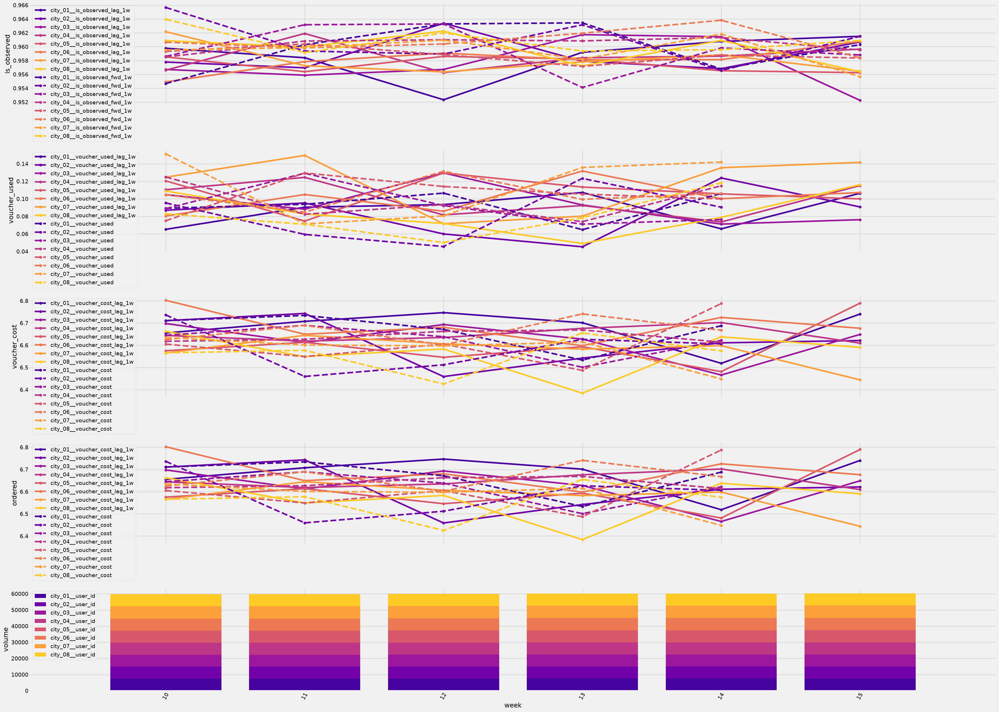

In [23]:
dynamic_results = (
    all_data
    .groupby([time_col, city_col])
    .agg({
        id_col: 'count',
        
        'is_observed_lag_1w': 'mean',
        'is_observed_fwd_1w': 'mean',

        'voucher_used': 'mean',
        'voucher_used_lag_1w': 'mean',
        'voucher_cost': 'mean',
        'voucher_cost_lag_1w': 'mean',
        
        'ordered': 'mean',
        'ordered_lag_1w': 'mean',
    })
    .unstack(-1)
)
# display(dynamic_results)


metrics = {
    'is_observed': [f'is_observed{suffix}' for suffix in ['_lag_1w', '_fwd_1w']],
    utilization_col: [f'{utilization_col}{suffix}' for suffix in ['_lag_1w', '']],
    cost_col: [f'{cost_col}{suffix}' for suffix in ['_lag_1w', '']],
    target_col: [f'{cost_col}{suffix}' for suffix in ['_lag_1w', '']],
    'volume': [id_col, ],    
}

segments = sorted(all_data[city_col].unique())

# palette = sns.diverging_palette(h_neg=230, h_pos=8, l = 55, s = 100, n=len(segments), as_cmap=False)[::-1]
palette = sns.color_palette('plasma', n_colors=len(segments), as_cmap=False)
# colormap = dict(zip(segments, palette,))
# segments_reordered_volume = (np.array(segments)[np.argsort(dynamic_results.loc[:, 'n_units'].mean(axis = 0))]).tolist()[::-1]

result = {}
fig, axes = plt.subplots(len(metrics), 1, sharex=True, figsize=(35, 5 * len(metrics)))
for ax, (metric_class, c_list) in zip(axes, metrics.items()):
    for ls, metric in zip(['-', '--', '-.', ], c_list):
        bottoms = pd.Series(0, dynamic_results.index)
        for segment_label, color in zip(segments, palette):
            # for segment_label in segments_reordered_volume:
            # color = colormap[segment_label]
            label = f"{segment_label.rstrip('_').lstrip('_') if segment_label.startswith('_') else segment_label}__{metric}"
            # label = f"{segment_label}__{metric}"
            if metric_class == 'volume':
                heights = dynamic_results.loc[:, (metric, segment_label)]
                ax.bar(
                    x=dynamic_results.index,
                    bottom=bottoms,
                    height=heights,
                    label=label,
                    # hatch = '-',
                    # marker = 'o', linestyle = ls,
                    color=color, alpha=1.0, width=0.8,
                )
                bottoms += heights
            else:
                ax.plot(
                    dynamic_results.index,
                    dynamic_results.loc[:, (metric, segment_label)],
                    label=label,
                    marker='o', linestyle=ls, color=color,
                )
    ax.set_ylabel(metric_class)
    ax.legend(loc='upper left')

ymin, ymax = axes[0].get_ylim()
axes[0].set_ylim(ymin, min(ymax, 3.0))
ymin, ymax = axes[1].get_ylim()
axes[1].set_ylim(max(-2.0, ymin), min(ymax, 2.0))

idx = dynamic_results.index.get_level_values(0).unique()

axes[-1].set_xlabel(time_col)

ax = axes[0]
ax.set_xticks(idx)
ax.margins(x=0.1)

xticks, xlabels = axes[-1].get_xticks(), axes[-1].get_xticklabels()
axes[-1].set_xticks(xticks)
axes[-1].set_xticklabels(xlabels, rotation=60)

plt.tight_layout()
plt.close()
display(fig)

# Splitting back into modelling and inference data

In [24]:
modelling_data = all_data.query("is_inference == 0").reset_index(drop = True)
inference_data = all_data.query("is_inference == 1").reset_index(drop = True)

Consistency check for lagged features and their alignment with already given user aggregates

In [25]:
print([c for c in modelling_data.columns if 'lag' in c])

mask = (modelling_data['is_observed_lag_1w'] == 0) & (modelling_data['orders_30d'] > 0)
print(sum(mask))
mask = (modelling_data['is_observed_lag_1w'] == 1) & (modelling_data['ordered_lag_1w'] == 1) & (modelling_data['days_since_last_order'] > 7)
print(sum(mask))
mask = (modelling_data['is_observed_lag_1w'] == 1) & (modelling_data['ordered_lag_1w'] == 1) & (modelling_data['days_since_last_order'] <= 7)
print(sum(mask))
mask = (modelling_data['is_observed_lag_1w'] == 1) & (modelling_data['ordered_lag_1w'] == 0) & (modelling_data['days_since_last_order'] <= 7)
print(sum(mask))

['voucher_pct_lag_1w', 'free_delivery_lag_1w', 'aov_90d_lag_1w', 'orders_90d_lag_1w', 'ordered_lag_1w', 'voucher_used_lag_1w', 'voucher_cost_lag_1w', 'is_observed_lag_1w']
6534
0
75618
0


# Estimating carryover effect and voucher x FD interaction effect

In [26]:
lagged_treatment_col = f"{treatment_col}_lag_1w"
lagged_aux_treatment_col = f"{aux_treatment_col}_lag_1w"

display(modelling_data[[target_col, time_col, treatment_col, aux_treatment_col, lagged_treatment_col, lagged_aux_treatment_col]].isna().mean().to_frame().T)

,ordered,week,voucher_pct,free_delivery,voucher_pct_lag_1w,free_delivery_lag_1w
0,0.0,0.0,0.0,0.0,0.041571,0.041571


Because we have non-0 inflow rate, some observations would not have **voucher_pct_lag_1w** observed and statsmodels is not able to treat missing values properly

Options we have:
- ignore such observations
- fill them with control value (0% voucher == no voucher at all really, right) under the assumption they couldn't experience it, because they're not a part of the experiment in a previous week - again we have to assume we have all experimental data with assignments available to us
- same as above but introduce additional flag explicitly saying it's new entrants and include it in the regresssion - this is actually equivalent to first option

It makes more sense to just exclude them because if they were not part of experiment earlier, there's no any carryover to even examine in the first place

In [27]:
alpha = 0.05

for formula in [
    f"{target_col} ~ C({time_col}) + {treatment_col} + {lagged_treatment_col}",
    f"{target_col} ~ C({time_col}) + C({treatment_col}) + C({lagged_treatment_col})",
]:
    print(formula)
    
    model = smf.ols(
        formula,
        data=modelling_data.query("is_observed_lag_1w == 1"),
    ).fit(
        cov_type="cluster", cov_kwds={"groups": modelling_data.query("is_observed_lag_1w == 1")[id_col]}
    )
    display(pd.concat([model.params, model.pvalues, model.conf_int(alpha=alpha)], axis = 1,).set_axis(['coef', 'p-value', 'ci_lower', 'ci_upper'], axis = 1))

ordered ~ C(week) + voucher_pct + voucher_pct_lag_1w


,coef,p-value,ci_lower,ci_upper
Intercept,0.212342,0.000000e+00,0.207326,0.217358
C(week)[T.11],-0.026981,3.561620e-33,-0.031388,-0.022574
C(week)[T.12],-0.029305,1.301008e-38,-0.033725,-0.024885
C(week)[T.13],-0.014177,2.864965e-10,-0.018583,-0.009770
C(week)[T.14],0.019074,4.403868e-17,0.014625,0.023524
voucher_pct,0.003274,0.000000e+00,0.003157,0.003392
voucher_pct_lag_1w,0.000043,4.614755e-01,-0.000072,0.000158


ordered ~ C(week) + C(voucher_pct) + C(voucher_pct_lag_1w)


,coef,p-value,ci_lower,ci_upper
Intercept,0.216360,0.000000e+00,0.210322,0.222398
C(week)[T.11],-0.026983,3.509753e-33,-0.031390,-0.022576
C(week)[T.12],-0.029303,1.306882e-38,-0.033723,-0.024884
C(week)[T.13],-0.014175,2.874240e-10,-0.018581,-0.009769
C(week)[T.14],0.019074,4.395346e-17,0.014624,0.023524
C(voucher_pct)[T.10],0.024944,3.388530e-24,0.020126,0.029762
C(voucher_pct)[T.20],0.056085,2.050614e-109,0.051138,0.061031
C(voucher_pct)[T.30],0.093465,1.951251e-285,0.088392,0.098539
C(voucher_pct)[T.40],0.129466,0.000000e+00,0.124241,0.134691
C(voucher_pct_lag_1w)[T.10.0],0.002762,2.869971e-01,-0.002322,0.007847


Also let's check the same with interaction model including Free Delivery

In [28]:
for formula in [
    f"{target_col} ~  C({time_col}) + {treatment_col} + {aux_treatment_col} + {treatment_col}*{aux_treatment_col} "
    f"+ {lagged_treatment_col} + {lagged_aux_treatment_col} +  {lagged_treatment_col} * {lagged_aux_treatment_col}",
]:
    print(formula)
    
    model = smf.ols(
        formula,
        data=modelling_data.query("is_observed_lag_1w == 1"),
    ).fit(
        cov_type="cluster", cov_kwds={"groups": modelling_data.query("is_observed_lag_1w == 1")[id_col]}
    )
    display(pd.concat([model.params, model.pvalues, model.conf_int(alpha=alpha)], axis = 1,).set_axis(['coef', 'p-value', 'ci_lower', 'ci_upper'], axis = 1))

ordered ~  C(week) + voucher_pct + free_delivery + voucher_pct*free_delivery + voucher_pct_lag_1w + free_delivery_lag_1w +  voucher_pct_lag_1w * free_delivery_lag_1w


,coef,p-value,ci_lower,ci_upper
Intercept,0.201188,0.000000e+00,0.194687,0.207690
C(week)[T.11],-0.027005,3.061032e-33,-0.031411,-0.022598
C(week)[T.12],-0.029320,1.133727e-38,-0.033739,-0.024902
C(week)[T.13],-0.014192,2.701935e-10,-0.018597,-0.009787
C(week)[T.14],0.019057,4.591823e-17,0.014609,0.023506
voucher_pct,0.003453,0.000000e+00,0.003291,0.003616
free_delivery,0.024020,6.086933e-19,0.018725,0.029316
voucher_pct:free_delivery,-0.000358,2.151996e-03,-0.000586,-0.000129
voucher_pct_lag_1w,0.000034,6.839066e-01,-0.000128,0.000195
free_delivery_lag_1w,-0.001663,5.579946e-01,-0.007225,0.003900


In both cases (treating vouchel levels as continuous or discrete) we're getting effect size for lagged voucher as insignificant (pvalues are much higher than alpha (Significance Level controlling for False Positives)) and both sides for Confidence Intervals are much smaller then effect size for non-lagged voucher and FD variables

We could also conclude that weekly interventions could be treated as separate independent exposures and also our policy could be indeed somewhat myopic (deciding only 1 week ahead)

In the long run we might want to run experiments directly testing long-term influence by tracking more than 1 week ahead from intervention, but we couldn't really extract this assessment properly from current experiment design, because the treatments that happened after the first (anchor) one also affect the total cumulative outcome - we would have an estimand "effect of intervention at t when following weeks would carry random offers", but that's likely not what we really want - external validity in production would likely not be holding up because we will not keep assigning next offers weekly by random after selecting the first optimal one, so this is not the estimand we want

We should either filter for only cases where following interventions are all 0s (week 9 - something, week 10 - 0%, week 11 - 0%, etc.) which would greatly reduce the sample size or condition on the following interventions (post-treatment covariates in this particular case) and then on inference set all those variables to 0% - both are bringing complexities, we would not go down this path now

Because currently discount assignments historically was randomized independently of previous week omiting the lagged variables in the model would not bias currently applied intervention effect, but it could reduce variance

Just above we checked that "last week's discount doesn't shift current week's level of orders averaged over this week's offers", but it could behave as a modifier of current discount - which would be important and still might help in identifying personal effect (unless the dataset size is small then inflating feature space would reduce power), but we'll check importance for such features during evaluation

Let's check the same with interaction term between the current treatment and the previous treatment

In [29]:
alpha = 0.05

for formula in [
    f"{target_col} ~ C({time_col}) + {treatment_col} + {lagged_treatment_col} + {treatment_col}*{lagged_treatment_col}",
    f"{target_col} ~ C({time_col}) + C({treatment_col}) + C({lagged_treatment_col}) + C({treatment_col}) * C({lagged_treatment_col})",
]:
    print(formula)
    
    model = smf.ols(
        formula,
        data=modelling_data.query("is_observed_lag_1w == 1"),
    ).fit(
        cov_type="cluster", cov_kwds={"groups": modelling_data.query("is_observed_lag_1w == 1")[id_col]}
    )
    display(pd.concat([model.params, model.pvalues, model.conf_int(alpha=alpha)], axis = 1,).set_axis(['coef', 'p-value', 'ci_lower', 'ci_upper'], axis = 1))

ordered ~ C(week) + voucher_pct + voucher_pct_lag_1w + voucher_pct*voucher_pct_lag_1w


,coef,p-value,ci_lower,ci_upper
Intercept,0.213846,0.000000e+00,0.208029,0.219663
C(week)[T.11],-0.026984,3.508519e-33,-0.031390,-0.022577
C(week)[T.12],-0.029309,1.269412e-38,-0.033729,-0.024889
C(week)[T.13],-0.014175,2.883425e-10,-0.018581,-0.009768
C(week)[T.14],0.019072,4.436075e-17,0.014623,0.023522
voucher_pct,0.003199,4.802588e-219,0.003001,0.003398
voucher_pct_lag_1w,-0.000032,7.377337e-01,-0.000220,0.000156
voucher_pct:voucher_pct_lag_1w,0.000004,3.628802e-01,-0.000004,0.000012


ordered ~ C(week) + C(voucher_pct) + C(voucher_pct_lag_1w) + C(voucher_pct) * C(voucher_pct_lag_1w)


,coef,p-value,ci_lower,ci_upper
Intercept,0.218028,0.000000e+00,0.209650,0.226405
C(week)[T.11],-0.026971,3.788197e-33,-0.031378,-0.022564
C(week)[T.12],-0.029314,1.246513e-38,-0.033734,-0.024894
C(week)[T.13],-0.014168,2.940026e-10,-0.018574,-0.009762
C(week)[T.14],0.019076,4.376165e-17,0.014626,0.023526
C(voucher_pct)[T.10],0.021781,6.849585e-05,0.011059,0.032503
C(voucher_pct)[T.20],0.052937,2.625218e-21,0.041989,0.063886
C(voucher_pct)[T.30],0.095809,3.768635e-62,0.084522,0.107096
C(voucher_pct)[T.40],0.125070,5.055966e-102,0.113639,0.136500
C(voucher_pct_lag_1w)[T.10.0],0.002477,6.453916e-01,-0.008075,0.013030


Finally let's check whether population weekly outflow is somehow related to treatment assignments:

In [30]:
alpha = 0.05

for formula in [
    f"is_observed_fwd_1w ~ {treatment_col} + {aux_treatment_col} + {treatment_col}*{aux_treatment_col}",
]:
    print(formula)
    
    model = smf.ols(
        formula,
        data=modelling_data,
    ).fit(
        cov_type="cluster", cov_kwds={"groups": modelling_data[id_col]}
    )
    display(pd.concat([model.params, model.pvalues, model.conf_int(alpha=alpha)], axis = 1,).set_axis(['coef', 'p-value', 'ci_lower', 'ci_upper'], axis = 1))

is_observed_fwd_1w ~ voucher_pct + free_delivery + voucher_pct*free_delivery


,coef,p-value,ci_lower,ci_upper
Intercept,0.960177,0.000000,0.958465,0.961890
voucher_pct,-0.000016,0.644899,-0.000086,0.000053
free_delivery,0.000438,0.721503,-0.001972,0.002848
voucher_pct:free_delivery,0.000015,0.761443,-0.000083,0.000113


From these results it seems to not be the driving factor

# Dealing with Free Delivery

The original treatment design experiment has is a 5 (discount) × 2 (FD). 

Such randomization allows to identify the discount effect, the FD effect, and their potential interaction. 

Since FD is outside of our control during inference, the central question is whether we should average FD (and its effect) out or try to condition on it.

- Approach 1: We aggregate the FD levels together treating FD as nuisance variable, keep discount as the only treatment choice we need to optimize with.

    - It's simple, robust, easy to explain, twice the sample size per discount variant and will be valid if the future FD distribution matches the experimental 50%/50% split
The downside is estimates would be averaged over a mixture of with 50%/50% FD mix. If FD assignment during inference/production is different or correlated with user type, the optimal discount assignment would be miscalibrated. Discount and FD likely substitute (both lower effective price) each other and pooling would hide this. It's hard to know how much we're wrong this way without checking the interaction level.
<br>

- Approach 2: We treat FD as a covariate and model conditional uplift with it as additional input. At inference time we just plug in the supplied FD value (either known or predicted and choose the best discount treatment conditional on it.

    - This way we potentially capture the discount × FD interaction (if delivery is free the effect of a 10 % discount probably shrinks, it also might handle the dependency between FD and user context, experiment data would still be causal for discount treatment because it was randomized within each FD level. Estimates might become noisier, and we might need regularization to not overfit. We also need FD to be known or predictable at decision time (or model it probabilistically). The biggest risk here is that at inference time FD becomes driven by a completely unobserved confounder.
<br>

- Approach 3*: Additionally, we might apply direct policy learning with a model for the FD assignment mechanism, in case during production phase it's not known to us, non-deterministic and/or is different from the experimental data.

    - We model inference FD assignment as P(FD | X), then average the conditional model over it: $E_{FD}[value(X, d, FD)] = Σ_{FD} P(FD|X) * value(X, d, FD)$. We then optimize the discount against this expected value, or learn the policy directly via libraries like policytree, EconML DRPolicyForest, with reweighting toward the FD distribution at inference time. This approach is worth it when FD is uncertain at inference time from our side (which is not the case here) and reweighting aligns the experiment's 50%/50% FD split with inference. Policy trees will give interpretable, constrained rules. This is the most complex option though - we would have two models, errors in P(FD | X) would propagate to the policy, we might needs additional info (logs) on FD assignment in production and might face feature space insufficient overlap (positivity violation). And it would still be required that the discount × FD interaction effect holds between experiment and later inference (same communication delivery, etc).

We would first test whether the interaction matters. If such effect is negligible, we might proceed with Approach 1 and it would be sufficient.

Ultimately, our decision making on inference will be independent of FD assignment in the first case and might affect discount assignments across users in the second.

In [31]:
alpha = 0.05

# formula = f"{target_col} ~ {treatment_col} + {aux_treatment_col} + {treatment_col}*{aux_treatment_col}",
formula = f"{target_col} ~ C({treatment_col}) * {aux_treatment_col}"

print(formula)
model = smf.ols(
    formula,
    data=modelling_data,
).fit(
    cov_type="cluster", cov_kwds={"groups": modelling_data[id_col]}
)
display(pd.concat([model.params, model.pvalues, model.conf_int(alpha=alpha)], axis = 1,).set_axis(['coef', 'p-value', 'ci_lower', 'ci_upper'], axis = 1))

### applying joint Wald test of the 4 discount x fd interaction terms
### test whether a set of coefficients is jointly equal to zero (Rθ = 0).
### how far are the 4 interaction estimates from zero in units of their joint uncertainty
names = [n for n in model.params.index if ":" in n] ### fetching interaction terms
R = np.zeros((len(names), len(model.params)))
for i, n in enumerate(names):
    R[i, list(model.params.index).index(n)] = 1
print(model.wald_test(R, scalar=True))

ordered ~ C(voucher_pct) * free_delivery


,coef,p-value,ci_lower,ci_upper
Intercept,0.196362,0.000000e+00,0.191561,0.201162
C(voucher_pct)[T.10],0.025549,1.992378e-14,0.019004,0.032094
C(voucher_pct)[T.20],0.059492,1.107606e-66,0.052732,0.066251
C(voucher_pct)[T.30],0.098687,9.145695e-172,0.091764,0.105611
C(voucher_pct)[T.40],0.135234,1.663749e-306,0.128151,0.142317
free_delivery,0.022989,4.567727e-12,0.016476,0.029502
C(voucher_pct)[T.10]:free_delivery,-0.002205,6.449489e-01,-0.011585,0.007175
C(voucher_pct)[T.20]:free_delivery,-0.007130,1.464848e-01,-0.016753,0.002494
C(voucher_pct)[T.30]:free_delivery,-0.011233,2.499654e-02,-0.021055,-0.001411
C(voucher_pct)[T.40]:free_delivery,-0.012240,1.633364e-02,-0.022229,-0.002250


<Wald test (chi2): statistic=9.080228759761695, p-value=0.05912513001738576, df_denom=4>


p-value is ever so slightly higher than our significance level, let's also check interaction level visually

ordered          
free_delivery         0         1
voucher_pct                      
0              0.196362  0.219351
10             0.221911  0.242694
20             0.255854  0.271713
30             0.295049  0.306806
40             0.331596  0.342345

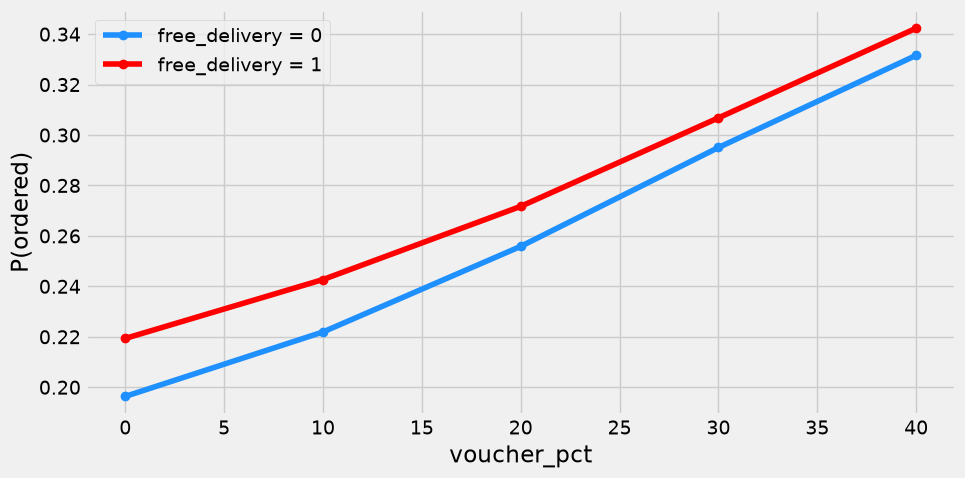

In [32]:
gb = (
    modelling_data
    .groupby([treatment_col, aux_treatment_col])
    .agg({target_col: 'mean'})
    .unstack(1)
)
display(gb)
fig, ax = plt.subplots(1,1, figsize = (10, 5))
gb.iloc[:, 0].plot(ax = ax, color = 'dodgerblue', marker = 'o', label = "free_delivery = 0")
gb.iloc[:, 1].plot(ax = ax, color = 'red', marker = 'o', label = "free_delivery = 1")
ax.set_ylabel(f'P({target_col})')
ax.legend()
plt.close()
display(fig)

We do see that the P(ordered|D = d) curves converge closer to each other on higher discounts (starting at 20%), before that they're parallel
This means that free delivery affect conversion stronger on lower discounts or no discount, but as discount value grows the FD effect diminishes and they become substitutes for each other 

# Continuous vs Discrete Treatment

Technically, problem could be framed both ways but we will go with discrete approach as we already have some tooling ready for it

We also don't expect to have the need of extrapolation outside of current discount range, as well as interpolation

# Modelling 

We'll be modelling Conditional Average Treatment Effect using data from historical customer features + last week lagged interventions, meta-learners and causal-tree based approaches

Some tools we're gonna be using expect discrete treatment levels and also requires them to be ordered sequentially starting from 0 (baseline, control level) 

We will convert treatment labels now

In [33]:
modelling_data[treatment_col] = modelling_data[treatment_col].astype(int).astype(str)

treatment_levels = sorted(modelling_data[treatment_col].unique())

### from
levels_mapping = {v: i for i, v in enumerate(treatment_levels)}

### from 0,1,..., int to original treatment level
labels_mapping = {v: k for k, v in levels_mapping.items()}

treatment_labels = list(labels_mapping)

modelling_data[treatment_col] = modelling_data[treatment_col].map(levels_mapping)

CONTROL_LABEL = 0

print(levels_mapping, labels_mapping)

{'0': 0, '10': 1, '20': 2, '30': 3, '40': 4} {0: '0', 1: '10', 2: '20', 3: '30', 4: '40'}


## Dynamic view on target rate split by treatment

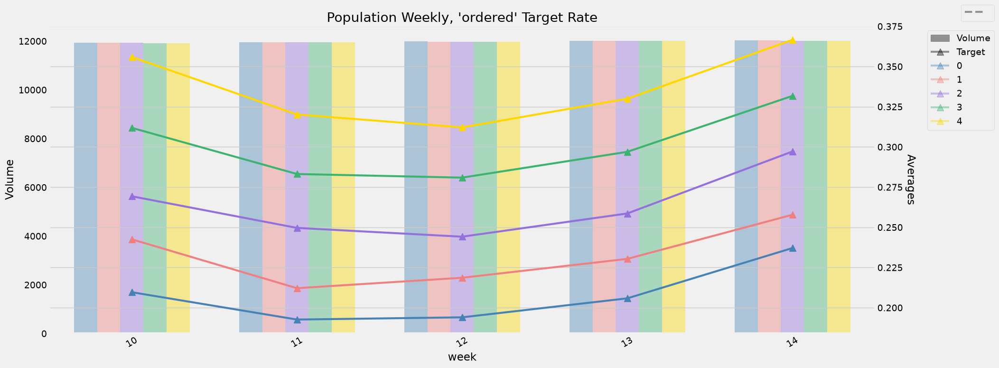

In [34]:
from pulsar.visualization.dynamic import get_metrics_dynamic, plot_metrics_dynamic

dynamic_aggregates = get_metrics_dynamic(
    data = modelling_data.loc[:, [time_col, target_col, treatment_col]],
    # timestamp_col = time_col,
    timestamp_col = None,
    group_col = time_col,
    target_col = target_col,
    score_col = None,
    treatment_col = treatment_col,
    weight_col = None,
    control_label = 0,
    metrics = None,
    freq = None,
    timestamp_format = None,
    verbose = False,
)


fig, ax = plot_metrics_dynamic(
    aggregates = dynamic_aggregates,
    figsize = (20, 8),
    metrics = [],
    one_axis_per_metric = True,
    n_reserved_axes = 0
)
ax[0].set_title(f"Population Weekly, '{target_col}' Target Rate")
ax[0].set_xlabel(time_col)
display(fig)

## Train-test split

In [35]:
from src.utils import set_seed

seed = 8
p_train = 0.8

all_ids = sorted(modelling_data[id_col].unique())
n_ids = len(all_ids)
n_ids_train = int(n_ids * p_train)

set_seed(seed)
ids_train = set(np.random.choice(all_ids, size = n_ids_train, replace = False))
n_ids_train = len(ids_train)
ids_test = set(all_ids) - ids_train
n_ids_test = len(ids_test)

print(f"total unique ids: {n_ids}, train ids: {n_ids_train}, test ids: {n_ids_test}")

total unique ids: 62604, train ids: 50083, test ids: 12521


In [36]:
from atlas.interfaces import SampleKeeper

train_sample_key = 'train'

TARGET_VALUES_SET = {0, 1}
s_keeper = SampleKeeper()

train_mask = modelling_data[id_col].isin(ids_train)
test_mask = modelling_data[id_col].isin(ids_test)

train_period_mask = (modelling_data[time_col] < 14)
s_keeper['train'] = modelling_data.loc[train_period_mask & train_mask, :]

test_period_mask = (modelling_data[time_col] < 14)
s_keeper['test'] = modelling_data.loc[test_period_mask & test_mask, :]

oot_period_mask = (modelling_data[time_col] >= 14)
s_keeper['oot'] = modelling_data.loc[oot_period_mask, :]
s_keeper['holdout'] = modelling_data.loc[oot_period_mask & test_mask, :]

Failed to import duecredit due to No module named 'duecredit'


In [37]:
from atlas.descriptive import check_data_overlap

for primary_keys in ([id_col, ], [id_col, time_col]):
    intersections = {}
    for i, (x, y) in enumerate(itertools.combinations(s_keeper.active, 2)):
        intersections[f'{x}-{y}'] = check_data_overlap(s_keeper[x], s_keeper[y], primary_keys, x, y)
        print(intersections[f'{x}-{y}']['summary'])

there are 0 unique data points overlap between train and test by ['user_id']
there are 47981 unique data points overlap between train and oot by ['user_id']
there are 0 unique data points overlap between train and holdout by ['user_id']
there are 11982 unique data points overlap between test and oot by ['user_id']
there are 11982 unique data points overlap between test and holdout by ['user_id']
there are 12008 unique data points overlap between oot and holdout by ['user_id']
there are 0 unique data points overlap between train and test by ['user_id', 'week']
there are 0 unique data points overlap between train and oot by ['user_id', 'week']
there are 0 unique data points overlap between train and holdout by ['user_id', 'week']
there are 0 unique data points overlap between test and oot by ['user_id', 'week']
there are 0 unique data points overlap between test and holdout by ['user_id', 'week']
there are 12008 unique data points overlap between oot and holdout by ['user_id', 'week']


## Handling features

### Categorical features

In [38]:
from atlas.encoders import CategoricalEncoder

cat_encoded_features = set()
cat_encoder = CategoricalEncoder(
    cat_na_fill_value = '0_MISSING_VALUE',
    map_unknown_to_na = True,
    seek_categorical_from_int = False,
    verbose = False,
    enforce_string = False,
)
cat_encoder.fit(s_keeper[train_sample_key], cat_features = cat_feature_cols)

s_keeper.drop_columns(col_name = cat_encoder.features_encoded)

for k in tqdm(s_keeper.active):
    cat_df = cat_encoder.transform(
        s_keeper[k],
        transform_inplace = False,
        return_features = False,
    )
    cat_encoded_features.update(list(cat_df.columns))
    s_keeper[k] = pd.concat([s_keeper[k], cat_df], axis = 1)

cat_encoded_features = list(cat_encoded_features)
print(cat_encoded_features)

### also transform for inference data in advance
cat_df = cat_encoder.transform(
    inference_data,
    transform_inplace = False,
    return_features = False,
)
inference_data = pd.concat([inference_data, cat_df], axis = 1)

  0%|          | 0/4 [00:00<?, ?it/s]

['city_ENCODED']


In [39]:
additional_features = [
    f"{c}_lag_1w" for c in lagged_features
]
print(additional_features)

['voucher_pct_lag_1w', 'free_delivery_lag_1w', 'aov_90d_lag_1w', 'orders_90d_lag_1w', 'ordered_lag_1w', 'voucher_used_lag_1w', 'voucher_cost_lag_1w']


In [40]:
s_keeper.set_markup(
    target_name = target_col,
    treatment_name = treatment_col,
    date_main_field = time_col,
    id_field = id_col,
    all_features = (
        []
        + num_feature_cols
        + additional_features
        + cat_encoded_features
        + [aux_treatment_col]
    ),
    cat_features = cat_encoded_features,
)
print(s_keeper.all_features)

['orders_90d', 'orders_30d', 'days_since_last_order', 'aov_90d', 'pct_orders_with_promo_90d', 'avg_voucher_pct_received_90d', 'voucher_redemption_rate_90d', 'manual_voucher_entry_rate_90d', 'sessions_30d', 'days_since_last_session', 'push_opt_in', 'offers_tab_share_of_sessions_30d', 'voucher_pct_lag_1w', 'free_delivery_lag_1w', 'aov_90d_lag_1w', 'orders_90d_lag_1w', 'ordered_lag_1w', 'voucher_used_lag_1w', 'voucher_cost_lag_1w', 'city_ENCODED', 'free_delivery']


## Dynamic features' distribution

  0%|          | 0/21 [00:00<?, ?it/s]

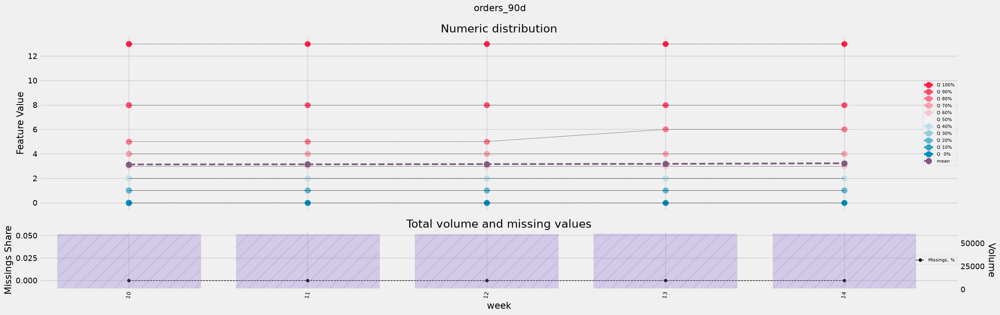

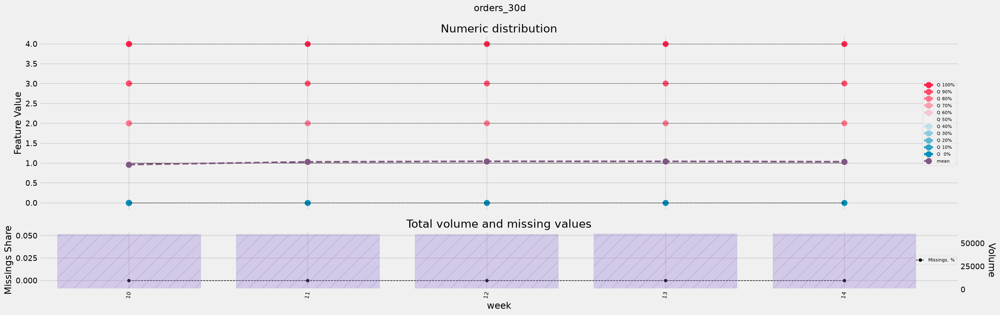

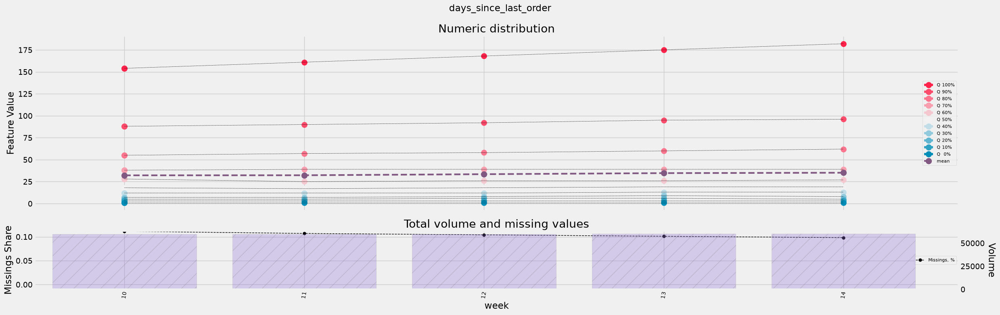

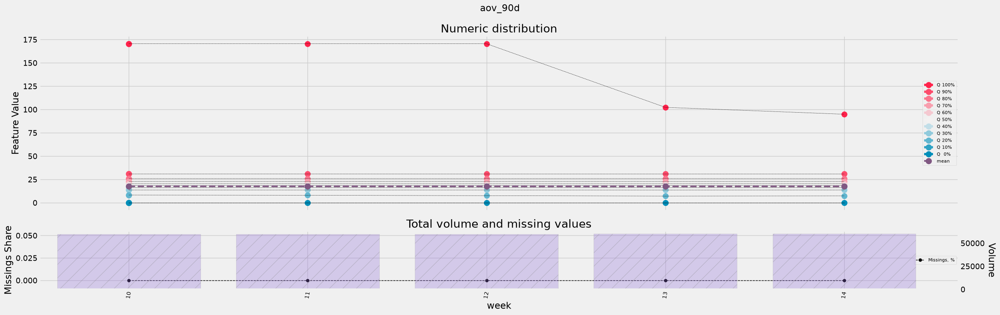

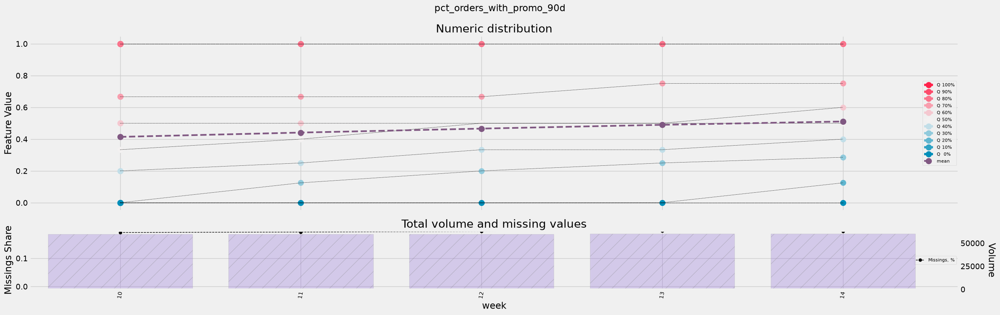

...

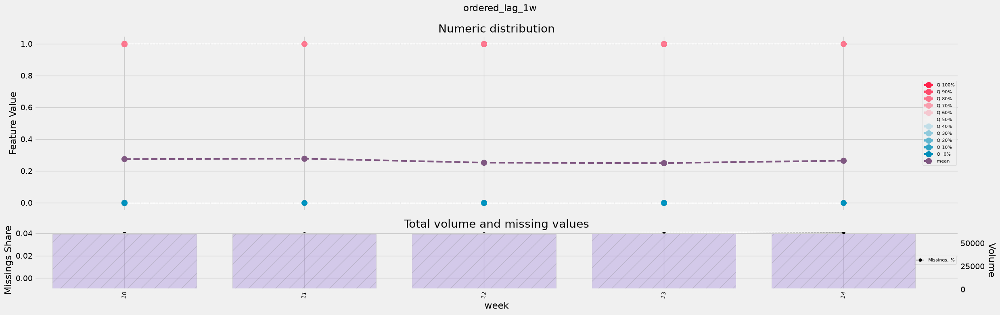

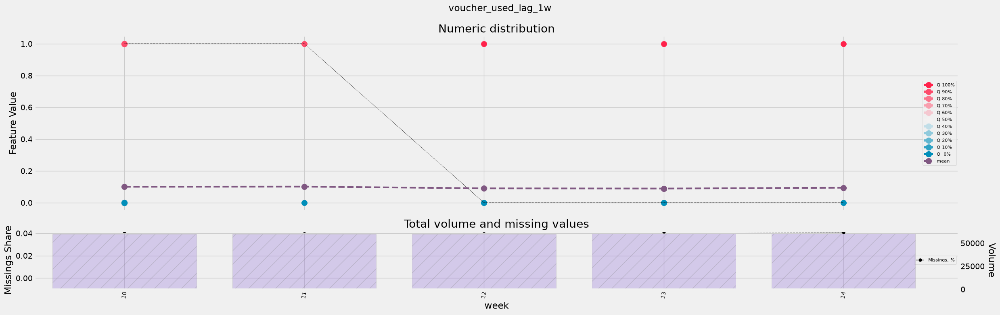

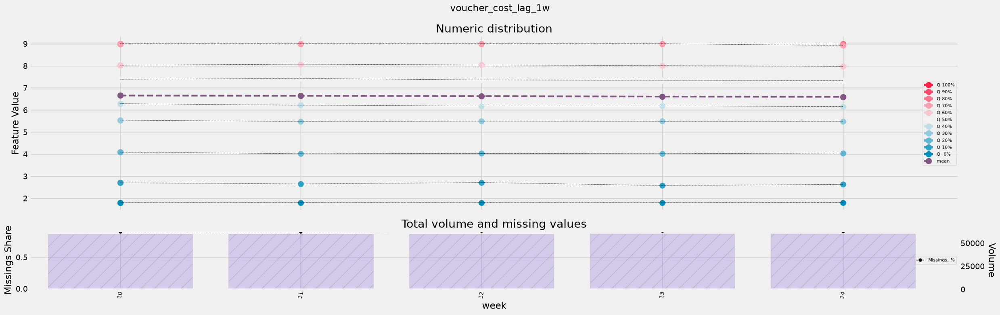

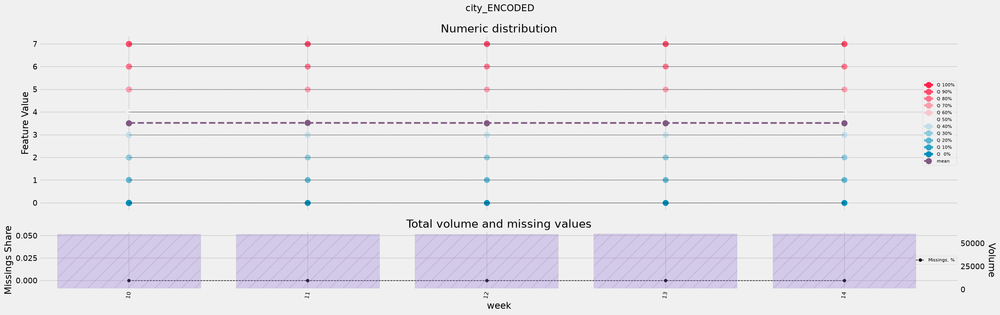

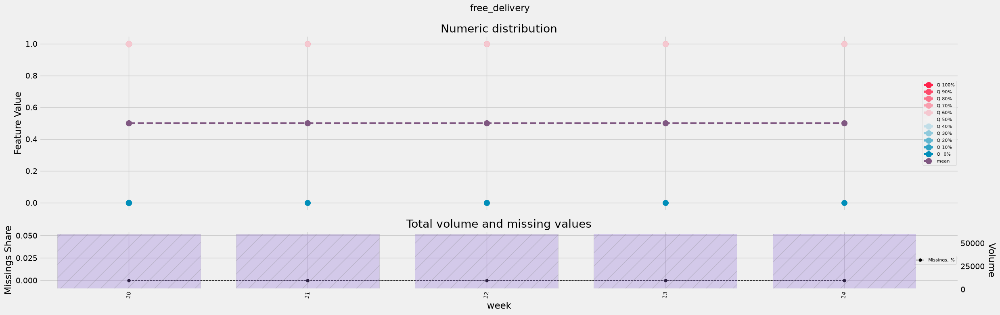

In [41]:
from pulsar.visualization.dynamic import get_distribution_dynamic

for f in tqdm(s_keeper.all_features):
    
    dynamic_results = get_distribution_dynamic(
        data = s_keeper.get_X(['train', 'test', 'oot'], features = s_keeper.all_features + [time_col]),
        timestamp_col = time_col,
        metric_col = f,
        quantiles = 10,
        grouping = False,
        freq = None,
        timestamp_format = None,
        figsize = (25, 8),
    )
    display(dynamic_results['figure'])

We could see from there that for all features distribution is actually quite stable in time, and we would additionally check the same for inference dataset on the features that would be selected in the final model

## Propensity model, assignment randomization check

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

propensity_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=50, n_jobs=3, random_state=8)
propensity_proba = cross_val_predict(
    estimator = propensity_model,
    X = s_keeper.get_X('train'), 
    y = s_keeper.get_T('train'), ### we're trying to predict treatment here, not actual outcome
    cv = GroupKFold(3),
    groups = s_keeper.get_id('train'),
    method = 'predict_proba',
)

display(propensity_proba)

array([[0.20937289, 0.20267712, 0.18036795, 0.19046057, 0.21712146],
       [0.19986846, 0.20153881, 0.19334181, 0.19013873, 0.21511219],
       [0.21461085, 0.18543866, 0.21765575, 0.19625683, 0.18603791],
       ...,
       [0.18294161, 0.20764213, 0.19604977, 0.2028054 , 0.2105611 ],
       [0.19222608, 0.20061404, 0.19226134, 0.20512766, 0.20977088],
       [0.19241201, 0.19101199, 0.20418687, 0.21385338, 0.19853575]])

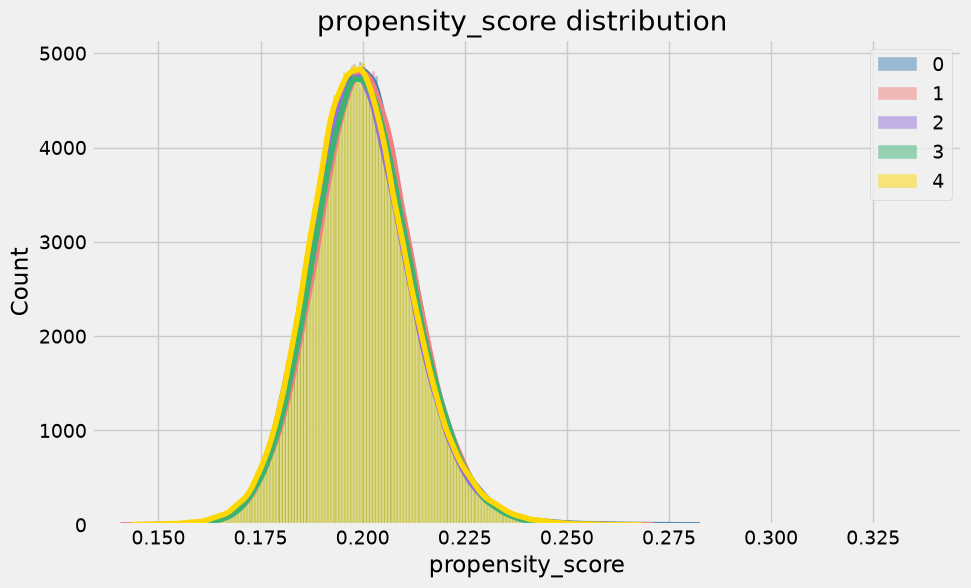

0.5008522308275728 1.6112113566442545 1.6094343715689214


In [43]:
from sklearn.metrics import roc_auc_score, log_loss

from pulsar.visualization import plot_metric_distribution_by_classes

propensity_proba_melt = pd.DataFrame(propensity_proba, columns = treatment_labels).melt()
propensity_proba_melt.columns = [treatment_col, 'propensity_score']

fig, ax = plot_metric_distribution_by_classes(data=propensity_proba_melt, class_name=treatment_col, metric_name='propensity_score')
display(fig)

t = s_keeper.get_T('train')

baseline = np.tile(np.bincount(t) / len(t), (len(t), 1)) ### using just global treatment classes shares as predictors for all treatment assignments

ll_proba = log_loss(t, propensity_proba)
ll_baseline = log_loss(t, baseline)
auc = roc_auc_score(t, propensity_proba, multi_class = 'ovr', average = 'macro')
print(auc, ll_proba, ll_baseline)

We could see that not only for all classes their predictive distributions closely packed around 0.2 (their share in population), but both ROC-AUC is very close to 50% - model couldn't learn anything and just as good as random and also log-loss value for this multiclass problem is also very close to the measurement from dummy baseline model

We could additionally perform permutation tests, but in my experience current readings are already conslusive enough 

So we establish that treatment assignment was indeed completely random

## Check FD assignment logic for inference data


We now repeat the procedure to understand whether FD treatment assignment was random or the process could be described by the feature set X

array([[0.50745088, 0.49254912],
       [0.52297805, 0.47702195],
       [0.52492619, 0.47507381],
       ...,
       [0.48823308, 0.51176692],
       [0.46775887, 0.53224113],
       [0.49914078, 0.50085922]])

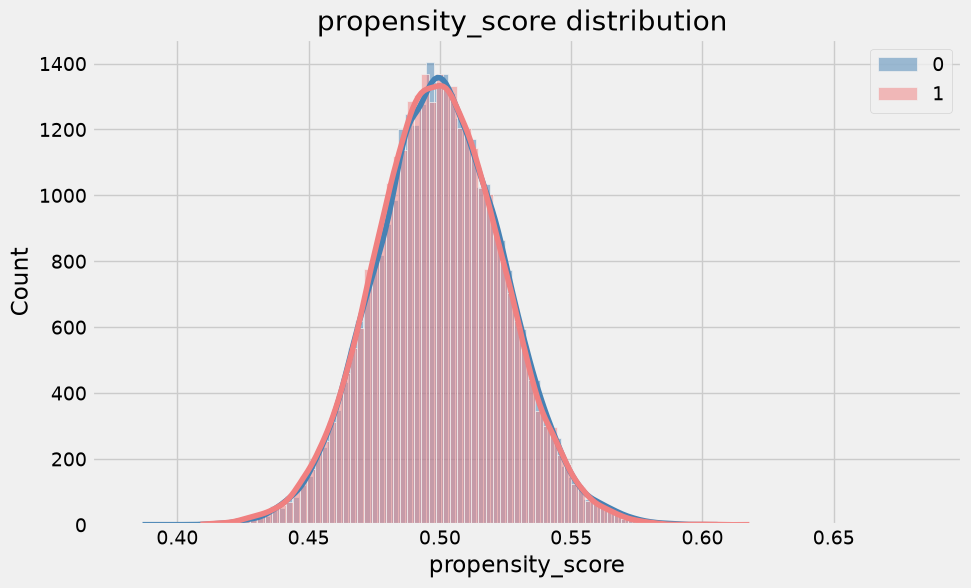

ROC-AUC:0.4921820875565737


In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

propensity_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=50, n_jobs=3, random_state=8)
propensity_proba = cross_val_predict(
    estimator = propensity_model,
    X = inference_data[[f for f in s_keeper.all_features if f != aux_treatment_col]],
    y = inference_data[aux_treatment_col], ### we're trying to predict treatment here, not actual outcome
    cv = GroupKFold(3),
    groups = inference_data[id_col],
    method = 'predict_proba',
)
display(propensity_proba)
propensity_proba = propensity_proba[:, 1] ### since it's binary treatment we could take probabilities for a second class only
t = inference_data[aux_treatment_col]

propensity_proba_melt = pd.DataFrame({'propensity_score': propensity_proba, aux_treatment_col: t})

fig, ax = plot_metric_distribution_by_classes(data=propensity_proba_melt, class_name=aux_treatment_col, metric_name='propensity_score')
display(fig)

auc = roc_auc_score(t, propensity_proba)
print(f"ROC-AUC:{auc}")

So apparently it might be random again (at least not described by a feature set X at hand), and also the split is 50%/50% again which together is quite convenient for us and we could expect that policy evaluation results that we would get on OOT sample (week 14) would extrapolate well on week 15 assuming no unobserved confounding is present

## Univariate Feature Analysis

In [45]:
from atlas.uplift.modelling import get_top_uplift_features

n_top_features = 100

### using wrappers around causalml.FilterSelect to understand which features perform best for univariate CATE identification on a treatment_i-vs-control pairwise comparison
feature_selection_results = get_top_uplift_features(
    data = s_keeper[train_sample_key],
    target_name = s_keeper.target_name,
    treatment_name = s_keeper.treatment_name,
    features = s_keeper.all_features,
    na_filler = -3,
    selection_methods = None,
    n_top = n_top_features,
    control_label = CONTROL_LABEL,
)

display(feature_selection_results['ranking'])

uplift_selected_features = list(feature_selection_results['ranking'].index[:n_top_features])

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

1                                 2  \
                                 rank_F rank_KL rank_ED   avg_rank rank_F   
feature                                                                     
pct_orders_with_promo_90d           3.0     1.0     2.0   2.000000    2.0   
voucher_redemption_rate_90d         1.0     5.0     1.0   2.333333    1.0   
orders_90d                          9.0     3.0     4.0   5.333333    9.0   
manual_voucher_entry_rate_90d       6.0     8.0     7.0   7.000000    3.0   
aov_90d                             4.0    10.0     6.0   6.666667    4.0   
orders_90d_lag_1w                   7.0     4.0     5.0   5.333333   12.0   
avg_voucher_pct_received_90d       17.0     2.0     3.0   7.333333   16.0   
aov_90d_lag_1w                      5.0    11.0     8.0   8.000000    7.0   
days_since_last_order              10.0     7.0    10.0   9.000000   10.0   
orders_30d                         11.0     6.0    13.0  10.000000   11.0   
offers_tab_share_of_sessions_30d   14.0    12.0     9.0  11.666667    8.0   
voucher_used_lag_1w                 8.0    13.0    11.0  10.666667   15.0   
sessions_30d                       13.0    15.0    12.0  13.333333   13.0   
ordered_lag_1w                     12.0     9.0    16.0  12.333333   19.0   
voucher_cost_lag_1w                 2.0    19.0    19.0  13.333333    5.0   
days_since_last_session            21.0    16.0    15.0  17.333333   14.0   
push_opt_in                        18.0    19.0    19.0  18.666667    6.0   
city_ENCODED                       19.0    14.0    14.0  15.666667   17.0   
voucher_pct_lag_1w                 15.0    17.0    17.0  16.333333   18.0   
free_delivery                      20.0    19.0    19.0  19.333333   20.0   
free_delivery_lag_1w               16.0    21.0    21.0  19.333333   21.0   

                                                                 3          \
                                 rank_KL rank_ED   avg_rank rank_F rank_KL   
feature                                                                      
pct_orders_with_promo_90d            1.0     2.0   1.666667    1.0     1.0   
voucher_redemption_rate_90d          5.0     1.0   2.333333    3.0     5.0   
orders_90d                           3.0     4.0   5.333333   12.0     3.0   
manual_voucher_entry_rate_90d        8.0     7.0   6.000000    4.0     8.0   
aov_90d                             10.0     6.0   6.666667    2.0    10.0   
orders_90d_lag_1w                    4.0     5.0   7.000000   15.0     4.0   
avg_voucher_pct_received_90d         2.0     3.0   7.000000   19.0     2.0   
aov_90d_lag_1w                      11.0     8.0   8.666667    5.0    11.0   
days_since_last_order                7.0    10.0   9.000000   13.0     7.0   
orders_30d                           6.0    13.0  10.000000   11.0     6.0   
offers_tab_share_of_sessions_30d    12.0     9.0   9.666667    9.0    12.0   
voucher_used_lag_1w                 13.0    11.0  13.000000   14.0    13.0   
sessions_30d                        15.0    12.0  13.333333    8.0    15.0   
ordered_lag_1w                       9.0    16.0  14.666667   17.0     9.0   
voucher_cost_lag_1w                 19.0    19.0  14.333333    7.0    19.0   
days_since_last_session             16.0    15.0  15.000000   10.0    16.0   
push_opt_in                         19.0    19.0  14.666667    6.0    19.0   
city_ENCODED                        14.0    14.0  15.000000   18.0    14.0   
voucher_pct_lag_1w                  17.0    17.0  17.333333   20.0    17.0   
free_delivery                       19.0    19.0  19.333333   16.0    19.0   
free_delivery_lag_1w                21.0    21.0  21.000000   21.0    21.0   

                                                         4                  \
                                 rank_ED   avg_rank rank_F rank_KL rank_ED   
feature                                                                      
pct_orders_with_promo_90d            2.0   1.333333    1.0     1.0     2.0   
vouc

It's interesting that FD feature is being ranked as the worst one - let's try to see why is that the case

In [46]:
gb = (
    s_keeper[train_sample_key]
    .groupby([treatment_col, aux_treatment_col])
    .agg({
        id_col: ['nunique',],
        target_col: ['mean',],
    })
)
display(gb.T)
print("we had similar view before in the very beginning - it's obvious that FD increases conversion for every voucher treatment level")


print("but this test measures a different thing - how well we could differentiate AVERAGE TREATMENT EFFECT (treatment - control difference) in subgroups when we condition on this feature")
gb_u = gb[target_col].unstack(0)
display(gb_u)
for c in gb_u.columns[1:]:
    gb_u.loc[:, c] = gb_u.loc[:, c] - gb_u.loc[:, gb_u.columns[0]]
gb_u = gb_u.iloc[:, 1:]
gb_u.columns = pd.MultiIndex.from_product([['ATE'], gb_u.columns.get_level_values(1)])
gb_diff = gb_u.diff(axis = 0).iloc[-1].to_frame().T
gb_diff.index = ['diff']
gb_u = pd.concat([gb_u, gb_diff], axis = 0)
display(gb_u)

print("we could see subgroups ATEs are quite close, let's compare with 'push_opt_in' which is being ranked higher")
col = 'push_opt_in'
gb = (
    s_keeper[train_sample_key]
    .groupby([treatment_col, col])
    .agg({
        id_col: ['nunique',],
        target_col: ['mean',],
    })
)
gb_u = gb[target_col].unstack(0)
for c in gb_u.columns[1:]:
    gb_u.loc[:, c] = gb_u.loc[:, c] - gb_u.loc[:, gb_u.columns[0]]
gb_u = gb_u.iloc[:, 1:]
gb_u.columns = pd.MultiIndex.from_product([['ATE'], gb_u.columns.get_level_values(1)])
gb_diff = gb_u.diff(axis = 0).iloc[-1].to_frame().T
gb_diff.index = ['diff']
gb_u = pd.concat([gb_u, gb_diff], axis = 0)
display(gb_u)

print("it's quite obvious that ATE (difference with control for each treatment level) changes quite significantly when we shift across feature levels,\nesp. for higher discount groups - which is logical")

voucher_pct                0                          1                \
free_delivery              0             1            0             1   
user_id nunique  16574.00000  16468.000000  16626.00000  16578.000000   
ordered mean         0.19223      0.211914      0.21336      0.234653   

voucher_pct                 2                           3                \
free_delivery               0             1             0             1   
user_id nunique  16485.000000  16594.000000  16571.000000  16500.000000   
ordered mean         0.246425      0.261708      0.287688      0.298935   

voucher_pct                 4                
free_delivery               0             1  
user_id nunique  16514.000000  16475.000000  
ordered mean         0.325825      0.335223

we had similar view before in the very beginning - it's obvious that FD increases conversion for every voucher treatment level
but this test measures a different thing - how well we could differentiate AVERAGE TREATMENT EFFECT (treatment - control difference) in subgroups when we condition on this feature


mean                                        
voucher_pct           0         1         2         3         4
free_delivery                                                  
0              0.192230  0.213360  0.246425  0.287688  0.325825
1              0.211914  0.234653  0.261708  0.298935  0.335223

ATE                              
voucher_pct         1         2         3         4
0            0.021130  0.054196  0.095458  0.133595
1            0.022740  0.049794  0.087021  0.123309
diff         0.001609 -0.004402 -0.008437 -0.010286

we could see subgroups ATEs are quite close, let's compare with 'push_opt_in' which is being ranked higher


ATE                              
voucher_pct         1         2         3         4
0            0.018234  0.028242  0.048908  0.062852
1            0.023693  0.060966  0.107751  0.153791
diff         0.005460  0.032724  0.058843  0.090939

it's quite obvious that ATE (difference with control for each treatment level) changes quite significantly when we shift across feature levels,
esp. for higher discount groups - which is logical


At the same time we have **orders_90d** in top-3, let's see why is that

size: 191404
min: 0, max: 13, mean: 3.155210967377902, std: 3.0690560763733914
# missings: 0, # unique: 14


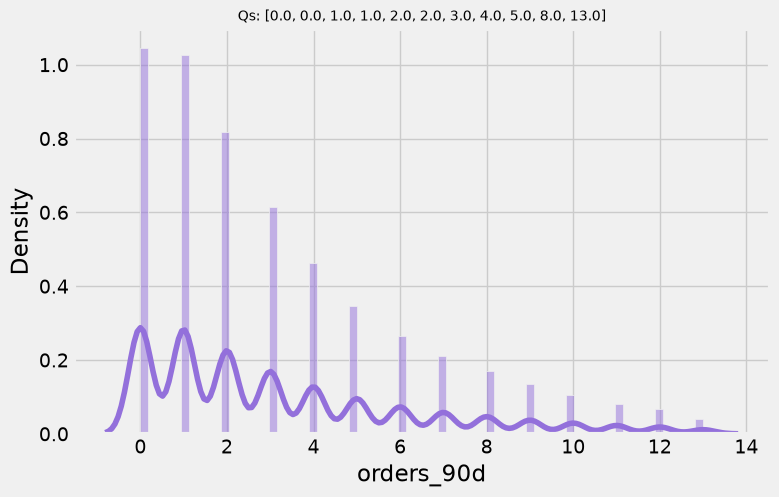

In [47]:
from pulsar.discovery import check_distr
display(check_distr(s_keeper[train_sample_key]['orders_90d'])['figure'])

ordered                                        
voucher_pct                0         1         2         3         4
orders_90d_clipped                                                  
0                   0.039743  0.041548  0.055216  0.072635  0.093746
1                   0.072366  0.079168  0.105919  0.135385  0.181153
2                   0.110136  0.137434  0.158347  0.222712  0.281575
3                   0.161085  0.188094  0.241506  0.286267  0.341176
4                   0.209572  0.252306  0.303329  0.369664  0.394720
5                   0.277433  0.326380  0.396812  0.421223  0.456349
6                   0.352662  0.418211  0.470364  0.506610  0.534872
7                   0.428856  0.487112  0.530356  0.546588  0.588157
8                   0.678949  0.688478  0.700810  0.732648  0.746974

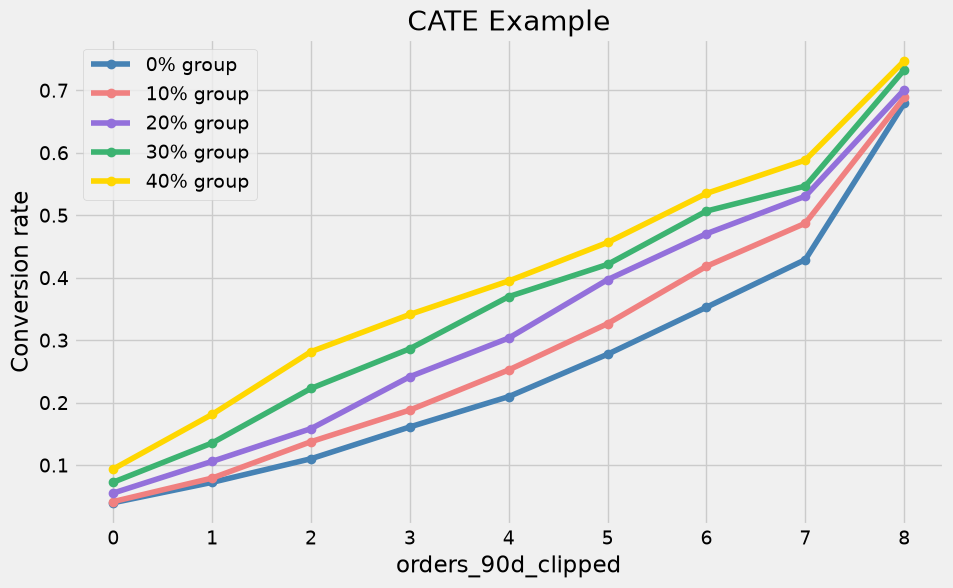

In [48]:
from pulsar.visualization.constants import VARIANTS_COLORS

d = pd.DataFrame({
    'orders_90d_clipped': s_keeper[train_sample_key]['orders_90d'].clip(upper = 8),
    treatment_col: s_keeper[train_sample_key][treatment_col],
    target_col: s_keeper[train_sample_key][target_col],
})
gb = (
    d
    .groupby(['orders_90d_clipped', treatment_col])
    .agg({
        target_col: 'mean',
    })
    .unstack(1)
)
display(gb)

fig, ax = plt.subplots(figsize = (10, 6))
for c, t_label in zip(VARIANTS_COLORS, treatment_labels):
    ax.plot(gb.index, gb.loc[:, (target_col, t_label)], marker = 'o', color = c, label = f'{t_label * 10}% group')
ax.set_xticks(gb.index)
ax.set_xticklabels(gb.index)
ax.set_title('CATE Example')
ax.set_xlabel(gb.index.name)
ax.set_ylabel('Conversion rate')
ax.legend()
plt.close()
display(fig)

## Multivariate Modelling

Now, let's proceed with multivariate modelling

We have binary outcome, but the problem is complicated by the fact that we have multiple treatments (problem is not binary in that sense) and not all meta-learners support it out-of-the-box

E.g. S-Learner could support multi-treatment data naturally, but T-, X-, R- (ClassTransformation) Learner

In [49]:
from atlas.uplift.modelling import fit_learner_and_score, run_learner_stepwise_feature_selection
from atlas.uplift.learners import (
    BaseLearner,
    SLearner, TLearner, XLearner, CTLearner,
    UpliftTreeLearner, UpliftRandomForestLearner,
    UpliftRegressionModel, UpliftBaseModel,
)

def convert_uplift_to_target_predictions(uplift_predictions: pd.DataFrame, control_prediction: pd.Series):
    target_predictions = pd.concat([control_prediction, uplift_predictions.add(control_prediction, axis = 'index')], axis = 1)
    target_predictions.columns = [c.replace('uplift', 'prediction') for c in target_predictions.columns]
    return target_predictions

In [50]:
from sklearn.metrics import auc
from atlas.uplift.evaluation import (
    get_percentile_uplift_chart, get_uplift_calibration,
    get_cumulative_uplift_chart, get_uplift_grid, 
    get_lift_plot, get_uplift_gain_plot, get_qini_plot,
    calc_qini, calc_auqc, calc_auuc, calc_uplift_at_k
)
from atlas.uplift.modelling import run_uplift_evaluation_tests
from pulsar.visualization.constants import VARIANTS_COLORS

from pulsar import bucketize, EmpiricalDistribution, check_distr

# metrics_results = defaultdict(lambda: defaultdict(float))

In [51]:
from lightgbm import LGBMClassifier

fitted_learners = {}

boost_params = {
    'verbosity': -1,
    'learning_rate': 0.005,
    'n_estimators': 300,
    'boosting_type': 'gbdt',
    'max_depth': 5,
    'num_leaves': 32,
    'min_child_samples': 100,
    'reg_lambda': 0.1,
    'reg_alpha': 0.1,
    'subsample': 0.7,
}


fitted_learners = {
    'S': SLearner(
        base_model = UpliftBaseModel(LGBMClassifier, boost_params),
        treatment_name = s_keeper.treatment_name,
        add_treatment_features_interaction = False,
        logger_name = logger_name,    
    ),
    'UT': UpliftTreeLearner(max_depth=10, min_samples_leaf=30, seed=8, logger_name=logger_name,),
    'URF': UpliftRandomForestLearner(n_estimators=50, max_depth=10, min_samples_leaf=30, seed=8, logger_name=logger_name,),
}

X, y, t = s_keeper.get_XYT('train')
# mask = (t == 0) | (t == 1)
# model.fit(X = X.loc[mask, :], t = t[mask], y = y[mask])

for learner_type in tqdm(fitted_learners):
    fitted_learners[learner_type].fit(X = X, t = t, y = y)

learner_types = list(fitted_learners)

  0%|          | 0/3 [00:00<?, ?it/s]

2026-10-28T22:59:04,691  INFO learners.py - Checks passed, fitting model..
2026-10-28T22:59:06,749  INFO learners.py - Model fitted, exiting..
2026-10-28T22:59:06,756  INFO learners.py - Fitting uplift tree model..
2026-10-28T22:59:07,878  INFO learners.py - Fitting uplift random forest model..


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

2026-10-28T22:59:56,257  INFO learners.py - Calculating control (treatment 0) group prediction..
2026-10-28T22:59:56,401  INFO learners.py - Calculating treatment 1 group prediction..
2026-10-28T22:59:56,555  INFO learners.py - Calculating treatment 2 group prediction..
2026-10-28T22:59:56,713  INFO learners.py - Calculating treatment 3 group prediction..
2026-10-28T22:59:56,879  INFO learners.py - Calculating treatment 4 group prediction..
2026-10-28T22:59:57,075  INFO learners.py - Calculating control (treatment 0) group prediction..
2026-10-28T22:59:57,116  INFO learners.py - Calculating treatment 1 group prediction..
2026-10-28T22:59:57,160  INFO learners.py - Calculating treatment 2 group prediction..
2026-10-28T22:59:57,208  INFO learners.py - Calculating treatment 3 group prediction..
2026-10-28T22:59:57,251  INFO learners.py - Calculating treatment 4 group prediction..
2026-10-28T22:59:57,293  INFO learners.py - Calculating control (treatment 0) group prediction..
2026-10-28T22

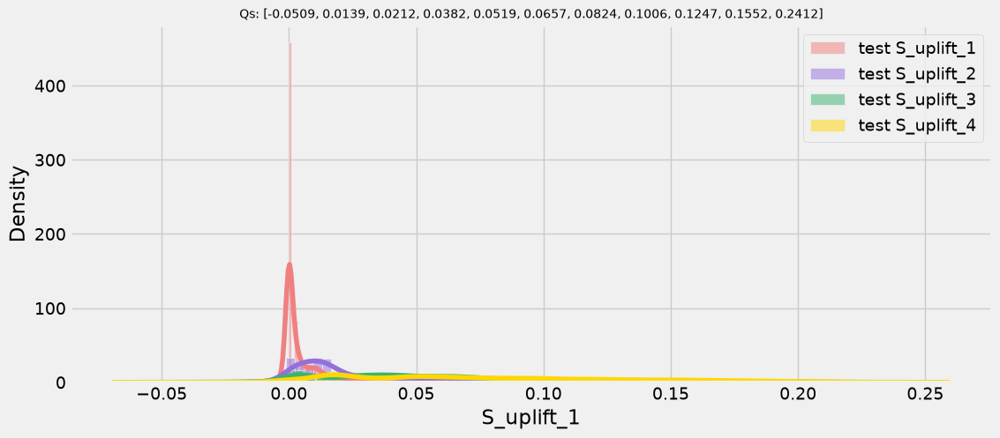

  0%|          | 0/4 [00:00<?, ?it/s]

2026-10-28T22:59:57,870  INFO learners.py - Calculating prediction..
2026-10-28T22:59:57,904  INFO learners.py - Calculating prediction..
2026-10-28T22:59:57,950  INFO learners.py - Calculating prediction..
2026-10-28T22:59:57,962  INFO learners.py - Calculating prediction..


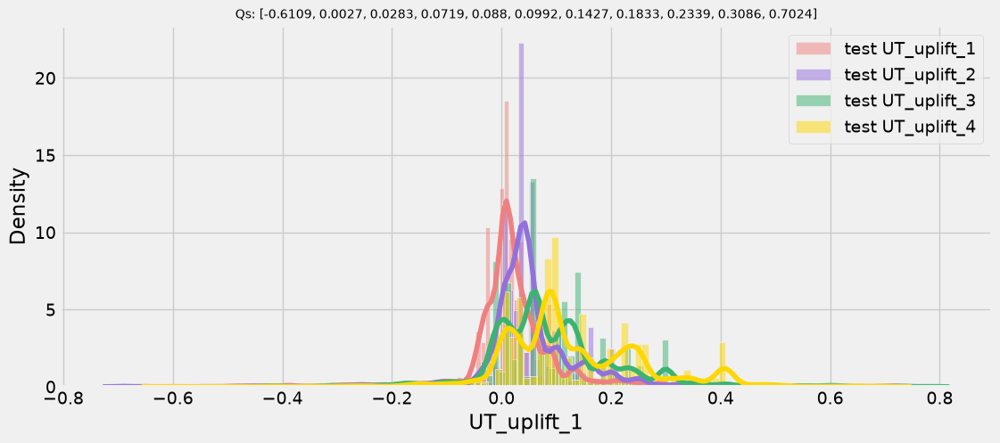

  0%|          | 0/4 [00:00<?, ?it/s]

2026-10-28T22:59:58,365  INFO learners.py - Calculating predictions..
2026-10-28T22:59:58,817  INFO learners.py - Calculating predictions..
2026-10-28T22:59:58,933  INFO learners.py - Calculating predictions..
2026-10-28T22:59:59,083  INFO learners.py - Calculating predictions..


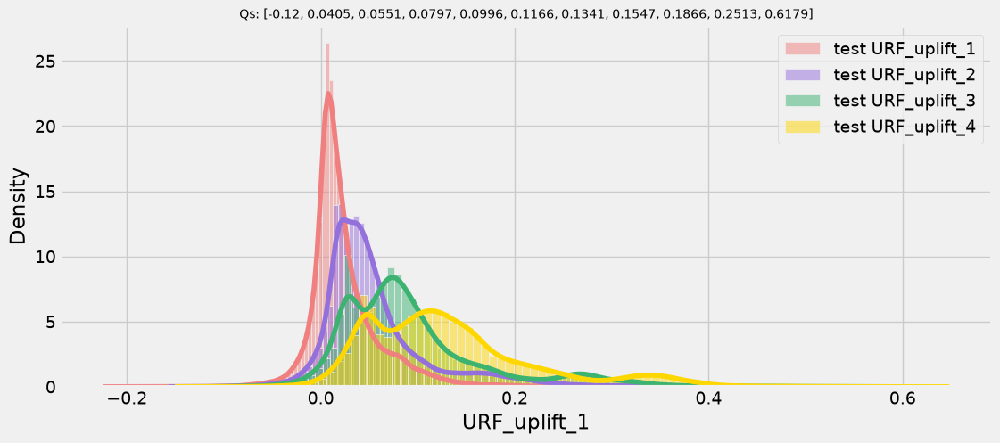

In [52]:
for learner_type in tqdm(fitted_learners):
    for k in tqdm(s_keeper.active):
        learner = fitted_learners[learner_type]
        uplift_predictions, control_prediction = learner.predict(s_keeper.get_X(k), return_baseline = True)
        target_predictions = convert_uplift_to_target_predictions(uplift_predictions = uplift_predictions, control_prediction = control_prediction)
        uplift_predictions.columns = [f"{learner_type}_{c}" for c in uplift_predictions.columns]    
        target_predictions.columns = [f"{learner_type}_{c}" for c in target_predictions.columns]
        s_keeper[k].loc[:, list(target_predictions.columns)] = target_predictions
        s_keeper[k].loc[:, list(uplift_predictions.columns)] = uplift_predictions

    test_sample_key = 'test'
    t = s_keeper.get_T(test_sample_key)
    fig, ax = plt.subplots(1, 1, figsize = (12, 5))
    for color, t_label in zip(VARIANTS_COLORS, sorted(t.unique())):
        if t_label == CONTROL_LABEL:
            continue
        score_col = f'{learner_type}_uplift_{t_label}'
        check_distr(s_keeper.get_S(test_sample_key, score_name=score_col), label=f"{test_sample_key} {score_col}", ax = ax, color = color, verbose=False)
    plt.close()
    display(fig)        

In [53]:
from pulsar.common.constants import TREATMENT_LABEL

verbose = False

evaluation_results = {}

for learner_type in learner_types:

    evaluation_results[learner_type] = {}
    
    for t_label in tqdm(sorted(t.unique())):
        if t_label == CONTROL_LABEL:
            continue
        filter_query = f"{treatment_col} == {t_label} or {treatment_col} == {CONTROL_LABEL}"
        score_col = f'{learner_type}_uplift_{t_label}'
        print('-'*80 + score_col + '-'*80)
        
        ### all these eval functions inside are expecting 0/1 control/treatment data
        ### so we should not only restrict the data to these treatments' subset - SampleKeeper mechanics would capture that natively underneath as long as filter is set correctly
        ### but we also need temporary remap treatment labels into this 0/1 and provide in into SampleKeeper config
        temp_treatment_col = '__temp_treatment'
        for k in s_keeper.active:
            s_keeper[k][temp_treatment_col] = s_keeper[k][treatment_col]
            s_keeper[k].loc[s_keeper[k][treatment_col] == t_label, temp_treatment_col] = TREATMENT_LABEL
        
        s_keeper.add_filter(filter_query)
        s_keeper.set_markup(treatment_name=temp_treatment_col)
        try:
            treatment_evaluation_results = run_uplift_evaluation_tests(
                sample_keeper = s_keeper,
                # sample_keys = [train_sample_key, test_sample_key],
                # sample_keys = [test_sample_key],
                score_name = score_col,
                base_sample_key = train_sample_key,
                k_target_threshold = 20,
                percentile_chart_n_buckets = 10,
                calibration_n_buckets = 10,
                verbose = verbose,
            )
        except Exception as e:
            raise e
        finally:
            for k in s_keeper.active:
                s_keeper[k].drop([temp_treatment_col], axis = 1, inplace = True)
            s_keeper.disable_filter(filter_query)
            s_keeper.set_markup(treatment_name=treatment_col)
    
        evaluation_results[learner_type][t_label] = treatment_evaluation_results

  0%|          | 0/5 [00:00<?, ?it/s]

--------------------------------------------------------------------------------S_uplift_1--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

--------------------------------------------------------------------------------S_uplift_2--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

--------------------------------------------------------------------------------S_uplift_3--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

--------------------------------------------------------------------------------S_uplift_4--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

--------------------------------------------------------------------------------UT_uplift_1--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

--------------------------------------------------------------------------------UT_uplift_2--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

--------------------------------------------------------------------------------UT_uplift_3--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

--------------------------------------------------------------------------------UT_uplift_4--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

--------------------------------------------------------------------------------URF_uplift_1--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

--------------------------------------------------------------------------------URF_uplift_2--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

--------------------------------------------------------------------------------URF_uplift_3--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

--------------------------------------------------------------------------------URF_uplift_4--------------------------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

In [54]:
qini_results = []
for learner_type in learner_types:
    for t_label in treatment_labels:
        if t_label == CONTROL_LABEL:
            continue
        qini_results.append({**{'learner_type': learner_type, treatment_col: t_label}, **evaluation_results[learner_type][t_label]['qini']['values']})
qini_results = pd.DataFrame.from_dict(qini_results)
qini_results_pvt = qini_results.pivot(columns=['learner_type'], index = treatment_col)
display(qini_results_pvt)
qini_macro_results = qini_results_pvt.mean(axis = 0).unstack()
display(qini_macro_results)

train                          test                      \
learner_type         S       URF        UT         S       URF        UT   
voucher_pct                                                                
1             0.042622  0.225054  0.108473  0.024020  0.027509 -0.000541   
2             0.074862  0.207067  0.116602  0.055852  0.065720  0.037013   
3             0.098122  0.191790  0.141046  0.063771  0.067128  0.044107   
4             0.116134  0.194152  0.152237  0.092881  0.104771  0.065385   

                   oot                       holdout                      
learner_type         S       URF        UT         S       URF        UT  
voucher_pct                                                               
1             0.023663  0.009246  0.009329  0.022623  0.024048  0.016496  
2             0.043144  0.041275  0.025961  0.040535  0.054733  0.033046  
3             0.066273  0.069239  0.055724  0.051952  0.060264  0.061869  
4             0.088909  0.096450  0.073844  0.079678  0.107481  0.085091

learner_type,S,URF,UT
train,0.082935,0.204516,0.129589
test,0.059131,0.066282,0.036491
oot,0.055497,0.054052,0.041214
holdout,0.048697,0.061632,0.049126


--------------------------------------------------------------------------------URF--------------------------------------------------------------------------------
--------------------------------------------------------------------------------URF--------------------------------------------------------------------------------
--------------------------------------------------------------------------------1--------------------------------------------------------------------------------


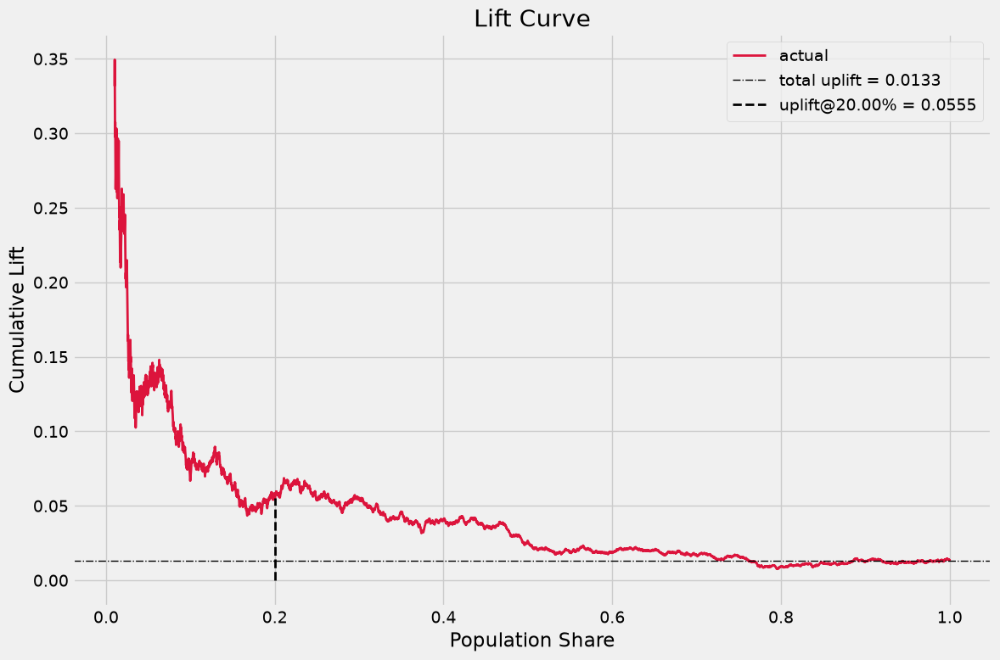

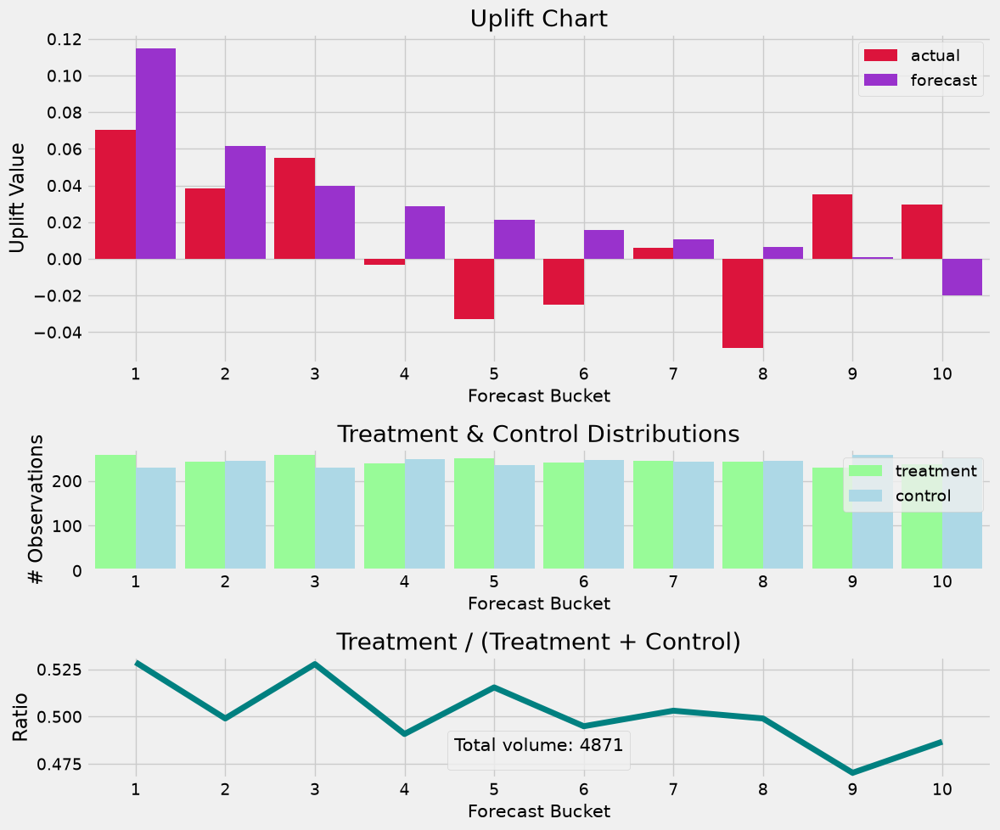

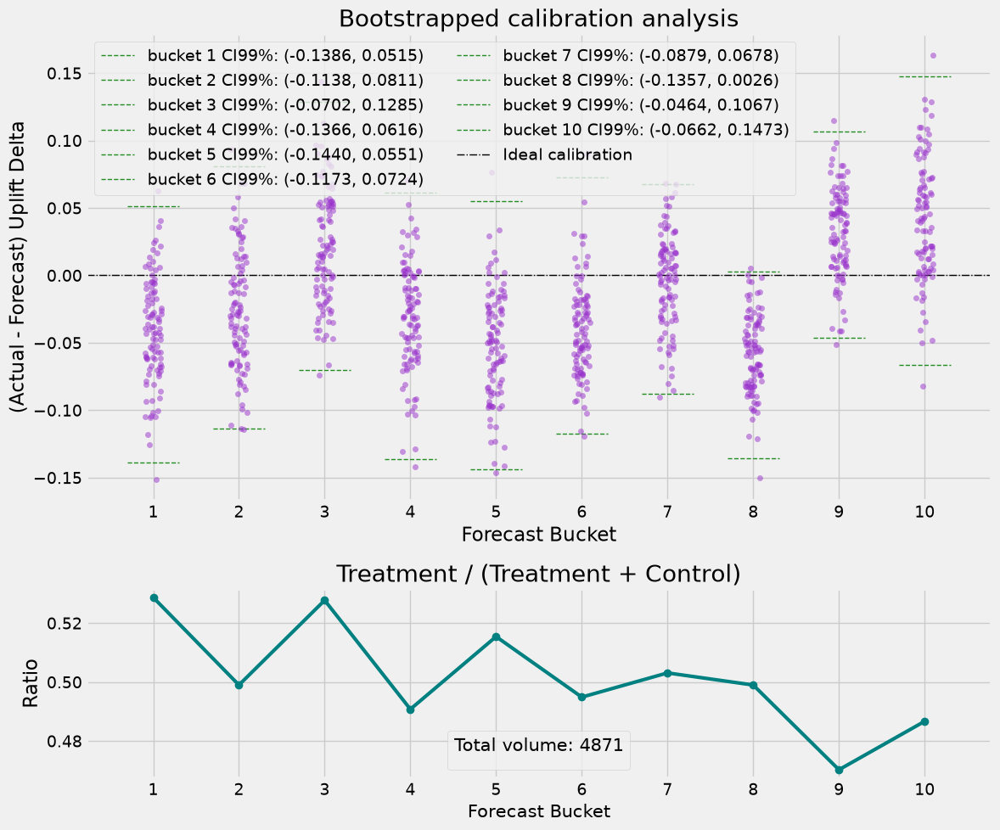

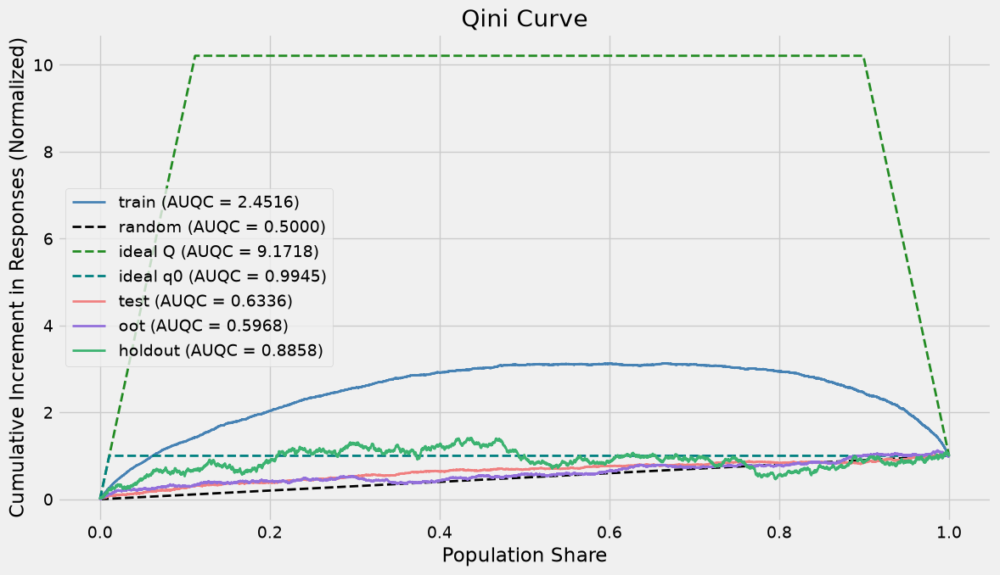

--------------------------------------------------------------------------------1--------------------------------------------------------------------------------
--------------------------------------------------------------------------------2--------------------------------------------------------------------------------


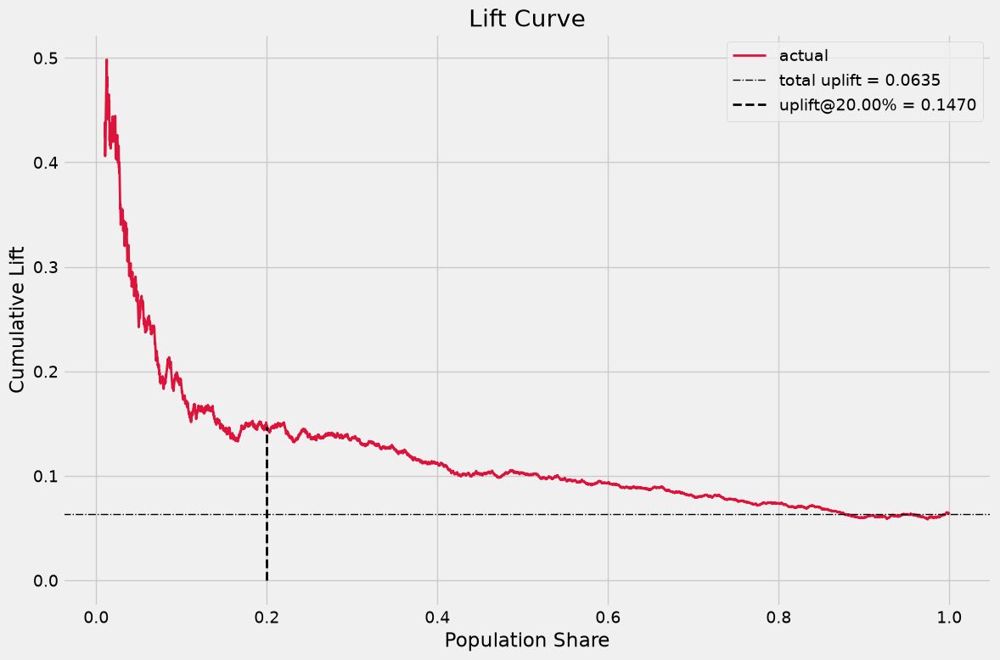

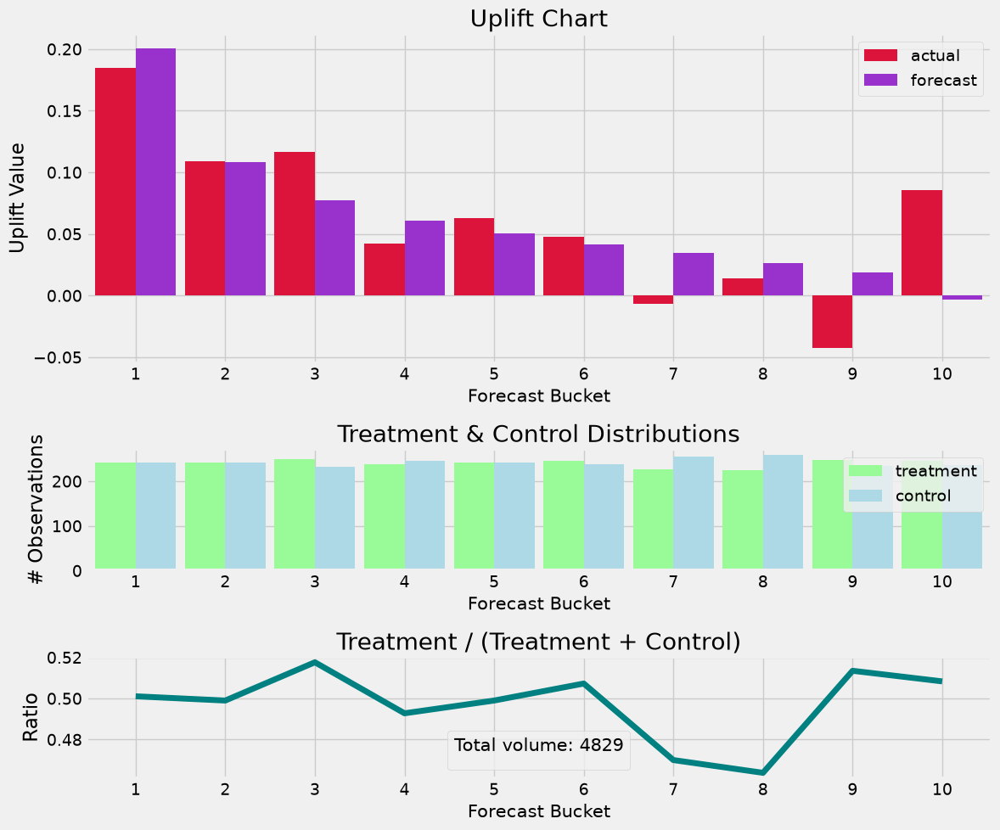

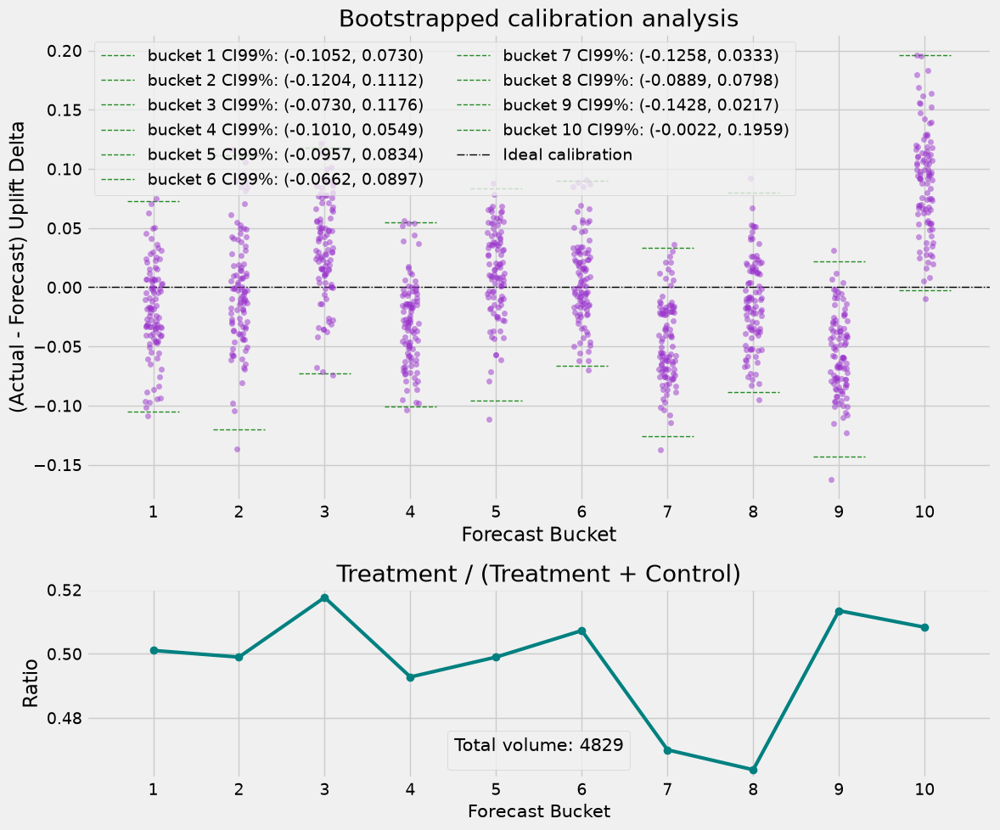

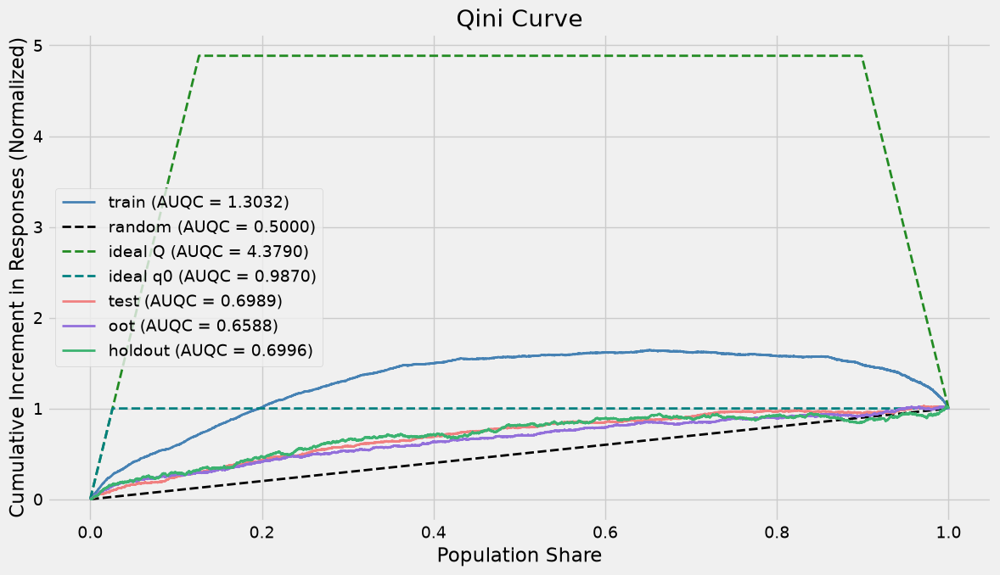

--------------------------------------------------------------------------------2--------------------------------------------------------------------------------
--------------------------------------------------------------------------------3--------------------------------------------------------------------------------


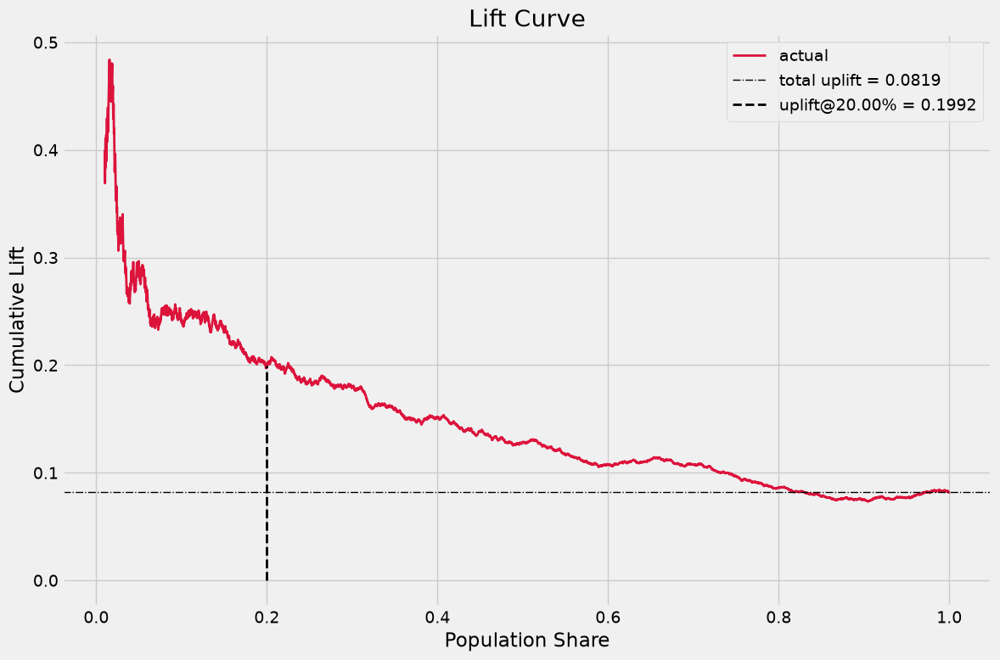

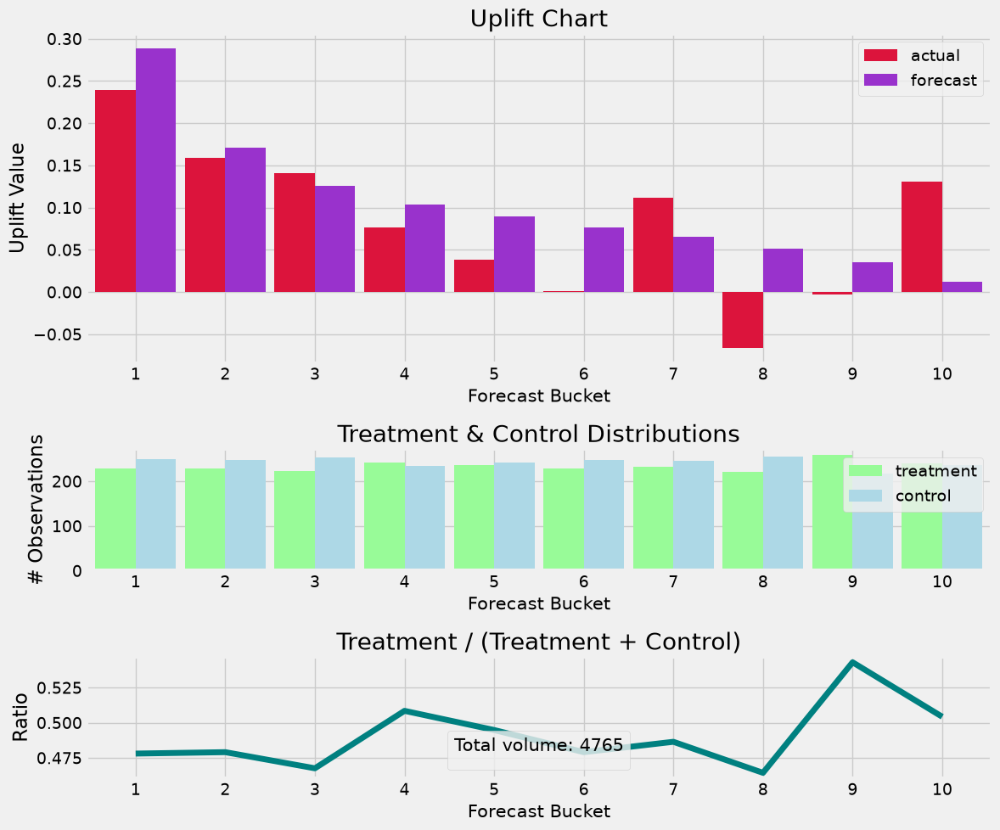

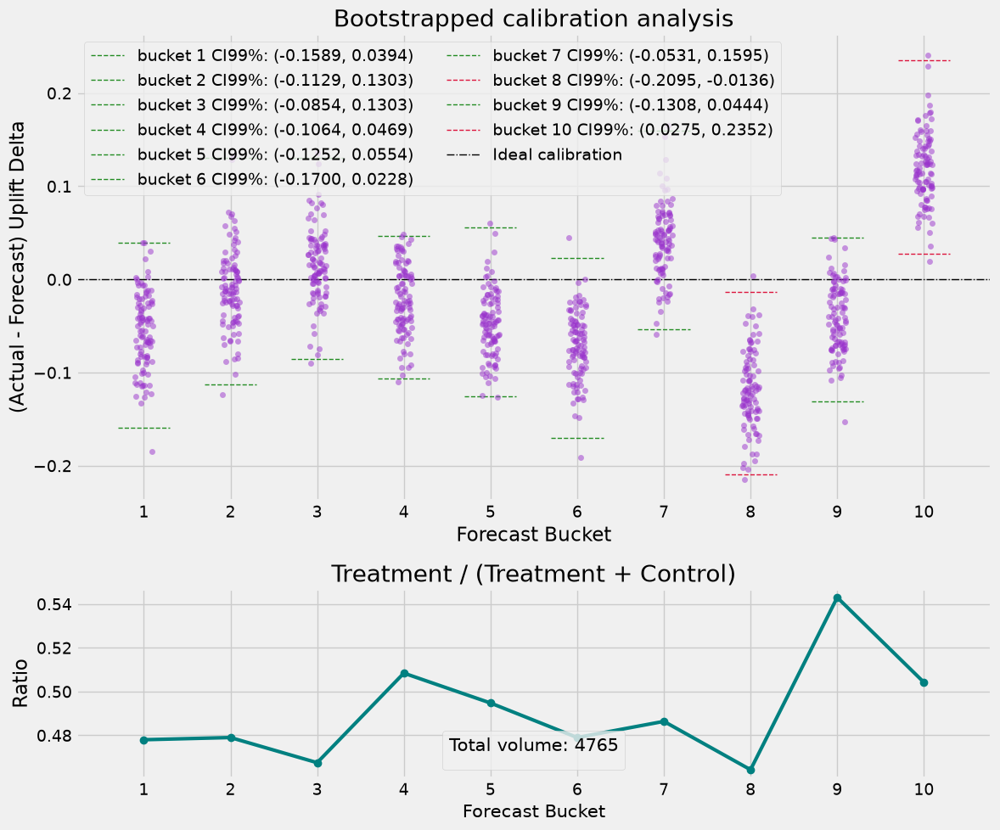

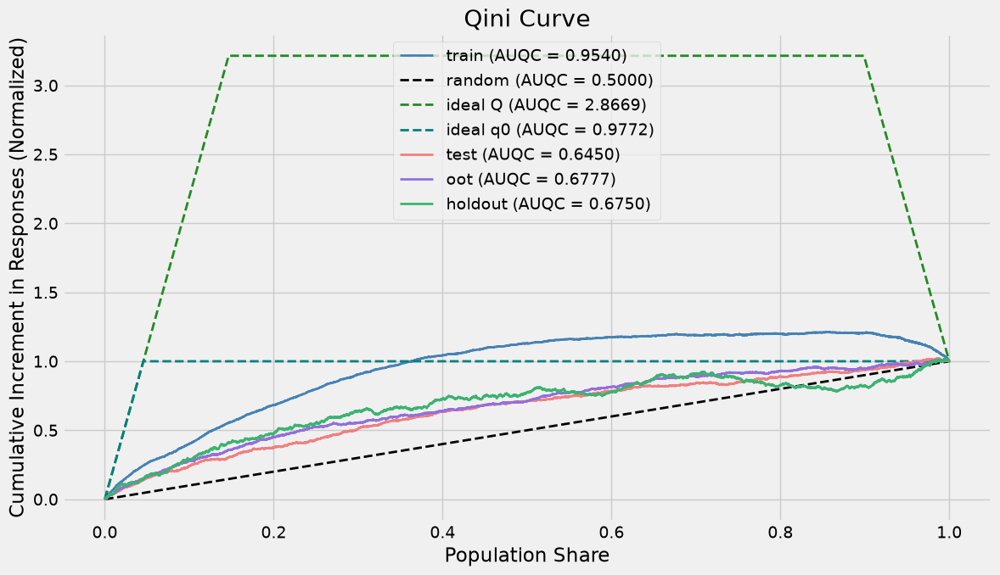

--------------------------------------------------------------------------------3--------------------------------------------------------------------------------
--------------------------------------------------------------------------------4--------------------------------------------------------------------------------


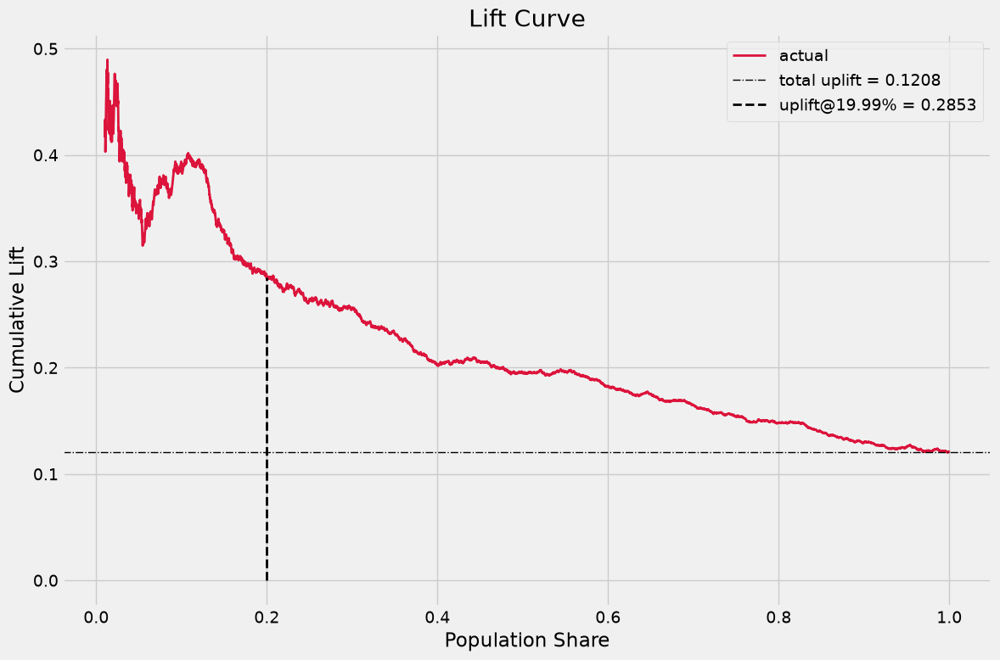

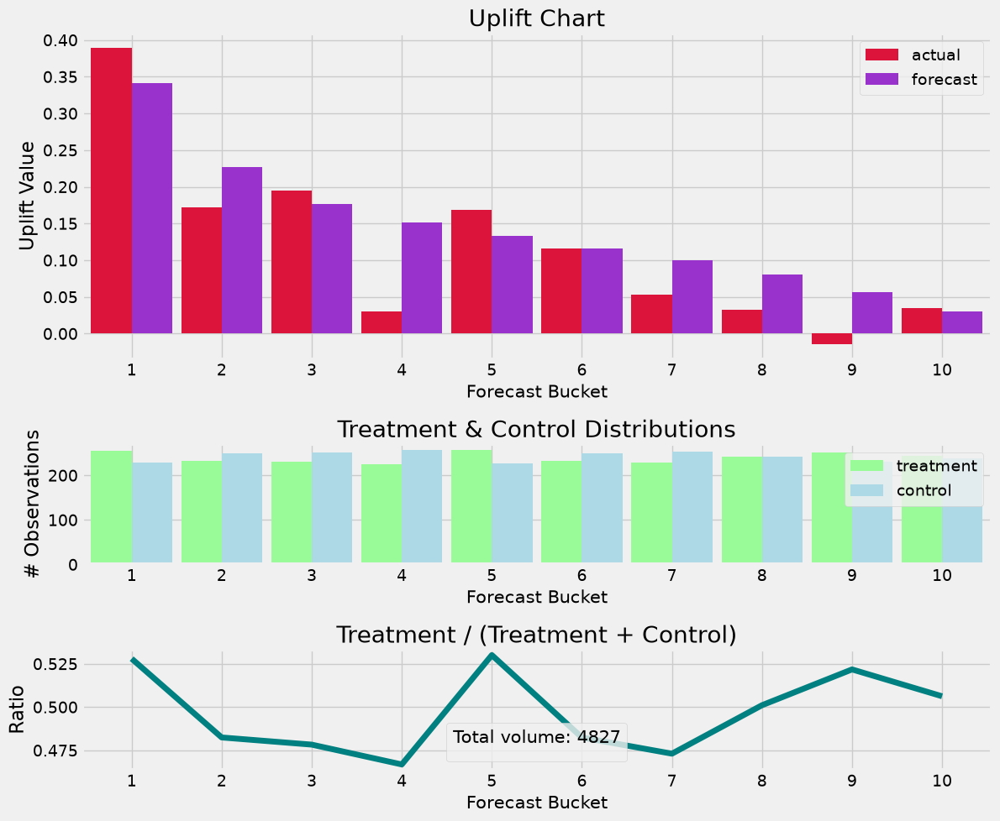

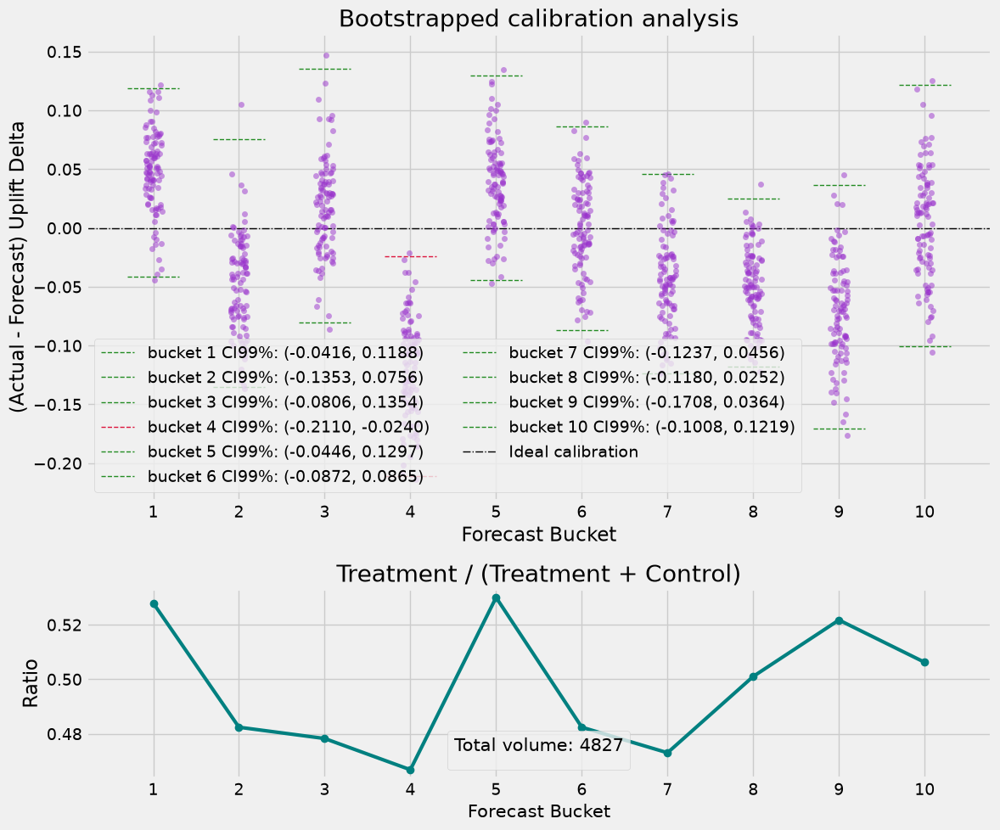

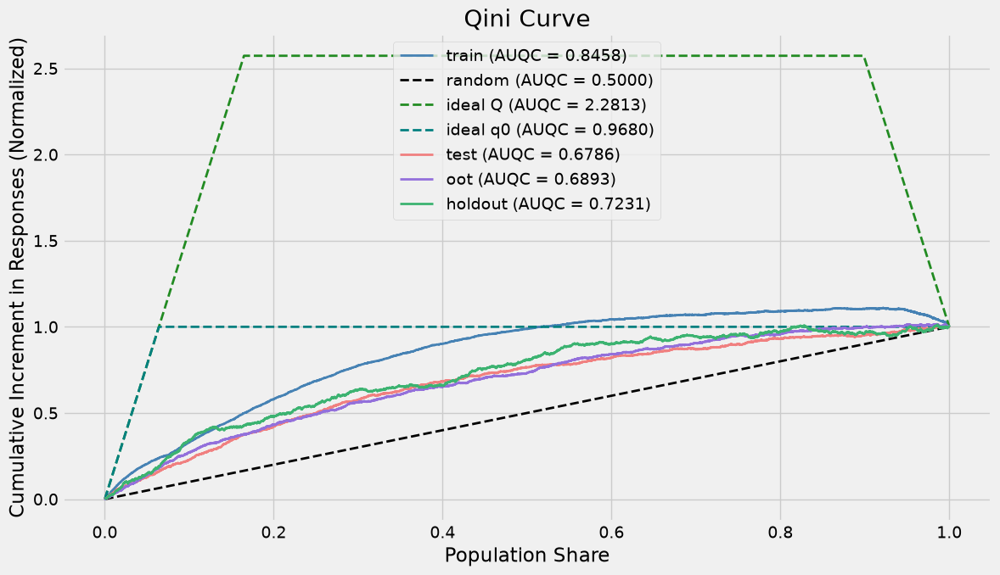

--------------------------------------------------------------------------------4--------------------------------------------------------------------------------
--------------------------------------------------------------------------------URF--------------------------------------------------------------------------------
--------------------------------------------------------------------------------URF--------------------------------------------------------------------------------


In [55]:
learner_type = 'URF'

eval_sample_key = 'holdout'

# for learner_type in learner_types:
print('-' * 80 + learner_type + '-' * 80)
print('-' * 80 + learner_type + '-' * 80)
for t_label in treatment_labels:
    if t_label == CONTROL_LABEL:
        continue
    print('-' * 80 + f"{t_label}" + '-' * 80)
    display(evaluation_results[learner_type][t_label]['lift_chart']["results"][eval_sample_key]['figure'])
    display(evaluation_results[learner_type][t_label]['percentile_uplift_chart']["results"][eval_sample_key]['figure'])
    display(evaluation_results[learner_type][t_label]['calibration']["results"][eval_sample_key]['figure'])
    display(evaluation_results[learner_type][t_label]['qini']['figure'])
    print('-' * 80 + f"{t_label}" + '-' * 80)
print('-' * 80 + learner_type + '-' * 80)
print('-' * 80 + learner_type + '-' * 80)        

We see that URF model is calibrated, and while lift effect and qini curve are noisy for smallest voucher (10%) it's stable across all samples for higher discounts (as measured vs control) - since it's yielding the highest macro qini metric on the holdout and oot datasets we'll proceed with this learner


# Optimization under budget constraints

Inputs we have:

- $P(d) = P(>= 1 \text{ order in the next week} | D = d, FD = fd, X = x), d  \in \{0, 10, 20, 30, 40\}$ - conversion probability given discount level $d$ is offered for a user with features $x$. Or,  alternatively $P(0)$ and a set of uplift values $\{\Delta_{10}, \Delta_{20}, \Delta_{30}, \Delta_{40}\}$
- **AOV_7d** - Average Order Value for 7d - we don't observe it directly, but we could make an assumption and scale it from **aov_90d** which is in the feature set for each user. It has somewhat strong assumption that both D and FD treatment do not modify the AOV, which might not hold in reality, but unfortunately we don't have actual forward-looking post-treatment data at hand.
- $u(d) = P(\text{voucher used} = 1|D = d, FD = d)$ - likelyhood of promo being actually utilized given discount level d was offered - we might try to model it using feature values x for each user or fallback to average values per discount level (or discount level + free delivery level)
- $c(d) = E[\text{voucher cost}|D = d, FD = d, \text{voucher used} = 1]$ - average cost per applied voucher, same as above - could model or fallback to average per discount level (or discount level + free delivery level)
- Orders_30d - Order count for last 30d, again not observed for 7d ahead, we could only say that it's at least 1 order when **ordered == 1**
- **B** - Weekly budget in Currency Units

Let's take a look at our $u(d)$ and $c(d)$ estimates:

In [56]:
# analysis_data = modelling_data
analysis_data = s_keeper['train']

user_id
ordered voucher_used         
0.0     0.0            141504
1.0     0.0             31933
        1.0             17967

voucher_used          
free_delivery            0         1
voucher_pct                         
0                 0.000000  0.000000
1                 0.336018  0.317788
2                 0.395537  0.375701
3                 0.459141  0.450734
4                 0.509003  0.491934

,voucher_pct,free_delivery,voucher_used
0,0,0,0.000000
1,1,0,0.336018
2,2,0,0.395537
3,3,0,0.459141
4,4,0,0.509003
5,0,1,0.000000
6,1,1,0.317788
7,2,1,0.375701
8,3,1,0.450734
9,4,1,0.491934


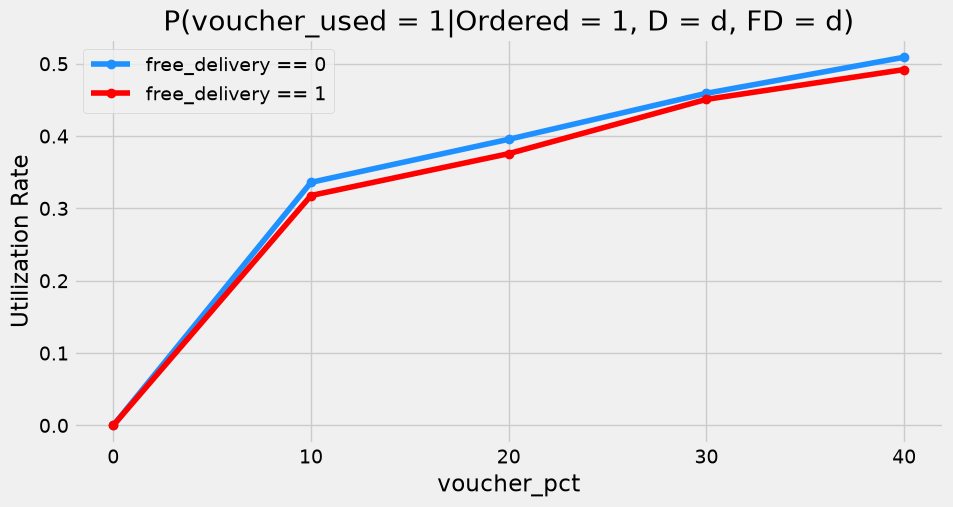

In [57]:
gb = analysis_data.groupby([target_col, utilization_col]).agg({id_col: 'count'})
display(gb)
gb = analysis_data.loc[analysis_data[target_col] == 1, :].groupby([treatment_col, aux_treatment_col]).agg({utilization_col: 'mean'}).unstack(-1)
display(gb)
gb.columns = gb.columns.get_level_values(1)
utilization_rate_mapping = gb.reset_index().melt(id_vars = treatment_col, var_name = aux_treatment_col, value_name = utilization_col)
display(utilization_rate_mapping)

fig, ax = plt.subplots(1,1, figsize = (10, 5))
ax.plot(gb.iloc[:, 0].index.map(labels_mapping), gb.iloc[:, 0], marker = 'o', color = 'dodgerblue', label = f"{aux_treatment_col} == 0")
ax.plot(gb.iloc[:, 1].index.map(labels_mapping), gb.iloc[:, 1], marker = 'o', color = 'red', label = f"{aux_treatment_col} == 1")
ax.set_ylabel("Utilization Rate")
ax.set_xlabel(treatment_col)
ax.set_title("P(voucher_used = 1|Ordered = 1, D = d, FD = d)")
ax.legend()
plt.close()
display(fig)

voucher_cost               
                      min      mean  max
voucher_used                            
0.0                   NaN       NaN  NaN
1.0              1.800418  6.614176  9.0

voucher_cost          
free_delivery            0         1
voucher_pct                         
1                 2.594142  2.653653
2                 5.190729  5.288650
3                 7.386402  7.379801
4                 8.568906  8.594227

,voucher_pct,free_delivery,voucher_cost
0,1,0,2.594142
1,2,0,5.190729
2,3,0,7.386402
3,4,0,8.568906
4,1,1,2.653653
5,2,1,5.288650
6,3,1,7.379801
7,4,1,8.594227


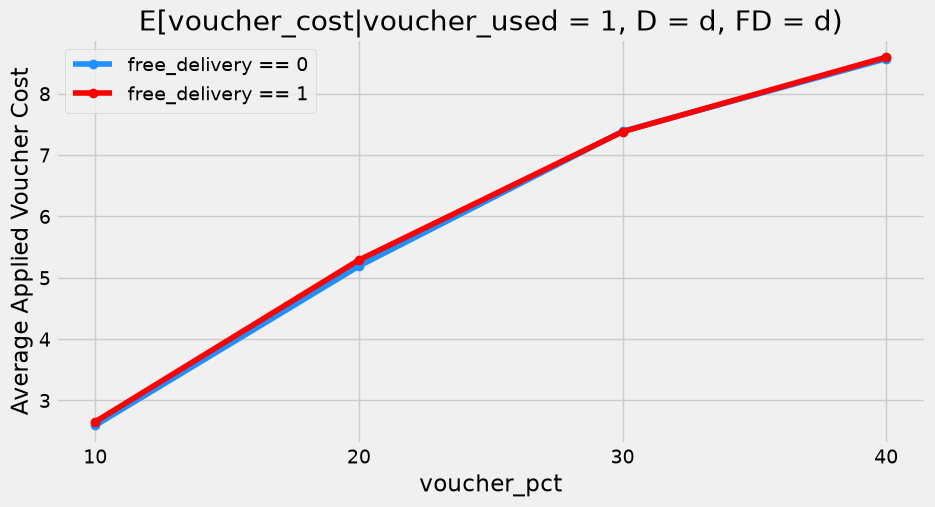

In [58]:
gb = analysis_data.groupby([utilization_col]).agg({cost_col: ['min', 'mean', 'max']})
display(gb)
gb = analysis_data.loc[analysis_data[utilization_col] == 1, :].groupby([treatment_col, aux_treatment_col]).agg({cost_col: 'mean'}).unstack(-1)
display(gb)
gb.columns = gb.columns.get_level_values(1)
avg_cost_mapping = gb.reset_index().melt(id_vars = treatment_col, var_name = aux_treatment_col, value_name = cost_col)
display(avg_cost_mapping)

fig, ax = plt.subplots(1,1, figsize = (10, 5))
ax.plot(gb.iloc[:, 0].index.map(labels_mapping), gb.iloc[:, 0], marker = 'o', color = 'dodgerblue', label = f"{aux_treatment_col} == 0")
ax.plot(gb.iloc[:, 1].index.map(labels_mapping), gb.iloc[:, 1], marker = 'o', color = 'red', label = f"{aux_treatment_col} == 1")
ax.set_ylabel("Average Applied Voucher Cost")
ax.set_xlabel(treatment_col)
ax.set_title("E[voucher_cost|voucher_used = 1, D = d, FD = d)")
ax.legend()
plt.close()
display(fig)

One way to formulate the optimization problem is the following:

Objective: $\sum_i E[N_{\text{orders next week}}|N_{\text{orders next week}} \geq 1]_i * AOV_i * [P(N_{\text{orders next week}} \geq 1 | D = d_i, FD = fd_i, X = x_i) - P(N_{\text{orders next week}} \geq 1 | D = 0, FD = fd_i, X = x_i)] \xrightarrow{d_i} max$

Cost constraints: $\sum_i P(N_{\text{orders next week}} \geq 1 | D = d_i, FD = fd_i, X = x_i) * u(d_i) * c(d_i) \leq B $

There are no big problems with the cost components, we already got some estimates above and we know the budget limits. We also postulate that promo applies to at most one order per week.

However the objective part is trickier as we have many more degrees of freedom here.
 
Such objective formulation assumes that incremental gain in CU from discount d on a user is $\Delta P * E[(\text{N orders per converter})] * AOV$

Using E[N | N ≥ 1] for user orders per converting user assumes that the extra converters induced by the discount order at the same rate as a typical converting week for that user, as predicted from **orders_30d**. This ignores the fact that discount may also make already-converting users order more than once. The binary weekly flag we have can’t show this, so it is excluded from $\Delta P$ component, and the formula doesn’t really capture it. It also ignores selection: induced converters are users who would not have ordered otherwise, so they may order less than the historical value for 30d-orders implies. This might overstate the benefit for heavy users.

Orders x AOV component multiplies all user’s $\Delta P$ values by the same constant for a particular user.

Without a budget and with a margin in the objective, a user’s argmax over discounts is unchanged by the multiplier. Total cost is also unchanged because the promo applies to one order per week.

But these multipliers might change the way vouchers are distributed under budget constraints.
With the currency budget limits imposed though it matters across users: heavy ordering users get a higher incremental value per currency unit, so they move up the ranking and receive discounts first.

For AOV there's an additional catch that non-ordering users don't have a historical positive AOV value and that would nullify the whole objective component for them if we use it as is.

Again, in absense of forward-looking AOV tracked during the experiment, we would need to make some assumption and project the value from ordering users.

We might do some kind of matching, or rather try to predict the AOV for those using the rest of the features while training the model on ordering users

Alternatively, we could extract a certain quantile/another statistic from ordering users and map this value for all non-ordering users

And technically, treatment intervention might be modifying AOV, as in $E[AOV|D = d] \neq E[AOV|D = 0]$

Same goes for post-intervention order count $E[N|N\geq1, D = d] \neq [N|N\geq1, D = 0]$

Ideally user level incremental value from the treatment $d$ and overall Objective would look something like this:

$$\sum_i AOV(d_i, fd_i, x_i) * E[N|N \geq 1, D = d_i, FD = fd_i, X = x_i]_i * P(N \geq 1 | D = d_i, FD = fd_i, X = x_i) - AOV(0, fd_i, x_i) *  E[N|N \geq 1, D = 0, FD = fd_i, X = x_i]_i * P(N \geq 1 | D = 0, FD = fd_i, X = x_i) \xrightarrow{d_i} max$$

## Order count research

Let's try exploring a bit data on order counts

**orders_30d** distribution looks like this:

size: 191404
min: 0, max: 4, mean: 1.0169954650895487, std: 1.160080701058988
# missings: 0, # unique: 5


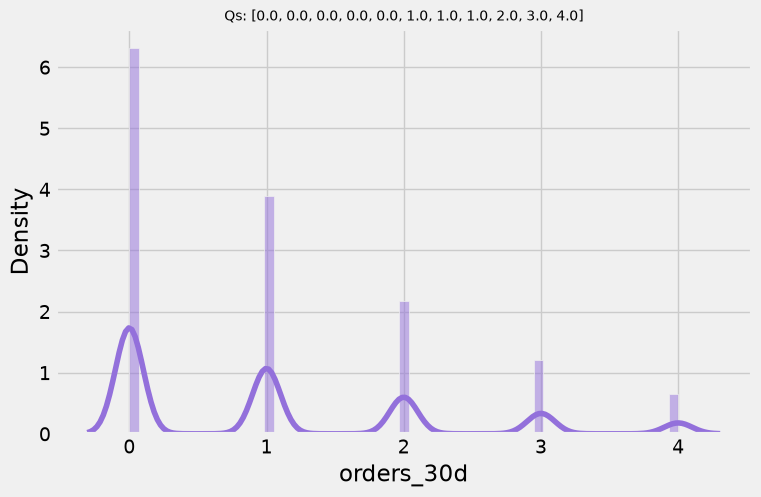

In [59]:
display(check_distr(analysis_data['orders_30d'])['figure'])

Interestingly, it doesn't have a long tail at all - basically average amount of orders per user per 30 days! in the population is less than 1, which is a bit (or more than a bit) sad

If we try to simulate a poisson distribution with empirical mean as $\lambda$ parameter we could see that it's not so much 0-inflated as our empirical distribution is

size: 10000
min: 0, max: 7, mean: 0.9985, std: 0.9985977517233727
# missings: 0, # unique: 8


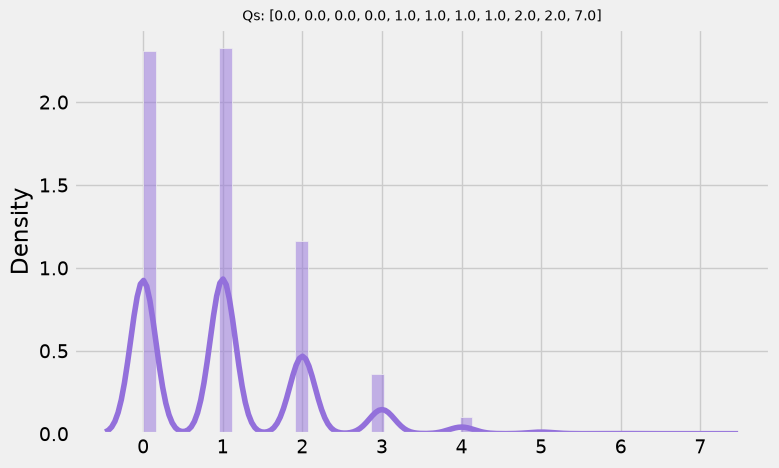

In [60]:
from scipy.stats.distributions import poisson

lmbda = analysis_data['orders_30d'].mean()
check_distr(poisson.rvs(mu = lmbda, size = 10000))['figure']

If we still assume Poisson distribution for order counts (N) for each user, then

$$P(N >= 1) = 1 - e^{-\lambda}$$
$$E[N|N >= 1] = {\lambda} / (1 - e^{-\lambda})$$

0.23729894185422803 0.23729894185422806
size: 191404
min: 1.0, max: 1.5382267159876555, mean: 1.1293617104057703, std: 0.15206087198984103
# missings: 0, # unique: 5


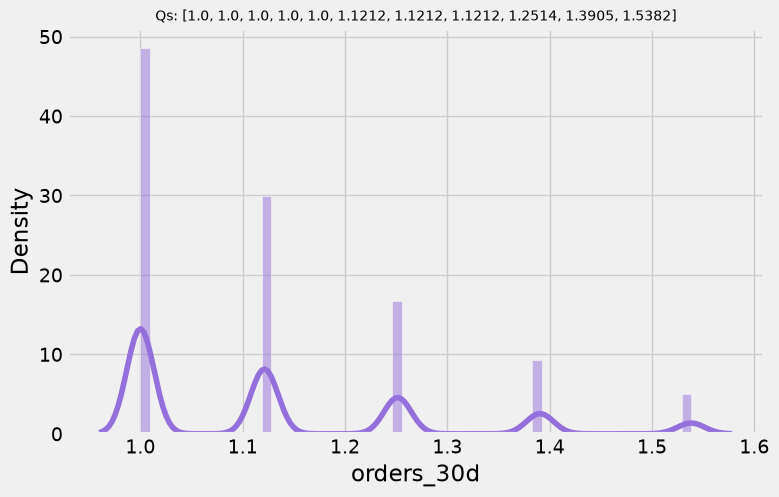

In [61]:
weekly_order_rate = analysis_data['orders_30d'] / (30 / 7)
print(analysis_data['orders_30d'].mean()/(30/7), weekly_order_rate.mean())
prob_n1_plus = 1 - np.exp(-weekly_order_rate)
exp_n_n1_plus = weekly_order_rate / prob_n1_plus
exp_n_n1_plus = exp_n_n1_plus.fillna(1) ### for users with 0 orders in 30d lambda is also 0, and so is the expected value of orders above 1, so we correct it and set the multiplier to 1
display(check_distr(exp_n_n1_plus)['figure'])

In [62]:
d = pd.DataFrame({
    treatment_col: analysis_data[treatment_col],
    'orders_30d': analysis_data['orders_30d'],
    'p>=1': prob_n1_plus,
    target_col: analysis_data[target_col],
})
display(d.groupby([treatment_col, 'orders_30d']).agg('mean').T)

voucher_pct         0                                                 1  \
orders_30d          0         1         2         3         4         0   
p>=1         0.000000  0.208110  0.372911  0.503415  0.606759  0.000000   
ordered      0.078241  0.166985  0.295911  0.506002  0.726394  0.089268   

voucher_pct                                          ...         3            \
orders_30d          1         2         3         4  ...         0         1   
p>=1         0.208110  0.372911  0.503415  0.606759  ...  0.000000  0.208110   
ordered      0.196975  0.334953  0.542362  0.729384  ...  0.142731  0.277187   

voucher_pct                                       4                      \
orders_30d          2         3         4         0         1         2   
p>=1         0.372911  0.503415  0.606759  0.000000  0.208110  0.372911   
ordered      0.437917  0.599879  0.775533  0.175009  0.329454  0.472814   

voucher_pct                      
orders_30d          3         4  
p>=1         0.503415  0.606759  
ordered      0.630003  0.786959  

[2 rows x 25 columns]

We see that such projection for P(N>=1) understimates even the binary flag averages for users with higher 30d order counts

So we could also try out negative binomial distribution for this, but with average number of orders per week per user being around 4 times less than 1 it just doesn't make sense to include such order count based multiplier in the objective

## AOV research

The idea on why we might need AOV is illustrated below

,user_id,ordered,voucher_cost,aov_90d,avg_cost_per_user,ATE,efficiency
voucher_pct,,,,,,,
0,38355,0.202060,0.000000,17.531473,0.000000,0.000000,NaN
1,38397,0.224002,7369.510221,17.576361,0.191929,0.021942,0.114324
2,38183,0.254066,19586.744352,17.559897,0.512970,0.052006,0.101383
3,38332,0.293306,37757.028649,17.579947,0.985000,0.091246,0.092636
4,38137,0.330519,54123.620838,17.542558,1.419189,0.128459,0.090516


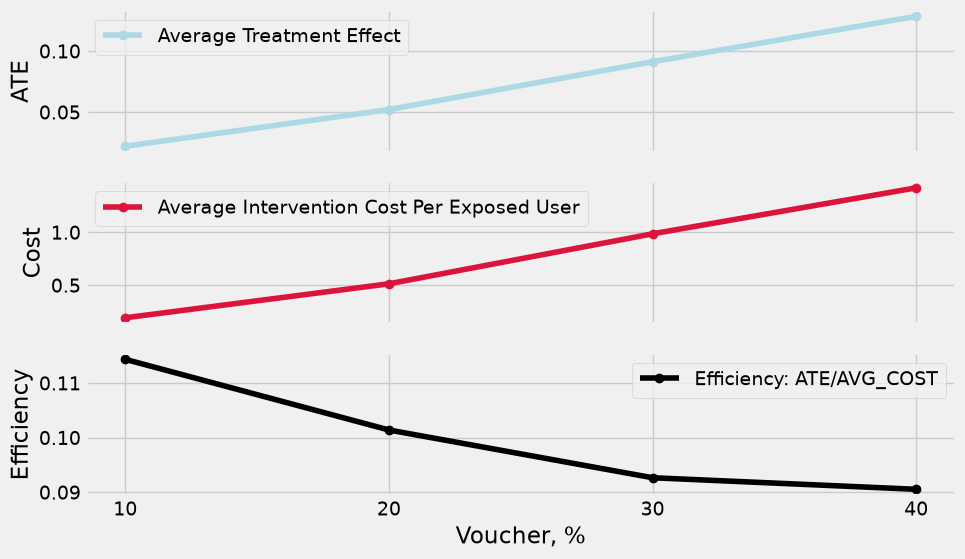

In [63]:
gb = (
    analysis_data
    .groupby(treatment_col)
    .agg({
        id_col: 'count',
        target_col: 'mean',
        cost_col: 'sum',
        'aov_90d': 'sum',
    })
)
gb['aov_90d'] = gb['aov_90d'] / gb[id_col]
gb['avg_cost_per_user'] = gb[cost_col] / gb[id_col]
gb['ATE'] = 0.0
gb.loc[1:, 'ATE'] = gb.loc[1:, target_col] - gb.loc[0, target_col]
gb['efficiency'] = gb['ATE'] / gb['avg_cost_per_user']
display(gb)
gb = gb.iloc[1:, :]


fig, ax = plt.subplots(3, 1, figsize = (10, 6), sharex = True)

ax[0].plot(gb.index, gb['ATE'], label = 'Average Treatment Effect', color = 'lightblue', marker = 'o')
ax[1].plot(gb.index, gb['avg_cost_per_user'], label = 'Average Intervention Cost Per Exposed User', color = 'crimson', marker = 'o')
ax[2].plot(gb.index, gb['efficiency'], label = 'Efficiency: ATE/AVG_COST', color = 'black', marker = 'o')
ax[0].set_ylabel('ATE')
ax[1].set_ylabel('Cost')
ax[2].set_ylabel('Efficiency')
ax[2].set_xticks(gb.index)
ax[2].set_xticklabels(gb.index.map(labels_mapping))
ax[2].set_xlabel('Voucher, %')
for a in ax:
    a.legend()

plt.close()
display(fig)

So it's true that ATE is growing with voucher value, but efficiency (ATE per promo cost) actually drops and it also could turn out that we're retaining / acquiring users with lower AOV

It's better to try incorporating it into the problem formulation directly if we're able to do so and try to focus on incrementality in terms of not just orders, but user value

Let's take a look at AOV data

size: 191404
min: 0.0, max: 102.29133605957031, mean: 17.558064674378212, std: 11.480980330362888
# missings: 0, # unique: 95339


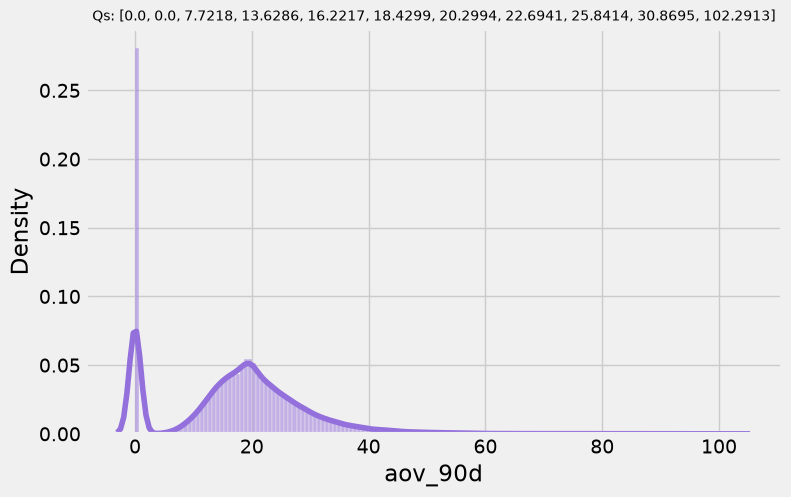

20.23975880940755

In [64]:
display(check_distr(analysis_data['aov_90d'])['figure'])
analysis_data['aov_90d'].loc[analysis_data['aov_90d'] > 0].median()

In [65]:
from lightgbm import LGBMRegressor

analysis_data['no_aov'] = (analysis_data['aov_90d'] == 0).astype(int)
mask = (analysis_data['aov_90d'] > 0) ### we earlier filled nans with 0s
ordering_users = analysis_data.loc[mask, :]
non_ordering_users = analysis_data.loc[~mask, :]

aov_predictive_features = [
    f for f in num_feature_cols if f not in [
        'aov_90d',
        # 'orders_90d', 'orders_30d',
    ]
]
print(aov_predictive_features)
    
display(analysis_data.groupby('no_aov').agg({**{f: 'mean' for f in aov_predictive_features}, **{id_col: 'count'}}))

aov_model = LGBMRegressor()
aov_model.fit(ordering_users[aov_predictive_features], ordering_users['aov_90d'])
ordering_users['aov_90d_forecast'] = aov_model.predict(ordering_users[aov_predictive_features])

['orders_90d', 'orders_30d', 'days_since_last_order', 'pct_orders_with_promo_90d', 'avg_voucher_pct_received_90d', 'voucher_redemption_rate_90d', 'manual_voucher_entry_rate_90d', 'sessions_30d', 'days_since_last_session', 'push_opt_in', 'offers_tab_share_of_sessions_30d']


,orders_90d,orders_30d,days_since_last_order,pct_orders_with_promo_90d,avg_voucher_pct_received_90d,voucher_redemption_rate_90d,manual_voucher_entry_rate_90d,sessions_30d,days_since_last_session,push_opt_in,offers_tab_share_of_sessions_30d,user_id
no_aov,,,,,,,,,,,,
0,3.914949,1.261876,23.490717,0.452909,17.766351,0.128927,0.218449,12.414923,5.226282,0.755685,0.265196,154260
1,0.000000,0.000000,121.358851,NaN,30.040784,0.000000,NaN,6.345009,9.046717,0.571802,0.184195,37144


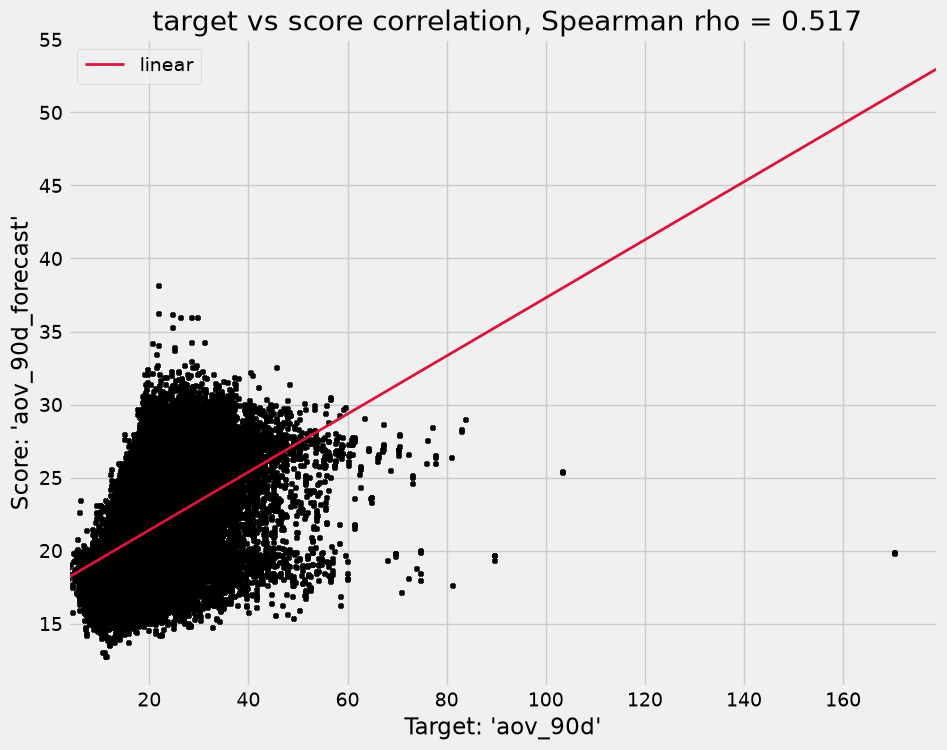

0.2710222547025497


In [66]:
from sklearn.metrics import mean_absolute_percentage_error
from atlas.evaluation import calc_spearman

test_ordering_users = s_keeper['test'].loc[s_keeper['test']['aov_90d'] > 0, :].copy()
test_ordering_users['aov_90d_forecast'] = aov_model.predict(test_ordering_users[aov_predictive_features])
display(calc_spearman(plot_ideal='linear', data=test_ordering_users, target_name = 'aov_90d', score_name='aov_90d_forecast')['figure'])
print(mean_absolute_percentage_error(y_true=test_ordering_users['aov_90d'], y_pred=test_ordering_users['aov_90d_forecast'],))

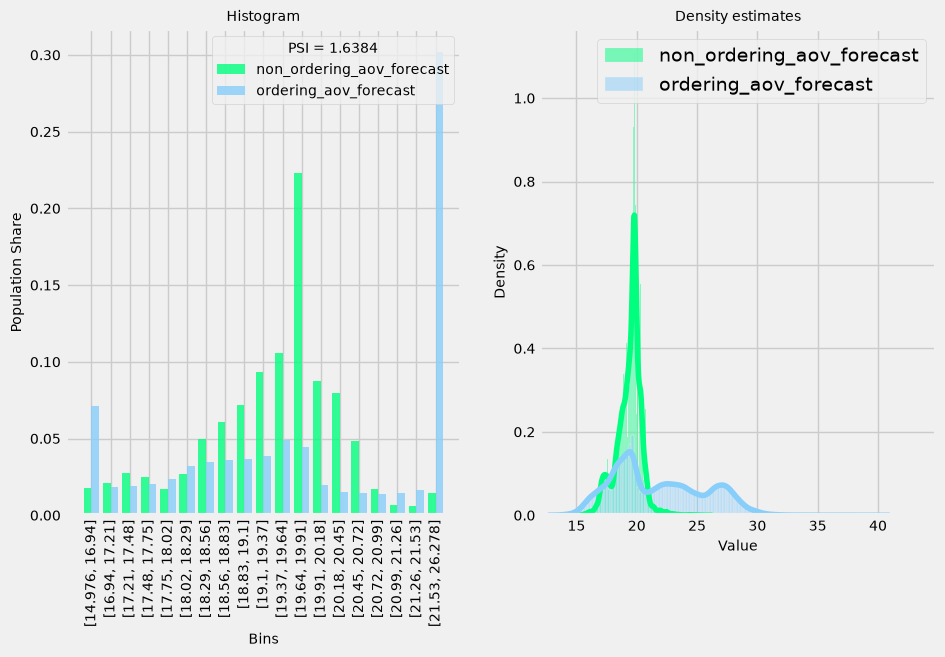

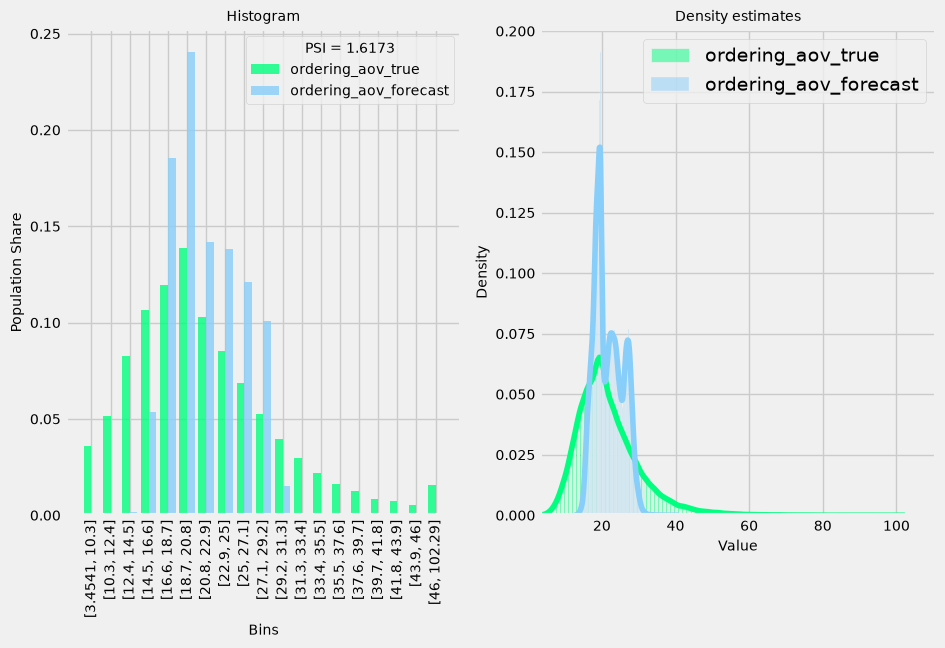

In [67]:
from atlas.evaluation import PSI

non_ordering_users['aov_90d_forecast'] = aov_model.predict(non_ordering_users[aov_predictive_features])
psi = PSI()
display(psi.calc_psi(
    expected=non_ordering_users['aov_90d_forecast'], 
    actual = ordering_users['aov_90d_forecast'],
    labels=['non_ordering_aov_forecast', 'ordering_aov_forecast'],
)['figure'])

display(psi.calc_psi(
    expected = ordering_users['aov_90d'], 
    actual = ordering_users['aov_90d_forecast'],
    labels=['ordering_aov_true', 'ordering_aov_forecast'],
)['figure'])

So, we could somewhat "predict" AOV using other features, metrics are not very good but somewhat decent 

Then we see that predictive distribution on non-actually ordering customers is really different - meaning there's indeed some confounding relation between the features and the fact that customers are not placing orders (e.g. orders_30d and orders_90d probably being empty, ha-ha)

But now let's remove all the features that very obviously would be completely out-of-distribution for non-ordering population, but could explain AOV on the observed part of the data

,orders_90d,orders_30d,days_since_last_order,pct_orders_with_promo_90d,avg_voucher_pct_received_90d,voucher_redemption_rate_90d,manual_voucher_entry_rate_90d,sessions_30d,days_since_last_session,push_opt_in,offers_tab_share_of_sessions_30d,user_id
no_aov,,,,,,,,,,,,
0,3.914949,1.261876,23.490717,0.452909,17.766351,0.128927,0.218449,12.414923,5.226282,0.755685,0.265196,154260
1,0.000000,0.000000,121.358851,NaN,30.040784,0.000000,NaN,6.345009,9.046717,0.571802,0.184195,37144


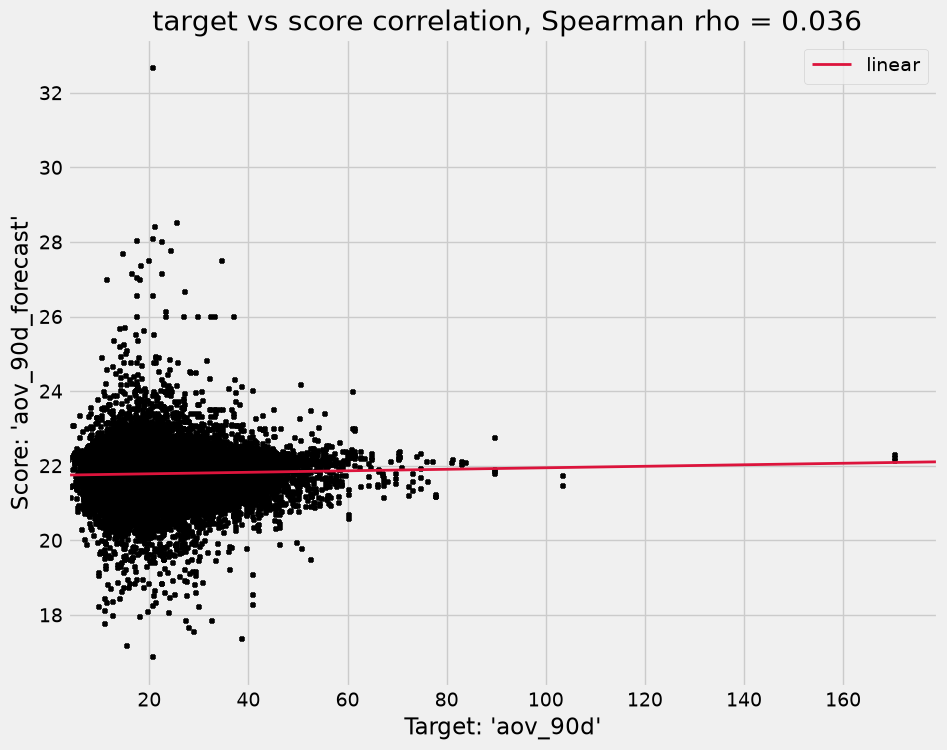

0.32798593869307463


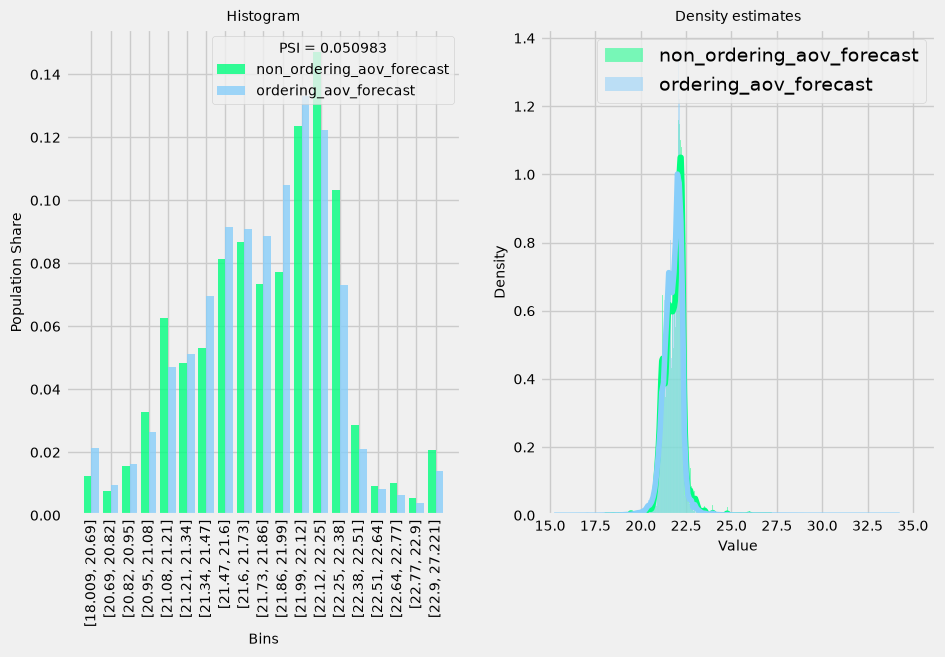

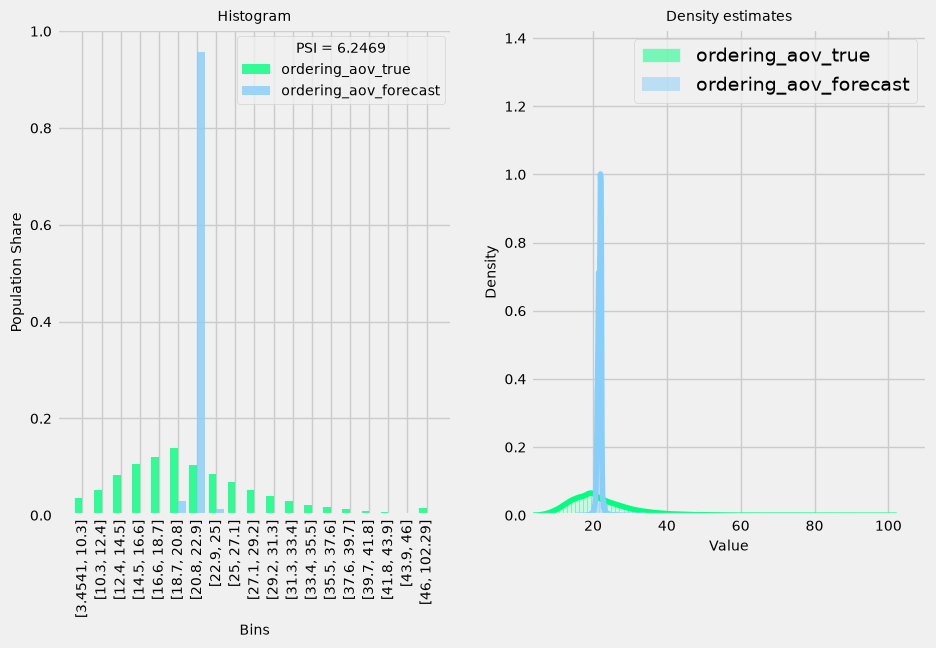

In [68]:
display(analysis_data.groupby('no_aov').agg({**{f: 'mean' for f in aov_predictive_features}, **{id_col: 'count'}}))

aov_predictive_features = [
    # 'days_since_last_order',
    'sessions_30d', 'days_since_last_session', 'push_opt_in', 'offers_tab_share_of_sessions_30d',
]

aov_model = LGBMRegressor()
aov_model.fit(ordering_users[aov_predictive_features], ordering_users['aov_90d'])
ordering_users['aov_90d_forecast'] = aov_model.predict(ordering_users[aov_predictive_features])

test_ordering_users = s_keeper['test'].loc[s_keeper['test']['aov_90d'] > 0, :].copy()
test_ordering_users['aov_90d_forecast'] = aov_model.predict(test_ordering_users[aov_predictive_features])
display(calc_spearman(plot_ideal='linear', data=test_ordering_users, target_name = 'aov_90d', score_name='aov_90d_forecast')['figure'])
print(mean_absolute_percentage_error(y_true=test_ordering_users['aov_90d'], y_pred=test_ordering_users['aov_90d_forecast'],))

non_ordering_users['aov_90d_forecast'] = aov_model.predict(non_ordering_users[aov_predictive_features])
psi = PSI()
display(psi.calc_psi(
    expected=non_ordering_users['aov_90d_forecast'], 
    actual = ordering_users['aov_90d_forecast'],
    labels=['non_ordering_aov_forecast', 'ordering_aov_forecast'],
)['figure'])

display(psi.calc_psi(
    expected = ordering_users['aov_90d'], 
    actual = ordering_users['aov_90d_forecast'],
    labels=['ordering_aov_true', 'ordering_aov_forecast'],
)['figure'])

We could clearly see that on the AOV-observed part we're not explaining much compared to true AOV anymore, but then on AOV-non-observed part distribution is much more similar to the observed and also not spreading far away from the median

We'd use this and actual AOV values for known cases

Let's first test how optimizer would work on out-of-time data (week 14)

## We obtain AOV imputation forecast and blend it with available AOV estimate

size: 60093
min: 3.454063892364502, max: 94.90827178955078, mean: 21.807699400473027, std: 7.481287042764714
# missings: 0, # unique: 50231


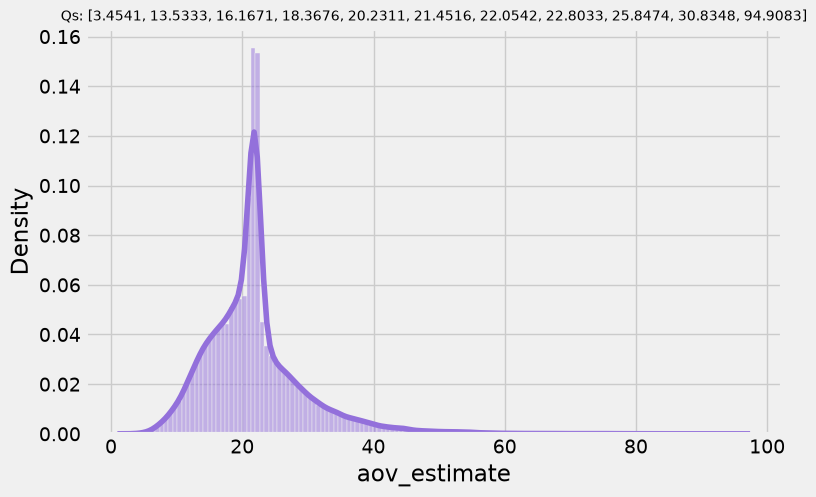

In [69]:
oot_data = s_keeper['oot'].copy()

oot_data['aov_90d_forecast'] = aov_model.predict(oot_data[aov_predictive_features])
oot_data['aov_estimate'] = oot_data['aov_90d']
oot_data.loc[oot_data['aov_estimate'] == 0, 'aov_estimate'] = oot_data.loc[oot_data['aov_estimate'] == 0, 'aov_90d_forecast']

display(check_distr(oot_data['aov_estimate'])['figure'])

If we take a look at our projections for average applied voucher values, the highest CU discount falls just around the 40% of the median for this AOV distribution which kind of makes sense

,voucher_pct,free_delivery,voucher_cost
0,1,0,2.594142
1,2,0,5.190729
2,3,0,7.386402
3,4,0,8.568906
4,1,1,2.653653
5,2,1,5.288650
6,3,1,7.379801
7,4,1,8.594227


size: 8
min: 21.42226419476862, max: 26.536527935550104, mean: 24.62541878860002, std: 2.0898553540547695
# missings: 0, # unique: 8


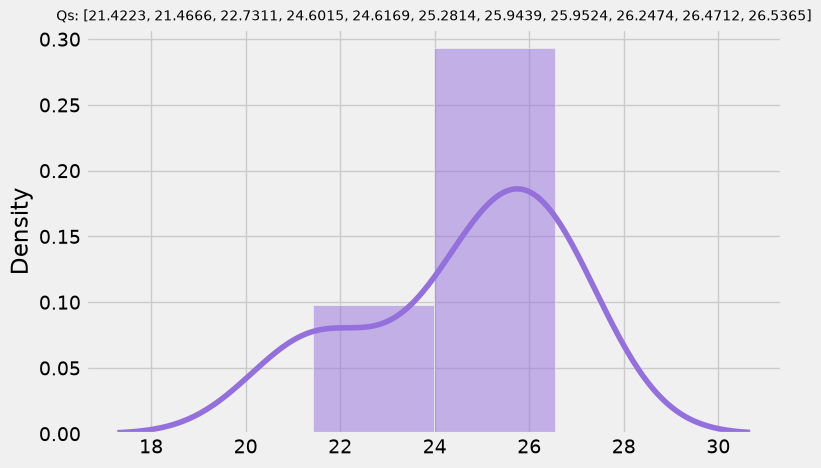

In [70]:
display(avg_cost_mapping)
display(check_distr(avg_cost_mapping[cost_col] / (avg_cost_mapping[treatment_col].map(labels_mapping).astype(int) / 100))['figure'])

## Let's obtain uplift values and make some sanity checks on its distributions

2026-10-28T23:01:26,402  INFO learners.py - Calculating predictions..


,uplift_1,uplift_2,uplift_3,uplift_4
299389,-0.004386,0.016273,0.016255,0.019136
299394,0.087868,0.165774,0.290002,0.348497


size: 60093
min: 0, max: 3, mean: 2.967766628392658, std: 0.18882459780410307
# missings: 0, # unique: 4


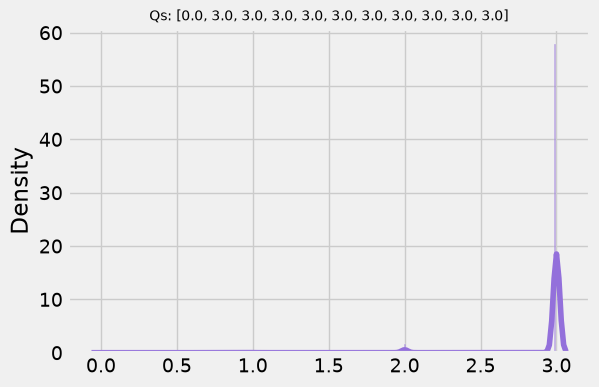

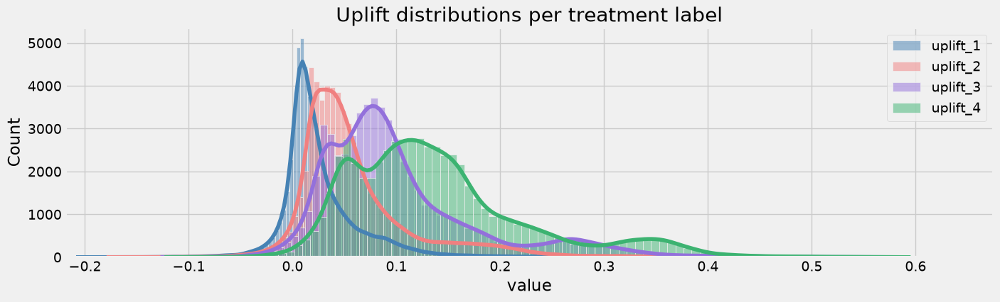

,prediction_0,prediction_1,prediction_2,prediction_3,prediction_4
299389,0.695317,0.690931,0.711589,0.711571,0.714453
299394,0.163968,0.251836,0.329742,0.453971,0.512465


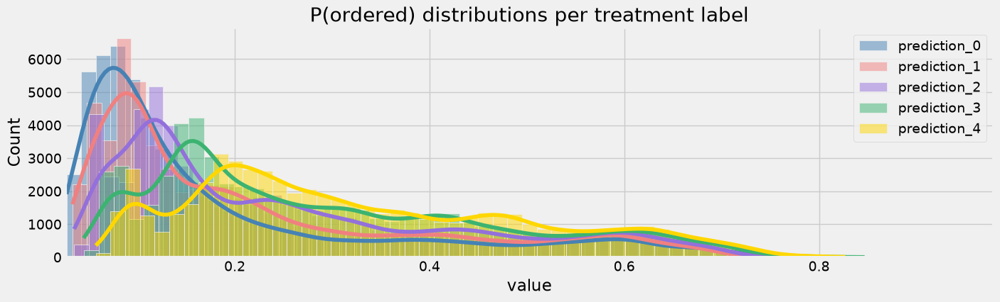

In [71]:
learner_type = 'URF'
learner = fitted_learners[learner_type]

uplift_predictions, control_prediction = learner.predict(oot_data[learner.features], return_baseline=True)

D = uplift_predictions
display(D.tail(2))
display(check_distr(D.values.argmax(axis = 1), figsize=(6, 4))['figure'])
fig, ax = plot_metric_distribution_by_classes(
    data = D.melt(), class_name='variable', metric_name='value',
    figsize=(15, 4),
    title = "Uplift distributions per treatment label",
)
display(fig)

P = convert_uplift_to_target_predictions(uplift_predictions, control_prediction)
display(P.tail(2))
fig, ax = plot_metric_distribution_by_classes(
    data = P.melt(), class_name='variable', metric_name='value',
    figsize=(15, 4),
    title = f"P({target_col}) distributions per treatment label",
)
display(fig)

Map expected cost values and utilization values w.r.t to FD assignments

In [72]:
u_mapping = utilization_rate_mapping.pivot(columns=treatment_col, index=aux_treatment_col).iloc[:, 1:].reset_index()
u_mapping.columns = [aux_treatment_col] + list(u_mapping.columns.get_level_values(1)[1:])
display(u_mapping)

c_mapping = avg_cost_mapping.pivot(columns=treatment_col, index=aux_treatment_col).iloc[:, :].reset_index()
c_mapping.columns = [aux_treatment_col] + list(c_mapping.columns.get_level_values(1)[1:])
display(c_mapping)

U = pd.merge(
    left = oot_data[aux_treatment_col].to_frame(),
    right = u_mapping,
    on = aux_treatment_col, how = 'left'
)
display(U.tail())

C = pd.merge(
    left = oot_data[aux_treatment_col].to_frame(),
    right = c_mapping,
    on = aux_treatment_col, how = 'left'
)
display(C.tail())

,free_delivery,1,2,3,4
0,0,0.336018,0.395537,0.459141,0.509003
1,1,0.317788,0.375701,0.450734,0.491934


,free_delivery,1,2,3,4
0,0,2.594142,5.190729,7.386402,8.568906
1,1,2.653653,5.288650,7.379801,8.594227


,free_delivery,1,2,3,4
60088,0,0.336018,0.395537,0.459141,0.509003
60089,1,0.317788,0.375701,0.450734,0.491934
60090,0,0.336018,0.395537,0.459141,0.509003
60091,0,0.336018,0.395537,0.459141,0.509003
60092,0,0.336018,0.395537,0.459141,0.509003


,free_delivery,1,2,3,4
60088,0,2.594142,5.190729,7.386402,8.568906
60089,1,2.653653,5.288650,7.379801,8.594227
60090,0,2.594142,5.190729,7.386402,8.568906
60091,0,2.594142,5.190729,7.386402,8.568906
60092,0,2.594142,5.190729,7.386402,8.568906


## Formulate the convex optimization problem

In [73]:
# P: (N, 5)
P = P.values
# D: (N, 4)
D = D.values
# U: (N, 4)
U = U.iloc[:, 1:].values
# C: (N, 4) - 
C = C.iloc[:, 1:].values
# A: (N, ) - AOV inputs
A = oot_data['aov_estimate'].values
# O: (N, ) - multiplier for more than 1 order in a week, we decided it's not making much sense
O = np.ones(len(oot_data))

# N = len(oot_data)

# incremental value
# V = O[:, None] * A[:, None] * (P[:, 1:] - P[:, 0])
V = O[:, None] * A[:, None] * D
# spend
S = P[:, 1:] * U[:, :] * C[:, :]

In [74]:
np.save(file='./tmp/S.npy', arr = S)
np.save(file='./tmp/V.npy', arr = V)

In [75]:
S = np.load('./tmp/S.npy')
V = np.load('./tmp/V.npy')

In [76]:
import cvxpy as cp
import numpy as np

total_budget_2weeks = 3500
B = total_budget_2weeks / 2

N, K = V.shape

### promo assignment matrix - technically continuous between 0 and 1, but we'll map to discrete values if required
X = cp.Variable((N, K), nonneg = True)
constraints = [
    cp.sum(X, axis=1) <= 1, ### at most 1 promo voucher per user
    cp.sum(cp.multiply(S, X)) <= B, ### budget limitations
]

problem = cp.Problem(cp.Maximize(cp.sum(cp.multiply(V, X))), constraints=constraints)

In [77]:
problem.solve(solver = cp.HIGHS)

22843.760895715634

In [78]:
problem.status, problem.value

('optimal', 22843.760895715634)

## Assignment analysis

size: 60093
min: 0, max: 1, mean: 0.13930075050338642, std: 0.3462629732165771
# missings: 0, # unique: 2


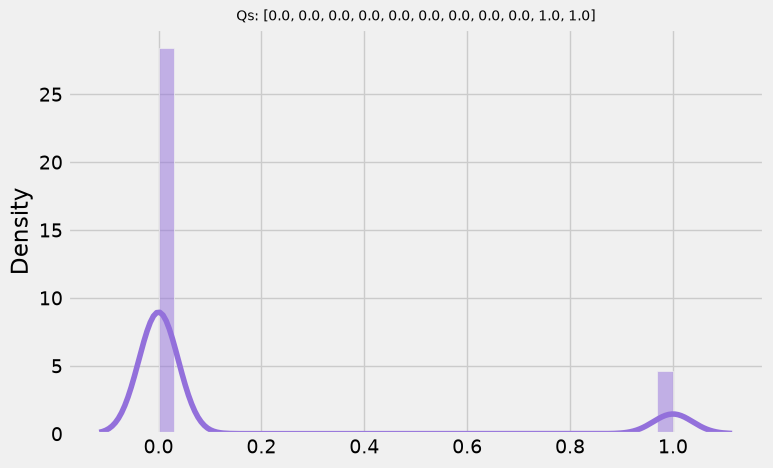

8371


In [79]:
is_assigned_discount = (X.value.sum(axis=1) > 0.5).astype(int)
display(check_distr(is_assigned_discount)['figure'])
n_assigned_treatment_policy = is_assigned_discount.sum()
print(n_assigned_treatment_policy)

Around 14% of total weekly population is getting some kind of a discount

In [80]:
projected_spend = (S * X.value).sum()
print(projected_spend, B)

1749.999999999999 1750.0


In [81]:
oot_data['treatment_assignment'] = np.where(
    is_assigned_discount, 
    X.value.argmax(axis = 1) + 1, ### shifting because left-most col is not control, but treatment 1
    0 ### if no selection meaning we're assigning control group
)
display(oot_data['treatment_assignment'].value_counts())
oot_data['assignment_match'] = (oot_data['treatment_assignment'] == oot_data[treatment_col]).astype(int)

treatment_assignment
0    51722
1     7828
2      365
3      138
4       40
Name: count, dtype: int64

We see that majority of assigned labels is given to 10% promo, probably mostly because the cost component for this is the smallest on average, but the conversion gain also exists from this promo

Let's see how our policy compares to existing random assignment

In [82]:
gb = (
    oot_data
    .groupby(['treatment_assignment', treatment_col])
    .agg({
        id_col: 'count',
        target_col: 'mean',
        'aov_estimate': 'mean',
    })
    .unstack(-1)
)
display(gb)

user_id                               ordered            \
voucher_pct                0      1      2      3      4         0         1   
treatment_assignment                                                           
0                      10383  10384  10343  10291  10321  0.245594  0.260786   
1                       1533   1523   1571   1613   1588  0.189172  0.239002   
2                         70     73     71     75     76  0.085714  0.287671   
3                         26     29     28     31     24  0.153846  0.206897   
4                         13     12      5      6      4  0.076923  0.000000   

                                                   aov_estimate             \
voucher_pct                  2         3         4            0          1   
treatment_assignment                                                         
0                     0.296142  0.321154  0.351323    20.292831  20.506100   
1                     0.306174  0.398016  0.460327    28.661752  28.508923   
2                     0.281690  0.413333  0.473684    45.766595  45.006349   
3                     0.214286  0.225806  0.416667    62.236554  60.650878   
4                     0.200000  0.166667  0.250000    63.702251  69.859207   

                                                       
voucher_pct                   2          3          4  
treatment_assignment                                   
0                     20.434971  20.347204  20.571314  
1                     29.192139  29.021038  29.147435  
2                     46.079856  45.325165  45.947885  
3                     59.051623  57.587970  56.383219  
4                     65.724070  61.503844  71.273675

voucher_pct,0,1,2,3,4
treatment_assignment,,,,,
0,0.0,0.015192,0.050549,0.075561,0.105729
1,0.0,0.049830,0.117003,0.208845,0.271156
2,0.0,0.201957,0.195976,0.327619,0.387970
3,0.0,0.053050,0.060440,0.071960,0.262821
4,0.0,-0.076923,0.123077,0.089744,0.173077


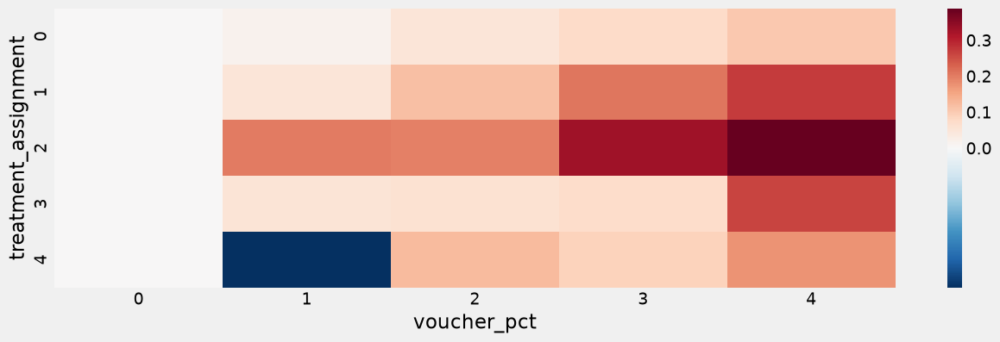

In [83]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm

gb = (
    oot_data
    .groupby(['treatment_assignment', treatment_col])
    .agg({
        target_col: 'mean',
        'aov_estimate': 'mean',
    })
    .unstack(-1)
)
for t_label in treatment_labels:
    # if t_label == CONTROL_LABEL:
    #     continue
    gb.loc[:, ('ATE_ORDER', t_label)] = gb.loc[:, (target_col, t_label)] - gb.loc[:, (target_col, CONTROL_LABEL)]
    gb.loc[:, ('ATE_AOV', t_label)] = gb.loc[:, ('aov_estimate', t_label)] * gb.loc[:, ('ATE_ORDER', t_label)]
display(gb.loc[:, 'ATE_ORDER'])
fig, ax = plt.subplots(1, 1, figsize = (14, 4))
vcenter = 0
vmin, vmax = gb.loc[:, 'ATE_ORDER'].min().min(), gb.loc[:, 'ATE_ORDER'].max().max()
normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
colormap = cm.RdBu_r
sns.heatmap(data=gb.loc[:, 'ATE_ORDER'], ax = ax, cmap = colormap, norm = normalize)
plt.close()
display(fig)

Let's interpret these readings:
- our assignments are uniform across randomized groups - that's expected

- each row off-diagonal shows what would this assignment cohort would've gained under other discounts, it's mostly growing left to right which is expected

- we do see some value left behind because e.g. for non-treatment cohort we would've gained more if treated them somehow, and also not all diagnonal values are maximums within their respective columns

- but we were really optimizing for incremental AOV, not incremental raw conversion

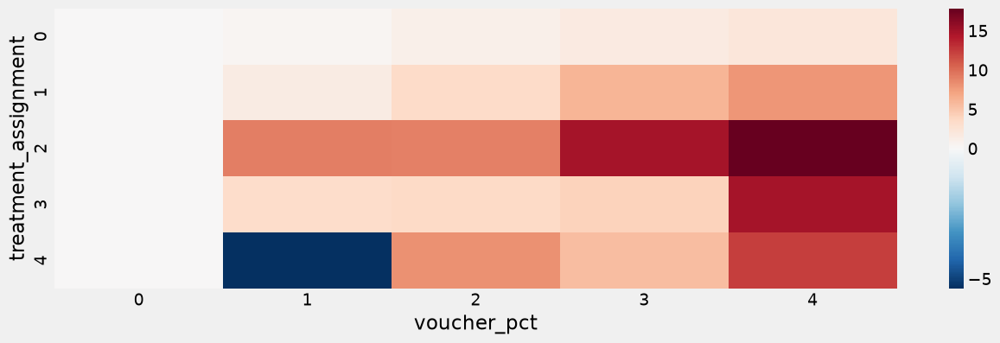

In [84]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm

fig, ax = plt.subplots(1, 1, figsize = (14, 4))
vcenter = 0
vmin, vmax = gb.loc[:, 'ATE_AOV'].min().min(), gb.loc[:, 'ATE_AOV'].max().max()
normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
colormap = cm.RdBu_r
sns.heatmap(data=gb.loc[:, 'ATE_AOV'], ax = ax, cmap = colormap, norm = normalize)
plt.close()
display(fig)

Let's check model scores distribution and compare them to empirical ATE

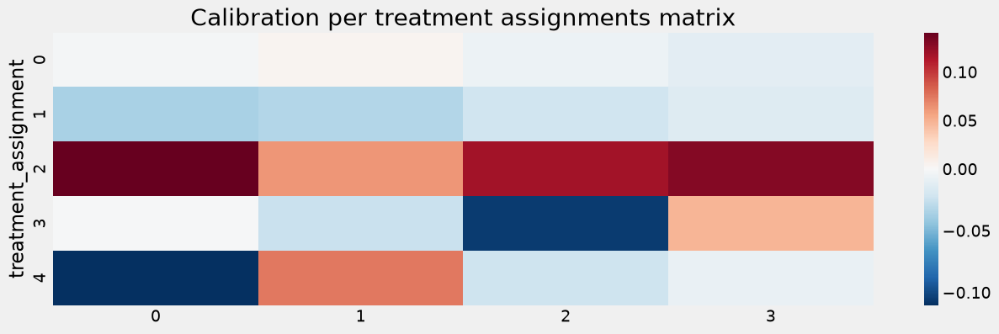

In [85]:
gb_scores = (
    oot_data
    .groupby(['treatment_assignment'])
    .agg({
        **{f"{learner_type}_{c}": 'mean' for c in uplift_predictions.columns},
    })
    # .unstack(-1)
)
fig, ax = plt.subplots(1, 1, figsize = (14, 4))
gb_calibration = pd.concat([gb.loc[:, ('ATE_ORDER')].iloc[:, 1:], gb_scores], axis = 1)
gb_calibration = pd.concat([gb_calibration.iloc[:, i] - gb_calibration.iloc[:, i + len(treatment_labels) - 1] for i in range(len(treatment_labels) - 1)], axis = 1)
vcenter = 0
vmin, vmax = gb_calibration.min().min(), gb_calibration.max().max()
normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
colormap = cm.RdBu_r
sns.heatmap(data = gb_calibration, cmap=colormap, norm = normalize, ax = ax)
ax.set_title('Calibration per treatment assignments matrix')
plt.close()
display(fig)

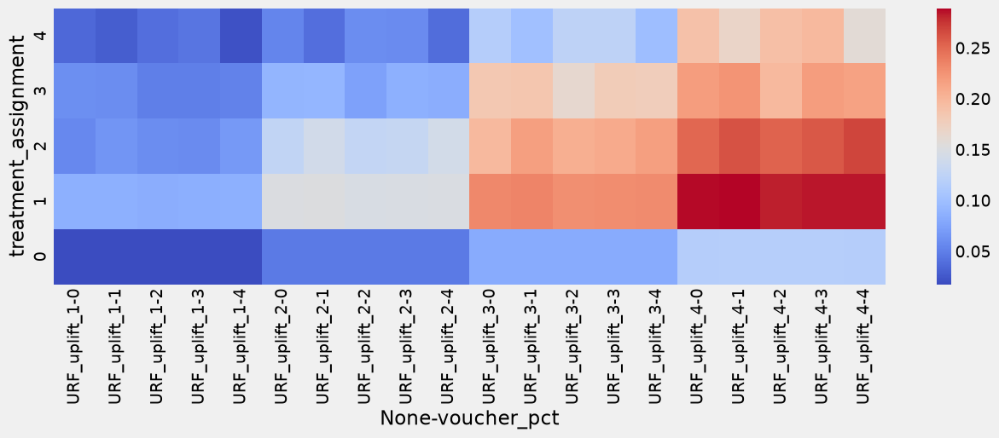

In [86]:
gb = (
    oot_data
    .groupby(['treatment_assignment', treatment_col])
    # .groupby(['treatment_assignment', ])
    .agg({
        **{f"{learner_type}_{c}": 'mean' for c in uplift_predictions.columns},
    })
    .unstack(-1)
)
fig, ax = plt.subplots(1, 1, figsize = (14, 4))
sns.heatmap(data=gb.sort_index(ascending=False), ax = ax, cmap='coolwarm')
plt.close()
display(fig)

We have clear pattern - within each of 4 vertical blocks of 5 randomized voucher groups there's hardly a differentiation across them

At the same time each of 4 uplift model scores groups increasing their average predictions with suggested promo voucher size decrease, except for no-assignment group where it expectedly drops to lowest value

That likely means
- Uplifts are positively correlated by promo groups across customers
- We might have managed to find the customers for whom the higher promo would've been efficient but we still getting an effect with lower promo while saving cost and targeting more customers

## Gain curve

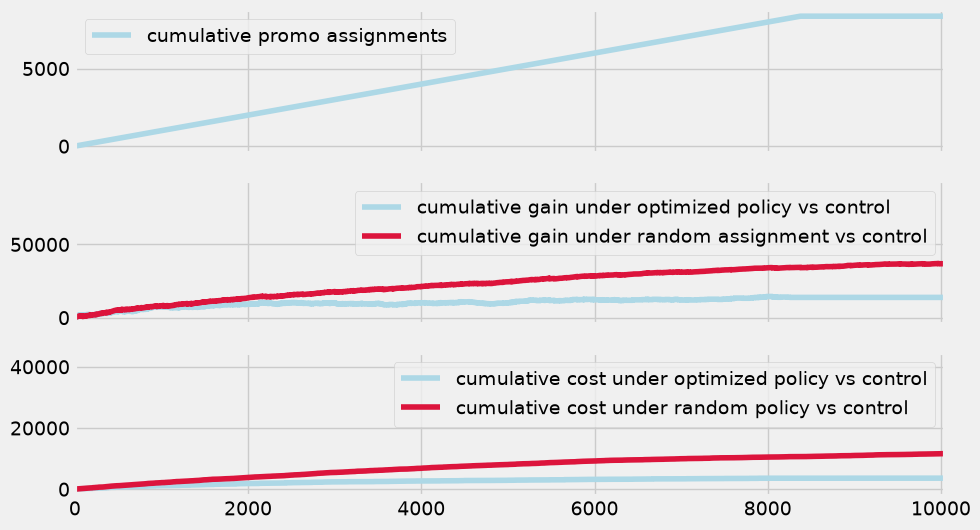

In [87]:
propensity_prob = 1 / len(treatment_labels)

Y = oot_data[target_col].values
a = oot_data['treatment_assignment'].to_numpy()
V_a = np.where(a > 0, V[np.arange(N), a - 1], 0.0)
C_a = np.where(a > 0, C[np.arange(N), a - 1], np.nan)
ratio = np.where(a > 0, V_a / C_a, -np.inf)
ordering = np.argsort(-ratio)

spend_real = oot_data[cost_col].fillna(0).values

matched = oot_data['assignment_match'].astype(float).values
no_treatment = (oot_data[treatment_col] == CONTROL_LABEL).astype(float).values
gain = ((matched - no_treatment) / propensity_prob) * A * Y  ### g_i = (1[D_i = policy-based d_i] * Y_i / e - 1[D_i = 0] / e * Y_i) * AOV
spend = ((matched - no_treatment) / propensity_prob) * spend_real

random_policy = np.ones(N)
gain_random = (random_policy - no_treatment / propensity_prob) * A * Y  ### g_i = (1[D_i = policy-based d_i] * Y_i / e - 1[D_i = 0] / e * Y_i) * AOV
spend_random = (random_policy - no_treatment / propensity_prob) * spend_real

cumulative_assignments = np.cumsum(is_assigned_discount[ordering])

cumulative_gain = np.cumsum(gain[ordering])
cumulative_cost = np.cumsum(spend[ordering])

cumulative_gain_random = np.cumsum(gain_random[ordering])
cumulative_cost_random = np.cumsum(spend_random[ordering])

fig, axes = plt.subplots(3, 1, sharex = True, figsize = (10, 6))
axes[0].plot(np.arange(N), cumulative_assignments, label = 'cumulative promo assignments', color = 'lightblue')
axes[1].plot(np.arange(N), cumulative_gain, label = 'cumulative gain under optimized policy vs control', color = 'lightblue')
axes[1].plot(np.arange(N), cumulative_gain_random, label = 'cumulative gain under random assignment vs control', color = 'crimson')
axes[2].plot(np.arange(N), cumulative_cost, label = 'cumulative cost under optimized policy vs control', color = 'lightblue')
axes[2].plot(np.arange(N), cumulative_cost_random, label = 'cumulative cost under random policy vs control', color = 'crimson')

axes[0].legend()
axes[1].legend()
axes[2].legend()

axes[0].set_xlim(0, n_assigned_treatment_policy * 1.2)
plt.close()
display(fig)

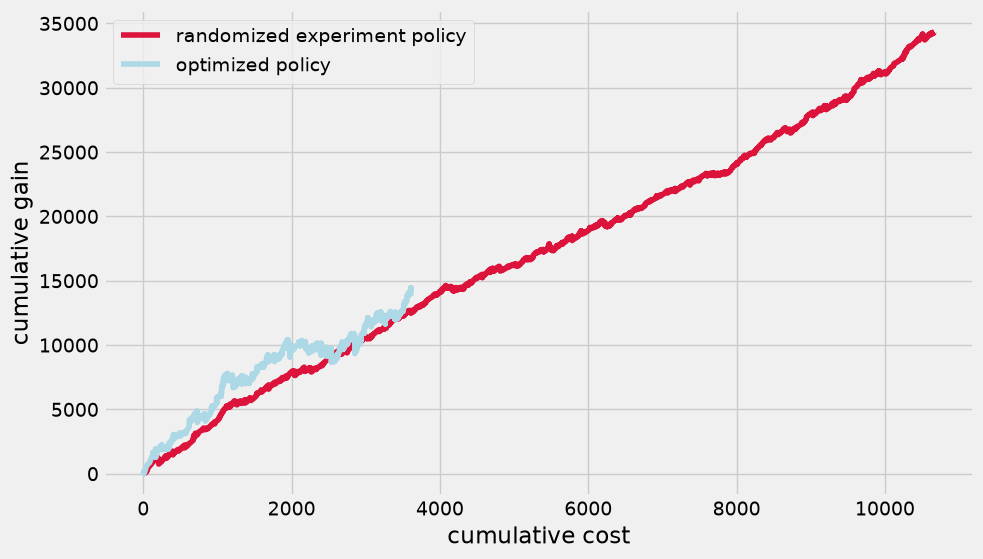

In [88]:
fig, ax = plt.subplots(1, 1, figsize = (10, 6))

n_limit = n_assigned_treatment_policy

ax.plot(cumulative_cost_random[:n_limit], cumulative_gain_random[:n_limit], color = 'crimson', label = 'randomized experiment policy')
ax.plot(cumulative_cost[:n_limit], cumulative_gain[:n_limit], color = 'lightblue', label = 'optimized policy')
ax.set_ylabel("cumulative gain")
ax.set_xlabel("cumulative cost")
ax.legend()
plt.close()
display(fig)

So good news is that our policy over performs random experiment assignment, but the bad news is that when we emit our assignments under budget constraints our actual cumulative cost exceeds what we set in constraints and quite significantly

size: 8371
min: 1.802821180873905, max: 9.0, mean: 6.96976414833981, std: 2.308554288582407
# missings: 6841, # unique: 931


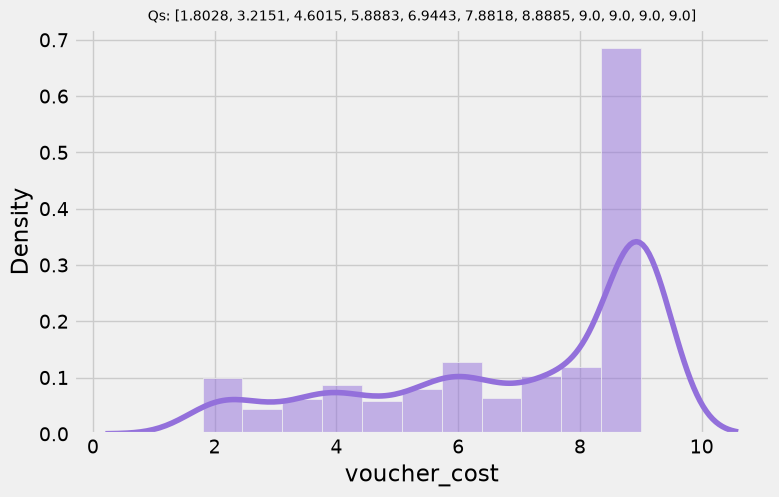

size: 60093
min: 1.8003810712243586, max: 9.0, mean: 6.61637729984816, std: 2.393538556410488
# missings: 53676, # unique: 4465


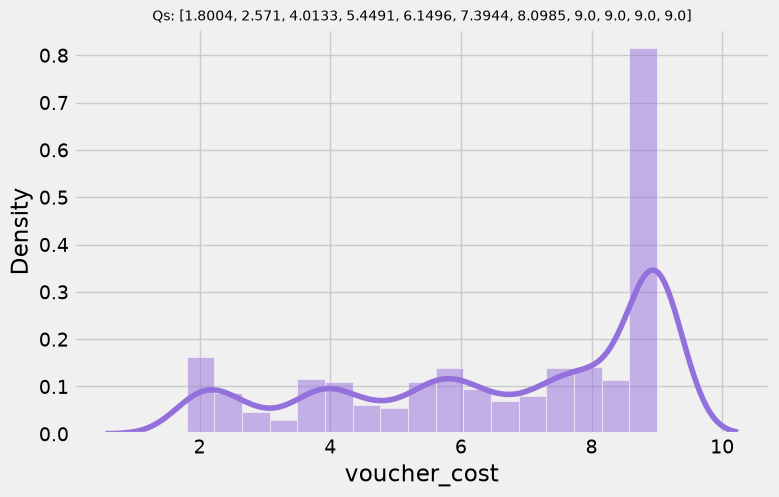

size: 8371
min: 0.0, max: 1.0, mean: 0.18277386214311314, std: 0.38650410482827774
# missings: 0, # unique: 2


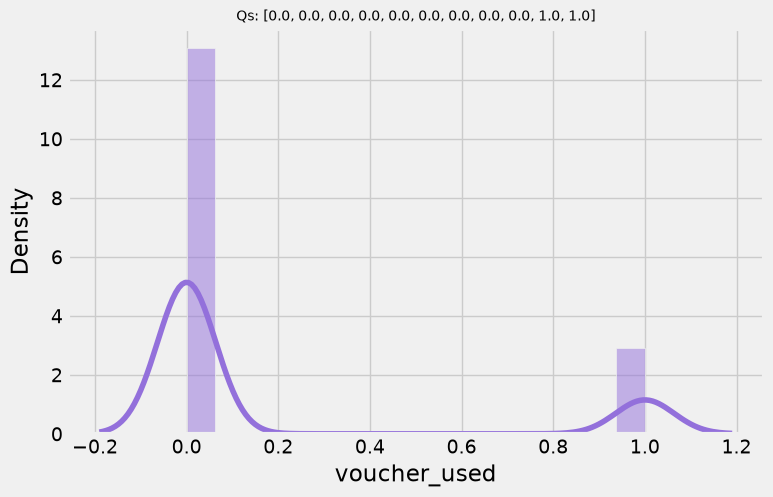

size: 60093
min: 0.0, max: 1.0, mean: 0.10678448404972293, std: 0.3088416184305382
# missings: 0, # unique: 2


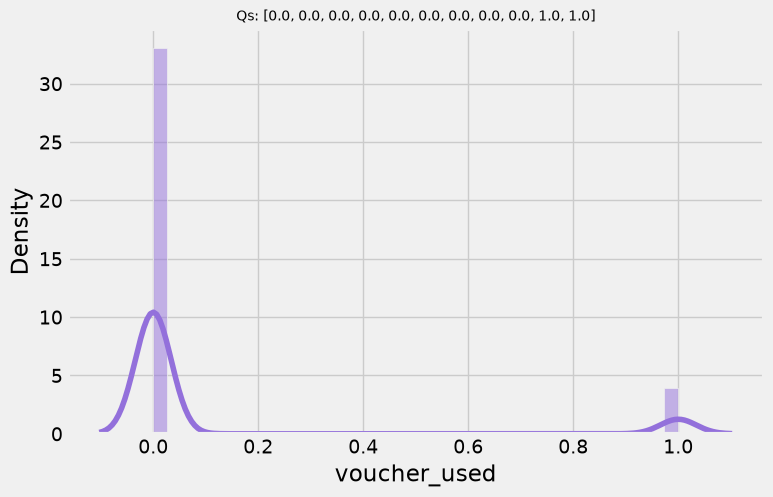

size: 8371
min: 13.61910629272461, max: 94.90827178955078, mean: 30.31725754054957, std: 9.394341285350363
# missings: 0, # unique: 8336


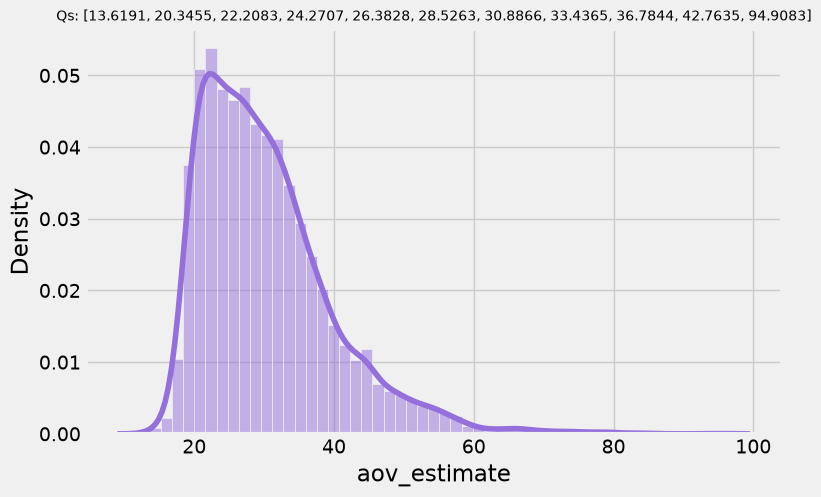

size: 60093
min: 3.454063892364502, max: 94.90827178955078, mean: 21.807699400473027, std: 7.481287042764714
# missings: 0, # unique: 50231


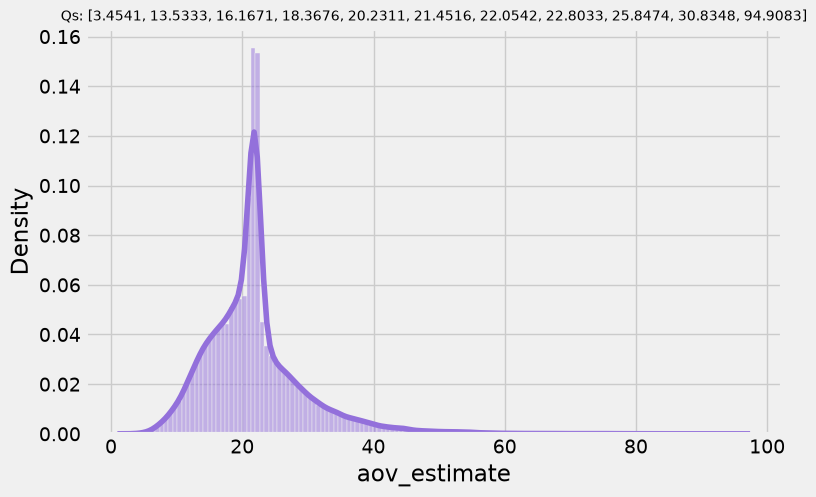

In [89]:
# display(check_distr(oot_data.loc[(oot_data['assignment_match'] == 1) & (oot_data['treatment_assignment'] > 0), cost_col])['figure'])
# display(check_distr(oot_data.loc[(oot_data['assignment_match'] == 1) & (oot_data['treatment_assignment'] > 0), utilization_col])['figure'])
display(check_distr(oot_data.loc[(oot_data['treatment_assignment'] > 0), cost_col])['figure'])
display(check_distr(oot_data.loc[:, cost_col])['figure'])
display(check_distr(oot_data.loc[(oot_data['treatment_assignment'] > 0), utilization_col])['figure'])
display(check_distr(oot_data.loc[:, utilization_col])['figure'])
display(check_distr(oot_data.loc[(oot_data['treatment_assignment'] > 0), 'aov_estimate'])['figure'])
display(check_distr(oot_data.loc[:, 'aov_estimate'])['figure'])

## Let's change the parametrization

We'll get rid of P(order) in the cost component and move to group-wise P(voucher_used|d, fd) (not conditioned on the fact of the order anymore) and we will not model cost as group average but rather tie it up to a AOV 

If that doesn't help we might try modelling P(voucher_used|d, fd, X)

voucher_used          
free_delivery            0         1
voucher_pct                         
0                 0.000000  0.000000
1                 0.071693  0.074570
2                 0.097470  0.098324
3                 0.132089  0.134740
4                 0.165846  0.164908

,voucher_pct,free_delivery,voucher_used
0,0,0,0.000000
1,1,0,0.071693
2,2,0,0.097470
3,3,0,0.132089
4,4,0,0.165846
5,0,1,0.000000
6,1,1,0.074570
7,2,1,0.098324
8,3,1,0.134740
9,4,1,0.164908


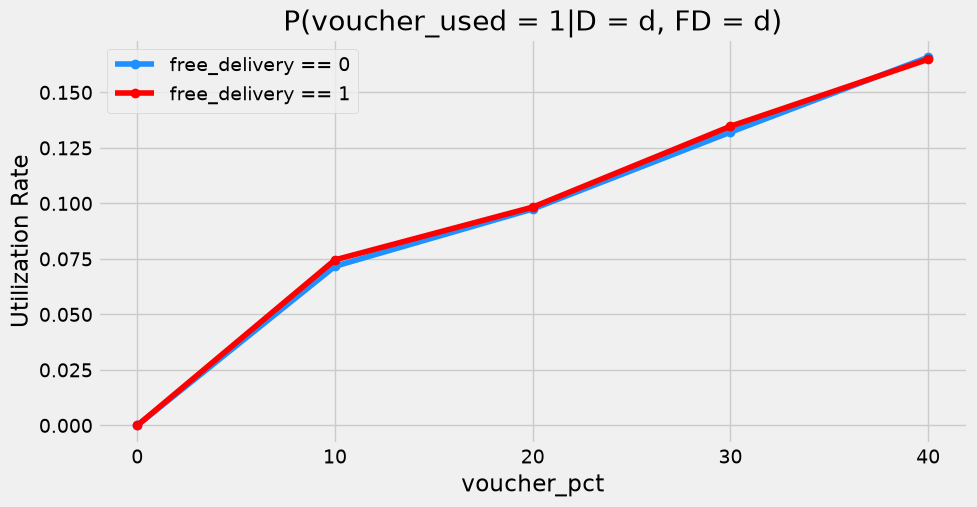

In [90]:
gb = analysis_data.loc[:, :].groupby([treatment_col, aux_treatment_col]).agg({utilization_col: 'mean'}).unstack(-1)
display(gb)
gb.columns = gb.columns.get_level_values(1)
utilization_rate_mapping = gb.reset_index().melt(id_vars = treatment_col, var_name = aux_treatment_col, value_name = utilization_col)
display(utilization_rate_mapping)

fig, ax = plt.subplots(1,1, figsize = (10, 5))
ax.plot(gb.iloc[:, 0].index.map(labels_mapping), gb.iloc[:, 0], marker = 'o', color = 'dodgerblue', label = f"{aux_treatment_col} == 0")
ax.plot(gb.iloc[:, 1].index.map(labels_mapping), gb.iloc[:, 1], marker = 'o', color = 'red', label = f"{aux_treatment_col} == 1")
ax.set_ylabel("Utilization Rate")
ax.set_xlabel(treatment_col)
ax.set_title("P(voucher_used = 1|D = d, FD = d)")
ax.legend()
plt.close()
display(fig)

In [91]:
u_mapping = utilization_rate_mapping.pivot(columns=treatment_col, index=aux_treatment_col).iloc[:, 1:].reset_index()
u_mapping.columns = [aux_treatment_col] + list(u_mapping.columns.get_level_values(1)[1:])
display(u_mapping)

U = pd.merge(
    left = oot_data[aux_treatment_col].to_frame(),
    right = u_mapping,
    on = aux_treatment_col, how = 'left'
)
display(U.tail())

,free_delivery,1,2,3,4
0,0,0.071693,0.097470,0.132089,0.165846
1,1,0.074570,0.098324,0.134740,0.164908


,free_delivery,1,2,3,4
60088,0,0.071693,0.097470,0.132089,0.165846
60089,1,0.074570,0.098324,0.134740,0.164908
60090,0,0.071693,0.097470,0.132089,0.165846
60091,0,0.071693,0.097470,0.132089,0.165846
60092,0,0.071693,0.097470,0.132089,0.165846


In [92]:
aov = oot_data['aov_estimate']
print(treatment_levels)

discounts = (pd.Series(treatment_levels[:]).astype(int) / 100).values
discounts_grid = np.tile(discounts, (len(aov), 1))
expected_voucher_cost = np.clip(discounts_grid * aov.values[:, None], 0, 9)

['0', '10', '20', '30', '40']


2026-10-28T23:02:05,023  INFO learners.py - Calculating predictions..


,uplift_1,uplift_2,uplift_3,uplift_4
299389,-0.004386,0.016273,0.016255,0.019136
299394,0.087868,0.165774,0.290002,0.348497


size: 60093
min: 0, max: 3, mean: 2.967766628392658, std: 0.18882459780410307
# missings: 0, # unique: 4


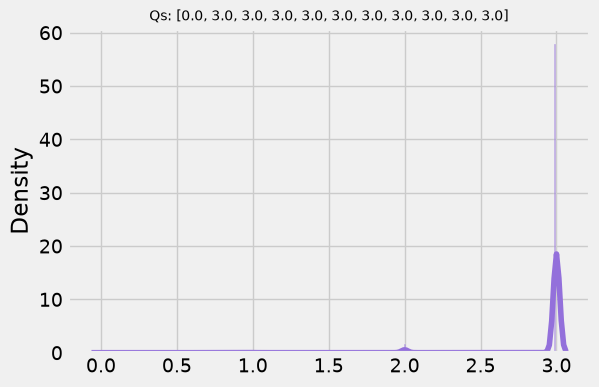

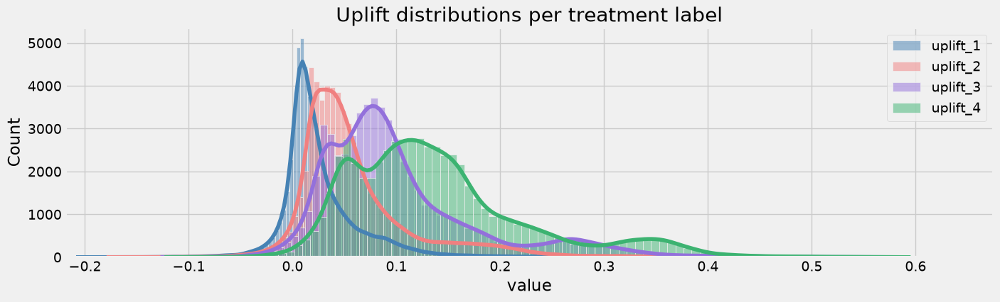

,prediction_0,prediction_1,prediction_2,prediction_3,prediction_4
299389,0.695317,0.690931,0.711589,0.711571,0.714453
299394,0.163968,0.251836,0.329742,0.453971,0.512465


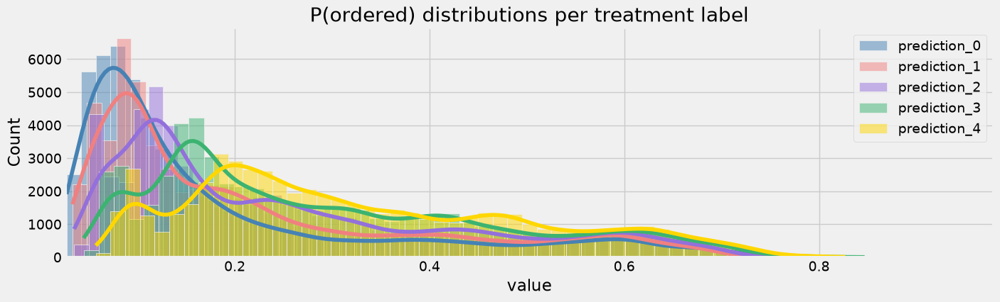

In [93]:
learner_type = 'URF'
learner = fitted_learners[learner_type]

uplift_predictions, control_prediction = learner.predict(oot_data[learner.features], return_baseline=True)
D = uplift_predictions
display(D.tail(2))
display(check_distr(D.values.argmax(axis = 1), figsize=(6, 4))['figure'])
fig, ax = plot_metric_distribution_by_classes(
    data = D.melt(), class_name='variable', metric_name='value',
    figsize=(15, 4),
    title = "Uplift distributions per treatment label",
)
display(fig)

P = convert_uplift_to_target_predictions(uplift_predictions, control_prediction)
display(P.tail(2))
fig, ax = plot_metric_distribution_by_classes(
    data = P.melt(), class_name='variable', metric_name='value',
    figsize=(15, 4),
    title = f"P({target_col}) distributions per treatment label",
)
display(fig)

In [94]:
# P: (N, 5)
P = P.values
# D: (N, 4)
D = D.values
# U: (N, 4)
U = U.iloc[:, 1:].values
# C: (N, 4) - 
C = expected_voucher_cost[:, 1:]
# A: (N, ) - AOV inputs
A = aov.values
# O: (N, ) - multiplier for more than 1 order in a week, we decided it's not making much sense
O = np.ones(len(oot_data))

# N = len(oot_data)

# incremental value
# V = O[:, None] * A[:, None] * (P[:, 1:] - P[:, 0])
V = O[:, None] * A[:, None] * D
# spend
# S = P[:, 1:] * U[:, :] * C[:, :]
S = U[:, :] * C[:, :]

In [95]:
import cvxpy as cp
import numpy as np

total_budget_2weeks = 3500
B = total_budget_2weeks / 2

N, K = V.shape

### promo assignment matrix - technically continuous between 0 and 1, but we'll map to discrete values if required
X = cp.Variable((N, K), nonneg = True)
constraints = [
    cp.sum(X, axis=1) <= 1, ### at most 1 promo voucher per user
    cp.sum(cp.multiply(S, X)) <= B, ### budget limitations
]

problem = cp.Problem(cp.Maximize(cp.sum(cp.multiply(V, X))), constraints=constraints)

problem.solve(solver = cp.HIGHS)
print(problem.status, problem.value)

optimal 24326.86938069888


### Assignment analysis repeated

size: 60093
min: 0, max: 1, mean: 0.11826668663571464, std: 0.3229263272043697
# missings: 0, # unique: 2


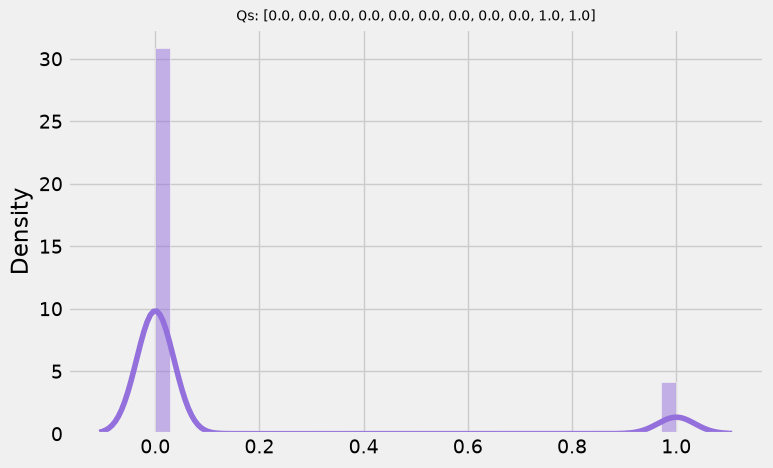

7107


In [96]:
is_assigned_discount = (X.value.sum(axis=1) > 0.5).astype(int)
display(check_distr(is_assigned_discount)['figure'])
n_assigned_treatment_policy = is_assigned_discount.sum()
print(n_assigned_treatment_policy)

Assigned share moved to 11%

In [97]:
projected_spend = (S * X.value).sum()
print(projected_spend, B)

1750.000000000004 1750.0


In [98]:
oot_data['treatment_assignment'] = np.where(
    is_assigned_discount, 
    X.value.argmax(axis = 1) + 1, ### shifting because left-most col is not control, but treatment 1
    0 ### if no selection meaning we're assigning control group
)
display(oot_data['treatment_assignment'].value_counts())
oot_data['assignment_match'] = (oot_data['treatment_assignment'] == oot_data[treatment_col]).astype(int)

treatment_assignment
0    52986
1     6196
2      684
3      152
4       75
Name: count, dtype: int64

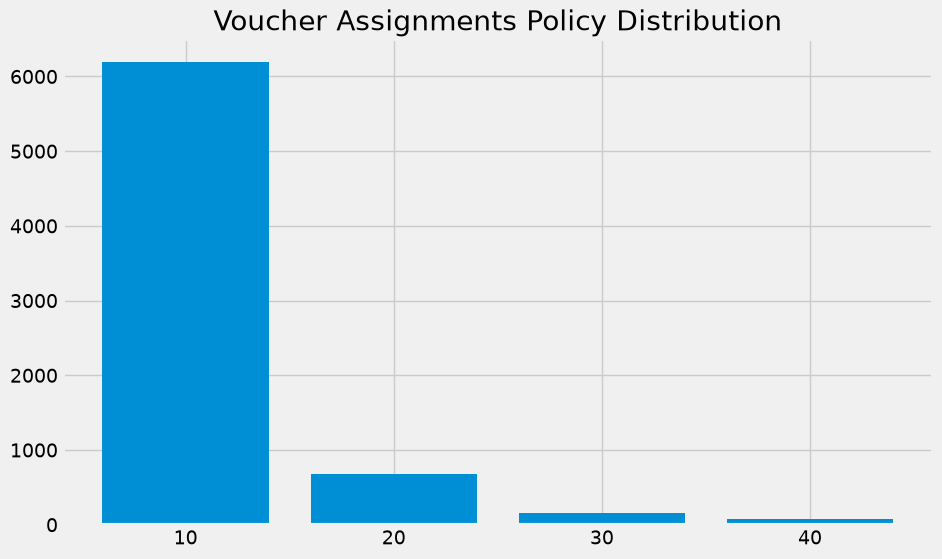

In [99]:
fig, ax = plt.subplots(1, 1, figsize = (10, 6))
vc = oot_data['treatment_assignment'].value_counts()
ax.bar(vc.loc[vc.index != CONTROL_LABEL].index, vc.loc[vc.index != CONTROL_LABEL])
ax.set_xticks(vc.loc[vc.index != CONTROL_LABEL].index)
ax.set_xticklabels(vc.loc[vc.index != CONTROL_LABEL].index.map(labels_mapping))
ax.set_title("Voucher Assignments Policy Distribution")
plt.close()
display(fig)

We see that majority of assigned labels is again given to 10% promo, probably mostly because the cost component for this is the smallest on average, but the conversion gain also exists from this promo

Let's see how our policy compares to existing random assignment

In [100]:
gb = (
    oot_data
    .groupby(['treatment_assignment', treatment_col])
    .agg({
        id_col: 'count',
        target_col: 'mean',
        'aov_estimate': 'mean',
    })
    .unstack(-1)
)
display(gb)

user_id                               ordered            \
voucher_pct                0      1      2      3      4         0         1   
treatment_assignment                                                           
0                      10652  10550  10608  10589  10587  0.229159  0.244076   
1                       1194   1296   1231   1248   1227  0.305695  0.351080   
2                        136    136    135    129    148  0.301471  0.411765   
3                         27     26     36     31     32  0.111111  0.346154   
4                         16     13      8     19     19  0.062500  0.307692   

                                                   aov_estimate             \
voucher_pct                  2         3         4            0          1   
treatment_assignment                                                         
0                     0.277903  0.309094  0.339190    21.184259  21.337052   
1                     0.428920  0.481571  0.555827    24.133623  24.348406   
2                     0.555556  0.635659  0.689189    26.180288  25.724275   
3                     0.444444  0.612903  0.531250    50.853109  52.038276   
4                     0.500000  0.578947  0.631579    55.315165  55.703930   

                                                       
voucher_pct                   2          3          4  
treatment_assignment                                   
0                     21.383732  21.278964  21.407151  
1                     24.217073  24.499844  24.780065  
2                     26.149081  25.428640  27.879853  
3                     51.150566  51.830526  49.753790  
4                     56.511698  51.150266  51.157964

voucher_pct,0,1,2,3,4
treatment_assignment,,,,,
0,0.0,0.014917,0.048745,0.079935,0.110031
1,0.0,0.045385,0.123224,0.175875,0.250132
2,0.0,0.110294,0.254085,0.334188,0.387719
3,0.0,0.235043,0.333333,0.501792,0.420139
4,0.0,0.245192,0.437500,0.516447,0.569079


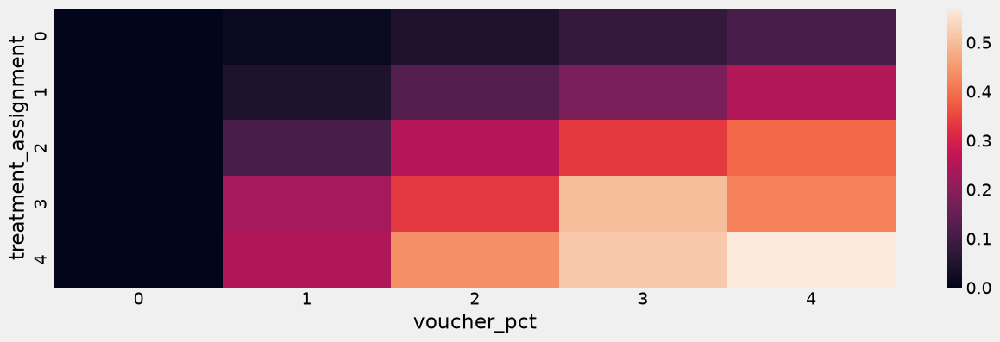

In [101]:
gb = (
    oot_data
    .groupby(['treatment_assignment', treatment_col])
    .agg({
        target_col: 'mean',
        'aov_estimate': 'mean',
    })
    .unstack(-1)
)
for t_label in treatment_labels:
    # if t_label == CONTROL_LABEL:
    #     continue
    gb.loc[:, ('ATE_ORDER', t_label)] = gb.loc[:, (target_col, t_label)] - gb.loc[:, (target_col, CONTROL_LABEL)]
    gb.loc[:, ('ATE_AOV', t_label)] = gb.loc[:, ('aov_estimate', t_label)] * gb.loc[:, ('ATE_ORDER', t_label)]
display(gb.loc[:, 'ATE_ORDER'])
fig, ax = plt.subplots(1, 1, figsize = (14, 4))
# vcenter = 0
# vmin, vmax = gb.loc[:, 'ATE_ORDER'].min().min(), gb.loc[:, 'ATE_ORDER'].max().max()
# normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
# colormap = cm.RdBu_r
sns.heatmap(data=gb.loc[:, 'ATE_ORDER'], ax = ax,)# cmap = colormap, norm = normalize)
plt.close()
display(fig)

Let's interpret these readings:
- our assignments are uniform across randomized groups - that's expected

- each row off-diagonal shows what would this assignment cohort would've gained under other discounts, it's mostly growing left to right which is expected

- we do see some value left behind because e.g. for non-treatment cohort we would've gained more if treated them somehow, and also not all diagnonal values are maximums within their respective columns

- but we were really optimizing for incremental AOV, not incremental raw conversion

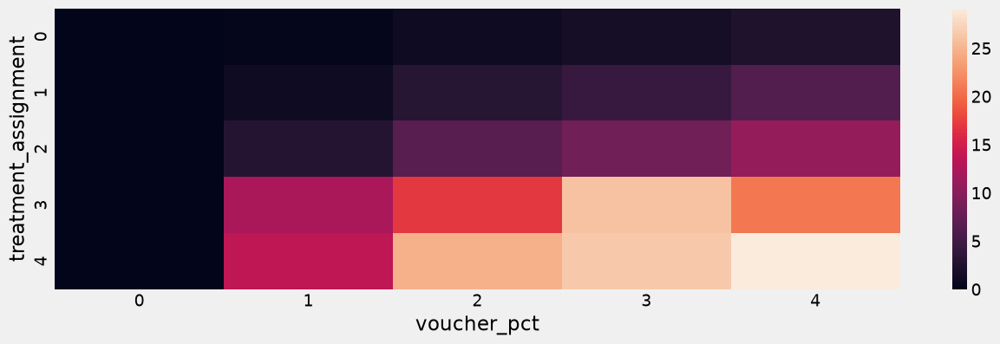

In [102]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm

fig, ax = plt.subplots(1, 1, figsize = (14, 4))
# vcenter = 0
# vmin, vmax = gb.loc[:, 'ATE_AOV'].min().min(), gb.loc[:, 'ATE_AOV'].max().max()
# normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
# colormap = cm.RdBu_r
sns.heatmap(data=gb.loc[:, 'ATE_AOV'], ax = ax,)# cmap = colormap, norm = normalize)
plt.close()
display(fig)

Let's check model scores distribution and compare them to empirical ATE

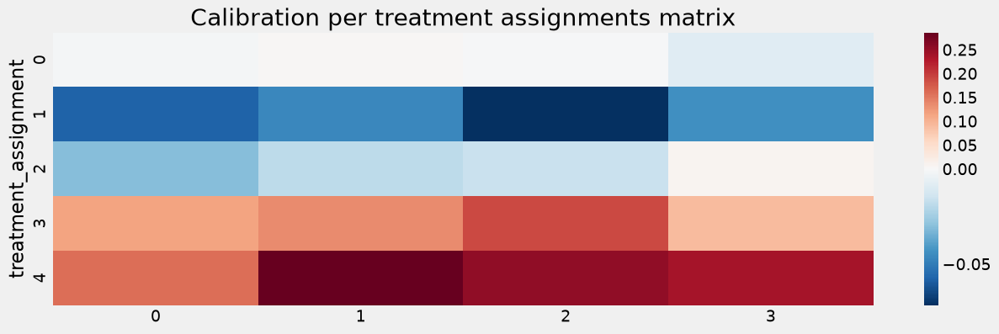

In [103]:
gb_scores = (
    oot_data
    .groupby(['treatment_assignment'])
    .agg({
        **{f"{learner_type}_{c}": 'mean' for c in uplift_predictions.columns},
    })
    # .unstack(-1)
)
fig, ax = plt.subplots(1, 1, figsize = (14, 4))
gb_calibration = pd.concat([gb.loc[:, ('ATE_ORDER')].iloc[:, 1:], gb_scores], axis = 1)
gb_calibration = pd.concat([gb_calibration.iloc[:, i] - gb_calibration.iloc[:, i + len(treatment_labels) - 1] for i in range(len(treatment_labels) - 1)], axis = 1)
vcenter = 0
vmin, vmax = gb_calibration.min().min(), gb_calibration.max().max()
normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
colormap = cm.RdBu_r
sns.heatmap(data = gb_calibration, cmap=colormap, norm = normalize, ax = ax)
ax.set_title('Calibration per treatment assignments matrix')
plt.close()
display(fig)

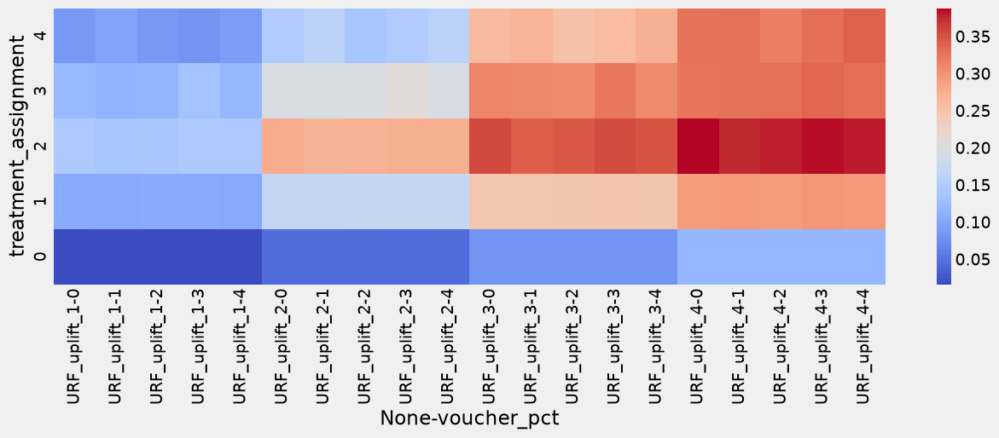

In [104]:
gb = (
    oot_data
    .groupby(['treatment_assignment', treatment_col])
    # .groupby(['treatment_assignment', ])
    .agg({
        **{f"{learner_type}_{c}": 'mean' for c in uplift_predictions.columns},
    })
    .unstack(-1)
)
fig, ax = plt.subplots(1, 1, figsize = (14, 4))
sns.heatmap(data=gb.sort_index(ascending=False), ax = ax, cmap='coolwarm')
plt.close()
display(fig)

We have clear pattern - within each of 4 vertical blocks of 5 randomized voucher groups there's hardly a differentiation across them

At the same time each of 4 uplift model scores groups increasing their average predictions with suggested promo voucher size decrease, except for no-assignment group where it expectedly drops to lowest value

That likely means
- Uplifts are positively correlated by promo groups across customers
- We might have managed to find the customers for whom the higher promo would've been efficient but we still getting an effect with lower promo while saving cost and targeting more customers

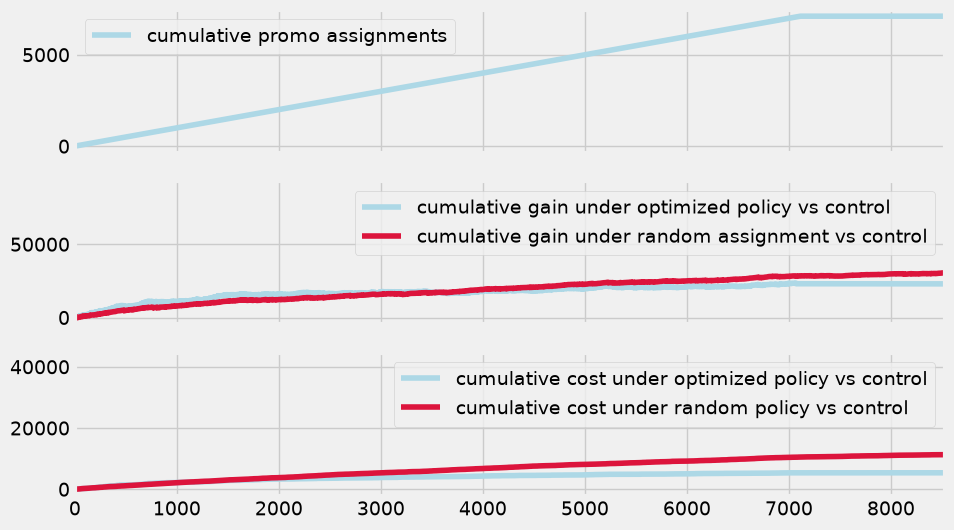

In [105]:
propensity_prob = 1 / len(treatment_labels)

Y = oot_data[target_col].values
a = oot_data['treatment_assignment'].to_numpy()
V_a = np.where(a > 0, V[np.arange(N), a - 1], 0.0)
C_a = np.where(a > 0, C[np.arange(N), a - 1], np.nan)
ratio = np.where(a > 0, V_a / C_a, -np.inf)
ordering = np.argsort(-ratio)

spend_real = oot_data[cost_col].fillna(0).values

matched = oot_data['assignment_match'].astype(float).values
no_treatment = (oot_data[treatment_col] == CONTROL_LABEL).astype(float).values
gain = ((matched - no_treatment) / propensity_prob) * A * Y  ### g_i = (1[D_i = policy-based d_i] * Y_i / e - 1[D_i = 0] / e * Y_i) * AOV
spend = ((matched - no_treatment) / propensity_prob) * spend_real

random_policy = np.ones(N)
gain_random = (random_policy - no_treatment / propensity_prob) * A * Y  ### g_i = (1[D_i = policy-based d_i] * Y_i / e - 1[D_i = 0] / e * Y_i) * AOV
spend_random = (random_policy - no_treatment / propensity_prob) * spend_real

cumulative_assignments = np.cumsum(is_assigned_discount[ordering])

cumulative_gain = np.cumsum(gain[ordering])
cumulative_cost = np.cumsum(spend[ordering])

cumulative_gain_random = np.cumsum(gain_random[ordering])
cumulative_cost_random = np.cumsum(spend_random[ordering])

fig, axes = plt.subplots(3, 1, sharex = True, figsize = (10, 6))
axes[0].plot(np.arange(N), cumulative_assignments, label = 'cumulative promo assignments', color = 'lightblue')
axes[1].plot(np.arange(N), cumulative_gain, label = 'cumulative gain under optimized policy vs control', color = 'lightblue')
axes[1].plot(np.arange(N), cumulative_gain_random, label = 'cumulative gain under random assignment vs control', color = 'crimson')
axes[2].plot(np.arange(N), cumulative_cost, label = 'cumulative cost under optimized policy vs control', color = 'lightblue')
axes[2].plot(np.arange(N), cumulative_cost_random, label = 'cumulative cost under random policy vs control', color = 'crimson')

axes[0].legend()
axes[1].legend()
axes[2].legend()

axes[0].set_xlim(0, n_assigned_treatment_policy * 1.2)
plt.close()
display(fig)

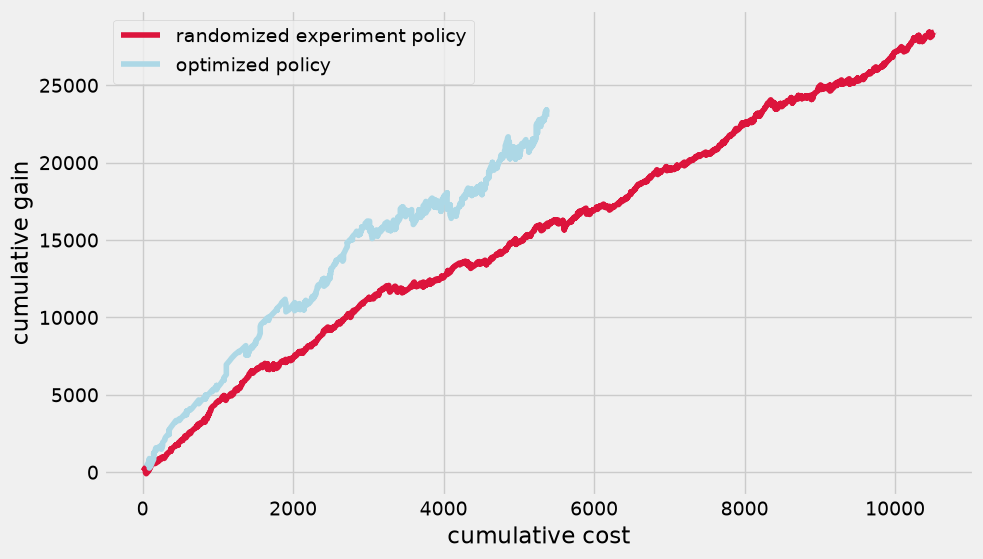

In [106]:
fig, ax = plt.subplots(1, 1, figsize = (10, 6))

n_limit = n_assigned_treatment_policy

ax.plot(cumulative_cost_random[:n_limit], cumulative_gain_random[:n_limit], color = 'crimson', label = 'randomized experiment policy')
ax.plot(cumulative_cost[:n_limit], cumulative_gain[:n_limit], color = 'lightblue', label = 'optimized policy')
ax.set_ylabel("cumulative gain")
ax.set_xlabel("cumulative cost")
ax.legend()
plt.close()
display(fig)

In [107]:
gb = (
    oot_data
    .groupby(treatment_col)
    .agg({
        utilization_col: 'mean',
        'aov_estimate': 'mean',
        cost_col: 'sum',
        id_col: 'count',
    })
    .reset_index()
)

gb['projected_cost'] = gb[treatment_col].map(labels_mapping).astype(int) / 100 * gb['aov_estimate'] * gb[utilization_col] 
gb['average_cost'] = gb[cost_col] / gb[id_col]
display(gb)


gb = (
    oot_data
    .groupby('treatment_assignment')
    .agg({
        utilization_col: 'mean',
        'aov_estimate': 'mean',
        cost_col: 'sum',
        id_col: 'count',
    })
    .reset_index()
)

gb['projected_cost'] = gb['treatment_assignment'].map(labels_mapping).astype(int) / 100 * gb['aov_estimate'] * gb[utilization_col] 
gb['average_cost'] = gb[cost_col] / gb[id_col]
display(gb)

,voucher_pct,voucher_used,aov_estimate,voucher_cost,user_id,projected_cost,average_cost
0,0,0.000000,21.645644,0.000000,12025,0.000000,0.000000
1,1,0.085600,21.814914,2704.231187,12021,0.186736,0.224959
2,2,0.113746,21.840031,7258.187348,12018,0.496843,0.603943
3,3,0.147969,21.784092,13177.607629,12016,0.967014,1.096672
4,4,0.186714,21.953966,19317.266970,12013,1.639649,1.608030


,treatment_assignment,voucher_used,aov_estimate,voucher_cost,user_id,projected_cost,average_cost
0,0,0.091402,21.318079,31937.810991,52986,0.000000,0.602759
1,1,0.208037,24.396908,8507.108724,6196,0.507547,1.373000
2,2,0.315789,26.309443,1471.900150,684,1.661649,2.151901
3,3,0.276316,51.094192,321.423640,152,4.235440,2.114629
4,4,0.360000,53.401916,219.049629,75,7.689876,2.920662


Again we have similar problem - even worse really with overspend, that's because as we can see utilization rate for our assignment groups is not matching the average as per experiment treatment groups

Policy became more effective compared to previous version, but we need to control for spend better

## Let's model expected utilization rate now

In [108]:
utilization_model = LGBMClassifier(**boost_params)

utilization_model_features = num_feature_cols + additional_features + [treatment_col, aux_treatment_col]
utilization_model_mask = (analysis_data[treatment_col] != CONTROL_LABEL)

utilization_model.fit(
    analysis_data.loc[utilization_model_mask, utilization_model_features],
    analysis_data.loc[utilization_model_mask, utilization_col],
)

,num_leaves,32
,max_depth,5
,learning_rate,0.005
,n_estimators,300
,min_child_samples,100
,subsample,0.7
,reg_alpha,0.1
,reg_lambda,0.1
,verbosity,-1
,boosting_type,'gbdt'
,subsample_for_bin,200000


In [109]:
oot_data[f'{utilization_col}_estimate'] = utilization_model.predict_proba(oot_data[utilization_model_features])[:, 1]
print(roc_auc_score(oot_data.query(f"{treatment_col} != {CONTROL_LABEL}")[utilization_col], oot_data.query(f"{treatment_col} != {CONTROL_LABEL}")[f'{utilization_col}_estimate']))

0.7776640575996359


That's promising

Let's re-create U matrix

In [110]:
U_X = oot_data.loc[:, num_feature_cols + additional_features + [treatment_col, aux_treatment_col]].copy()

U_estimate = []
for t_label in tqdm(treatment_labels):
    if t_label == CONTROL_LABEL:
        continue
    U_X[treatment_col] = t_label
    U_estimate_t = pd.Series(utilization_model.predict_proba(U_X)[:, 1], index = U_X.index, name = f"U_estimate_{t_label}")
    U_estimate.append(U_estimate_t)

U_estimate = pd.concat(U_estimate, axis = 1)
display(U_estimate.tail())

  0%|          | 0/5 [00:00<?, ?it/s]

,U_estimate_1,U_estimate_2,U_estimate_3,U_estimate_4
299374,0.056849,0.058567,0.074477,0.083379
299379,0.075921,0.085435,0.107119,0.138856
299384,0.057672,0.062523,0.070644,0.073301
299389,0.244622,0.265718,0.276314,0.283382
299394,0.215744,0.275419,0.351087,0.360748


In [111]:
aov = oot_data['aov_estimate']
print(treatment_levels)

discounts = (pd.Series(treatment_levels[:]).astype(int) / 100).values
discounts_grid = np.tile(discounts, (len(aov), 1))
expected_voucher_cost = np.clip(discounts_grid * aov.values[:, None], 0, 9)

['0', '10', '20', '30', '40']


2026-10-28T23:02:44,861  INFO learners.py - Calculating predictions..


,uplift_1,uplift_2,uplift_3,uplift_4
299389,-0.004386,0.016273,0.016255,0.019136
299394,0.087868,0.165774,0.290002,0.348497


size: 60093
min: 0, max: 3, mean: 2.967766628392658, std: 0.18882459780410307
# missings: 0, # unique: 4


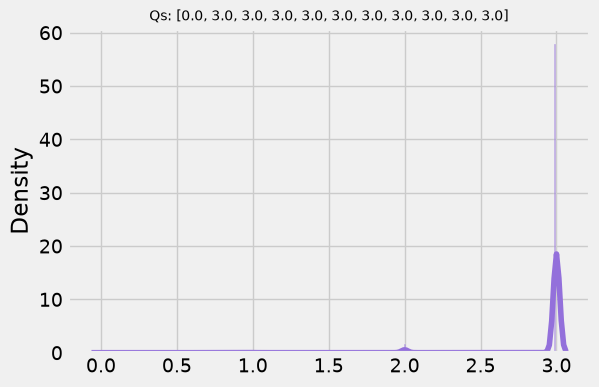

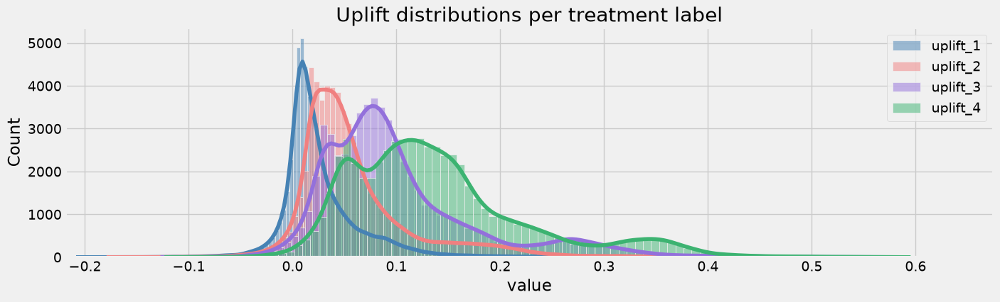

,prediction_0,prediction_1,prediction_2,prediction_3,prediction_4
299389,0.695317,0.690931,0.711589,0.711571,0.714453
299394,0.163968,0.251836,0.329742,0.453971,0.512465


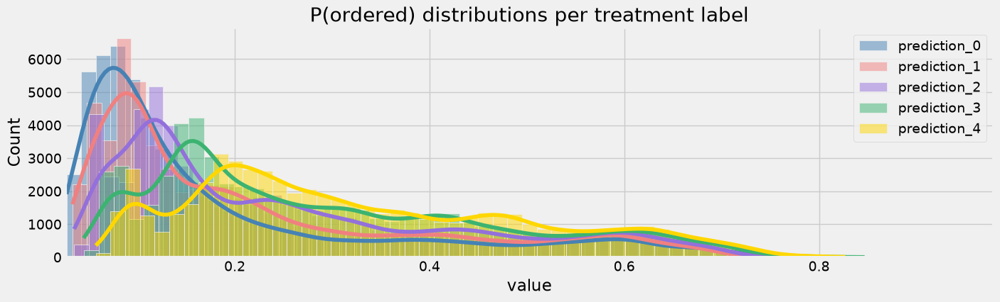

In [112]:
learner_type = 'URF'
learner = fitted_learners[learner_type]

uplift_predictions, control_prediction = learner.predict(oot_data[learner.features], return_baseline=True)
D = uplift_predictions
display(D.tail(2))
display(check_distr(D.values.argmax(axis = 1), figsize=(6, 4))['figure'])
fig, ax = plot_metric_distribution_by_classes(
    data = D.melt(), class_name='variable', metric_name='value',
    figsize=(15, 4),
    title = "Uplift distributions per treatment label",
)
display(fig)

P = convert_uplift_to_target_predictions(uplift_predictions, control_prediction)
display(P.tail(2))
fig, ax = plot_metric_distribution_by_classes(
    data = P.melt(), class_name='variable', metric_name='value',
    figsize=(15, 4),
    title = f"P({target_col}) distributions per treatment label",
)
display(fig)

In [113]:
# P: (N, 5)
P = P.values
# D: (N, 4)
D = D.values
# U: (N, 4)
# U = U.iloc[:, 1:].values
U = U_estimate.iloc[:, :].values
# C: (N, 4) - 
C = expected_voucher_cost[:, 1:]
# A: (N, ) - AOV inputs
A = aov.values
# O: (N, ) - multiplier for more than 1 order in a week, we decided it's not making much sense
O = np.ones(len(oot_data))

# N = len(oot_data)

# incremental value
# V = O[:, None] * A[:, None] * (P[:, 1:] - P[:, 0])
V = O[:, None] * A[:, None] * D
# spend
# S = P[:, 1:] * U[:, :] * C[:, :]
S = U[:, :] * C[:, :]

In [114]:
import cvxpy as cp
import numpy as np

total_budget_2weeks = 3500
B = total_budget_2weeks / 2

N, K = V.shape

### promo assignment matrix - technically continuous between 0 and 1, but we'll map to discrete values if required
X = cp.Variable((N, K), nonneg = True)
constraints = [
    cp.sum(X, axis=1) <= 1, ### at most 1 promo voucher per user
    cp.sum(cp.multiply(S, X)) <= B, ### budget limitations
]

problem = cp.Problem(cp.Maximize(cp.sum(cp.multiply(V, X))), constraints=constraints)

problem.solve(solver = cp.HIGHS)
print(problem.status, problem.value)

optimal 16270.547742713075


### Assignment analysis repeated

size: 60093
min: 0, max: 1, mean: 0.08601667415505966, std: 0.2803910023754
# missings: 0, # unique: 2


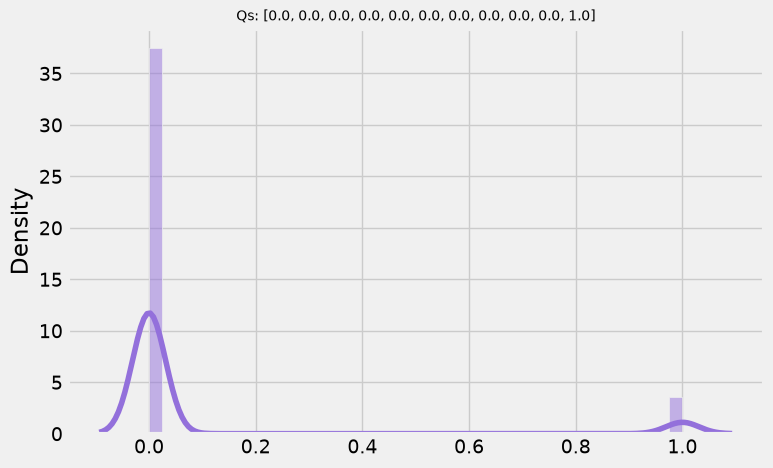

5169


In [115]:
is_assigned_discount = (X.value.sum(axis=1) > 0.5).astype(int)
display(check_distr(is_assigned_discount)['figure'])
n_assigned_treatment_policy = is_assigned_discount.sum()
print(n_assigned_treatment_policy)

Assigned share moved to 8% now

In [116]:
projected_spend = (S * X.value).sum()
print(projected_spend, B)

1749.999999999995 1750.0


In [117]:
oot_data['treatment_assignment'] = np.where(
    is_assigned_discount, 
    X.value.argmax(axis = 1) + 1, ### shifting because left-most col is not control, but treatment 1
    0 ### if no selection meaning we're assigning control group
)
display(oot_data['treatment_assignment'].value_counts())
oot_data['assignment_match'] = (oot_data['treatment_assignment'] == oot_data[treatment_col]).astype(int)

treatment_assignment
0    54924
1     4231
4      457
2      346
3      135
Name: count, dtype: int64

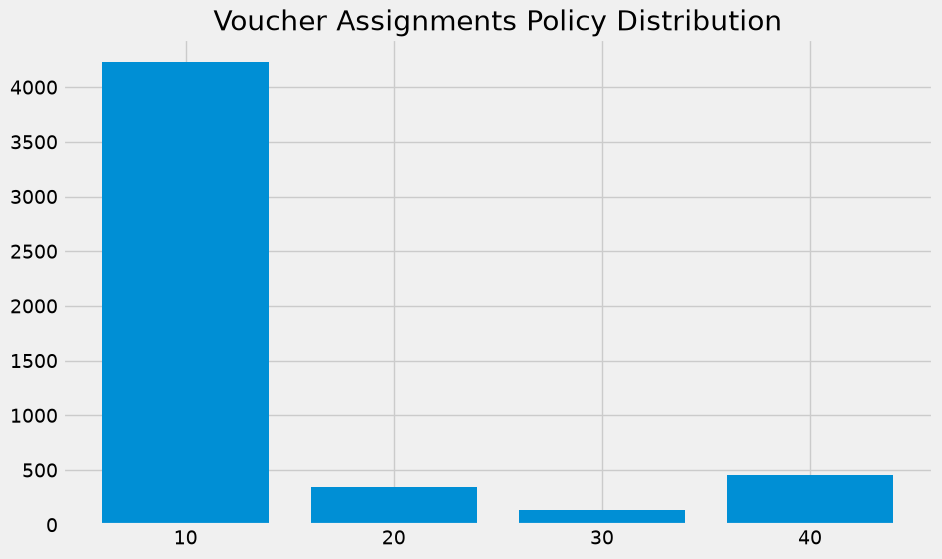

In [118]:
fig, ax = plt.subplots(1, 1, figsize = (10, 6))
vc = oot_data['treatment_assignment'].value_counts()
ax.bar(vc.loc[vc.index != CONTROL_LABEL].index, vc.loc[vc.index != CONTROL_LABEL])
ax.set_xticks(vc.loc[vc.index != CONTROL_LABEL].index)
ax.set_xticklabels(vc.loc[vc.index != CONTROL_LABEL].index.map(labels_mapping))
ax.set_title("Voucher Assignments Policy Distribution")
plt.close()
display(fig)

We see that majority of assigned labels is again given to 10% promo, probably mostly because the cost component for this is the smallest on average, but the conversion gain also exists from this promo

Let's see how our policy compares to existing random assignment

In [119]:
gb = (
    oot_data
    .groupby(['treatment_assignment', treatment_col])
    .agg({
        id_col: 'count',
        target_col: 'mean',
        'aov_estimate': 'mean',
    })
    .unstack(-1)
)
display(gb)

user_id                               ordered            \
voucher_pct                0      1      2      3      4         0         1   
treatment_assignment                                                           
0                      10988  10966  11016  10935  11019  0.238624  0.258344   
1                        855    868    802    888    818  0.238596  0.268433   
2                         69     61     73     71     72  0.144928  0.213115   
3                         31     33     32     24     15  0.258065  0.212121   
4                         82     93     95     98     89  0.085366  0.139785   

                                                   aov_estimate             \
voucher_pct                  2         3         4            0          1   
treatment_assignment                                                         
0                     0.296206  0.328761  0.362737    21.376128  21.504326   
1                     0.325436  0.387387  0.436430    21.964975  22.463882   
2                     0.205479  0.211268  0.263889    18.888559  18.085430   
3                     0.281250  0.500000  0.400000    43.421190  42.622486   
4                     0.242105  0.204082  0.280899    48.518923  47.443469   

                                                       
voucher_pct                   2          3          4  
treatment_assignment                                   
0                     21.557097  21.469648  21.690252  
1                     22.192054  22.746298  22.704478  
2                     19.160429  19.332000  20.185289  
3                     45.894671  45.935844  46.702844  
4                     45.633032  44.013343  44.965815

voucher_pct,0,1,2,3,4
treatment_assignment,,,,,
0,0.0,0.019720,0.057582,0.090137,0.124113
1,0.0,0.029837,0.086840,0.148791,0.197834
2,0.0,0.068187,0.060552,0.066340,0.118961
3,0.0,-0.045943,0.023185,0.241935,0.141935
4,0.0,0.054419,0.156739,0.118716,0.195533


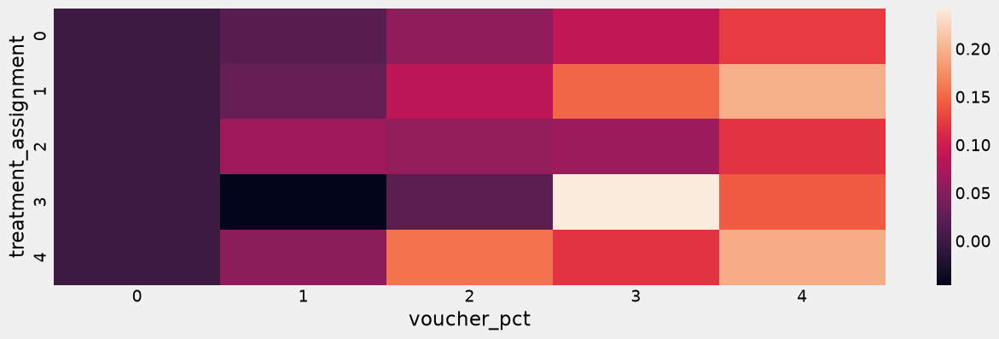

In [120]:
gb = (
    oot_data
    .groupby(['treatment_assignment', treatment_col])
    .agg({
        target_col: 'mean',
        'aov_estimate': 'mean',
    })
    .unstack(-1)
)
for t_label in treatment_labels:
    # if t_label == CONTROL_LABEL:
    #     continue
    gb.loc[:, ('ATE_ORDER', t_label)] = gb.loc[:, (target_col, t_label)] - gb.loc[:, (target_col, CONTROL_LABEL)]
    gb.loc[:, ('ATE_AOV', t_label)] = gb.loc[:, ('aov_estimate', t_label)] * gb.loc[:, ('ATE_ORDER', t_label)]
display(gb.loc[:, 'ATE_ORDER'])
fig, ax = plt.subplots(1, 1, figsize = (14, 4))
# vcenter = 0
# vmin, vmax = gb.loc[:, 'ATE_ORDER'].min().min(), gb.loc[:, 'ATE_ORDER'].max().max()
# normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
# colormap = cm.RdBu_r
sns.heatmap(data=gb.loc[:, 'ATE_ORDER'], ax = ax,)# cmap = colormap, norm = normalize)
plt.close()
display(fig)

Let's interpret these readings:
- our assignments are uniform across randomized groups - that's expected

- each row off-diagonal shows what would this assignment cohort would've gained under other discounts, it's mostly growing left to right which is expected

- we do see some value left behind because e.g. for non-treatment cohort we would've gained more if treated them somehow, and also not all diagnonal values are maximums within their respective columns

- but we were really optimizing for incremental AOV, not incremental raw conversion

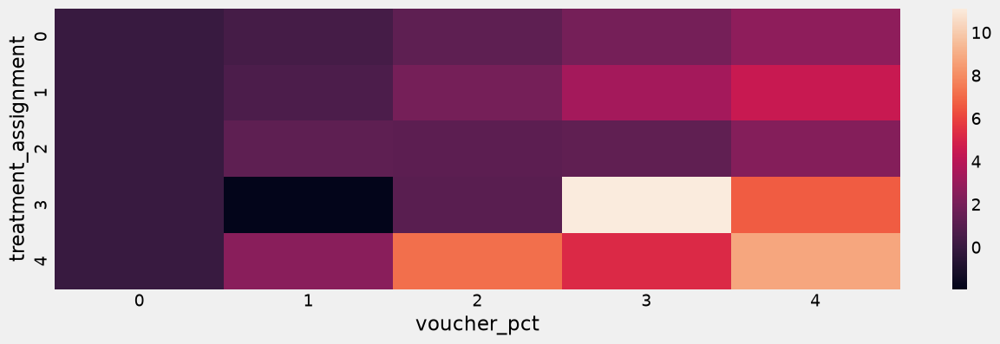

In [121]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm

fig, ax = plt.subplots(1, 1, figsize = (14, 4))
# vcenter = 0
# vmin, vmax = gb.loc[:, 'ATE_AOV'].min().min(), gb.loc[:, 'ATE_AOV'].max().max()
# normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
# colormap = cm.RdBu_r
sns.heatmap(data=gb.loc[:, 'ATE_AOV'], ax = ax,)# cmap = colormap, norm = normalize)
plt.close()
display(fig)

Let's check model scores distribution and compare them to empirical ATE

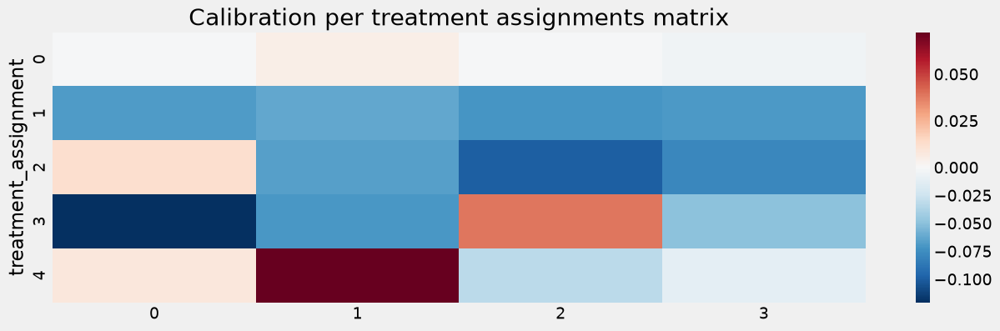

In [122]:
gb_scores = (
    oot_data
    .groupby(['treatment_assignment'])
    .agg({
        **{f"{learner_type}_{c}": 'mean' for c in uplift_predictions.columns},
    })
    # .unstack(-1)
)
fig, ax = plt.subplots(1, 1, figsize = (14, 4))
gb_calibration = pd.concat([gb.loc[:, ('ATE_ORDER')].iloc[:, 1:], gb_scores], axis = 1)
gb_calibration = pd.concat([gb_calibration.iloc[:, i] - gb_calibration.iloc[:, i + len(treatment_labels) - 1] for i in range(len(treatment_labels) - 1)], axis = 1)
vcenter = 0
vmin, vmax = gb_calibration.min().min(), gb_calibration.max().max()
normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
colormap = cm.RdBu_r
sns.heatmap(data = gb_calibration, cmap=colormap, norm = normalize, ax = ax)
ax.set_title('Calibration per treatment assignments matrix')
plt.close()
display(fig)

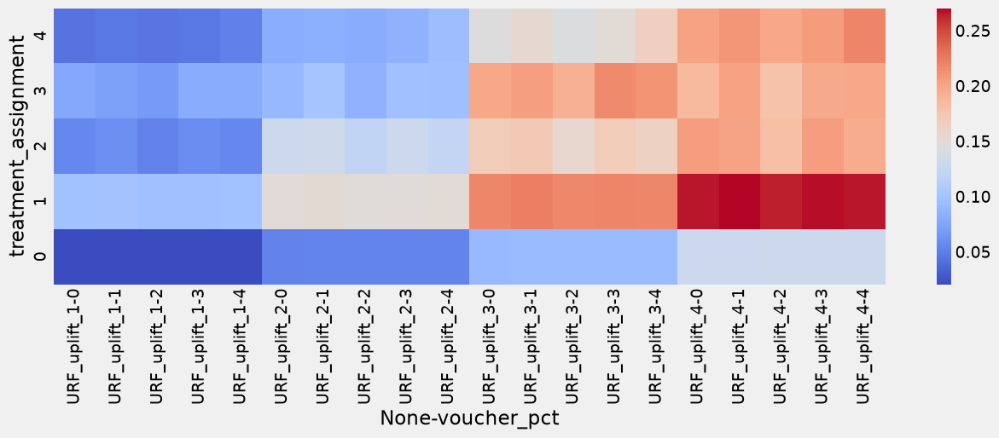

In [123]:
gb = (
    oot_data
    .groupby(['treatment_assignment', treatment_col])
    # .groupby(['treatment_assignment', ])
    .agg({
        **{f"{learner_type}_{c}": 'mean' for c in uplift_predictions.columns},
    })
    .unstack(-1)
)
fig, ax = plt.subplots(1, 1, figsize = (14, 4))
sns.heatmap(data=gb.sort_index(ascending=False), ax = ax, cmap='coolwarm')
plt.close()
display(fig)

We have clear pattern - within each of 4 vertical blocks of 5 randomized voucher groups there's hardly a differentiation across them

At the same time each of 4 uplift model scores groups increasing their average predictions with suggested promo voucher size decrease, except for no-assignment group where it expectedly drops to lowest value

That likely means
- Uplifts are positively correlated by promo groups across customers
- We might have managed to find the customers for whom the higher promo would've been efficient but we still getting an effect with lower promo while saving cost and targeting more customers

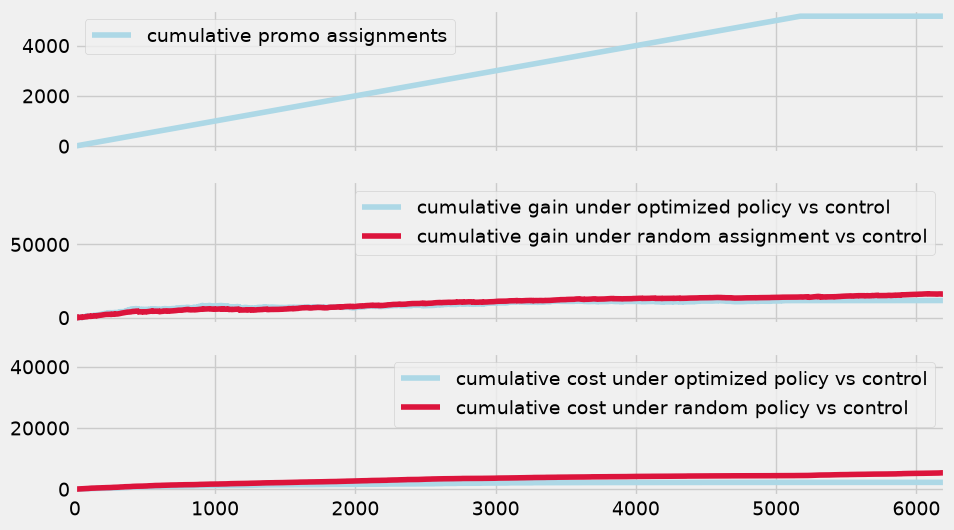

In [124]:
propensity_prob = 1 / len(treatment_labels)

Y = oot_data[target_col].values
a = oot_data['treatment_assignment'].to_numpy()
V_a = np.where(a > 0, V[np.arange(N), a - 1], 0.0)
C_a = np.where(a > 0, C[np.arange(N), a - 1], np.nan)
ratio = np.where(a > 0, V_a / C_a, -np.inf)
ordering = np.argsort(-ratio)

spend_real = oot_data[cost_col].fillna(0).values

matched = oot_data['assignment_match'].astype(float).values
no_treatment = (oot_data[treatment_col] == CONTROL_LABEL).astype(float).values
gain = ((matched - no_treatment) / propensity_prob) * A * Y  ### g_i = (1[D_i = policy-based d_i] * Y_i / e - 1[D_i = 0] / e * Y_i) * AOV
spend = ((matched - no_treatment) / propensity_prob) * spend_real

random_policy = np.ones(N)
gain_random = (random_policy - no_treatment / propensity_prob) * A * Y  ### g_i = (1[D_i = policy-based d_i] * Y_i / e - 1[D_i = 0] / e * Y_i) * AOV
spend_random = (random_policy - no_treatment / propensity_prob) * spend_real

cumulative_assignments = np.cumsum(is_assigned_discount[ordering])

cumulative_gain = np.cumsum(gain[ordering])
cumulative_cost = np.cumsum(spend[ordering])

cumulative_gain_random = np.cumsum(gain_random[ordering])
cumulative_cost_random = np.cumsum(spend_random[ordering])

fig, axes = plt.subplots(3, 1, sharex = True, figsize = (10, 6))
axes[0].plot(np.arange(N), cumulative_assignments, label = 'cumulative promo assignments', color = 'lightblue')
axes[1].plot(np.arange(N), cumulative_gain, label = 'cumulative gain under optimized policy vs control', color = 'lightblue')
axes[1].plot(np.arange(N), cumulative_gain_random, label = 'cumulative gain under random assignment vs control', color = 'crimson')
axes[2].plot(np.arange(N), cumulative_cost, label = 'cumulative cost under optimized policy vs control', color = 'lightblue')
axes[2].plot(np.arange(N), cumulative_cost_random, label = 'cumulative cost under random policy vs control', color = 'crimson')

axes[0].legend()
axes[1].legend()
axes[2].legend()

axes[0].set_xlim(0, n_assigned_treatment_policy * 1.2)
plt.close()
display(fig)

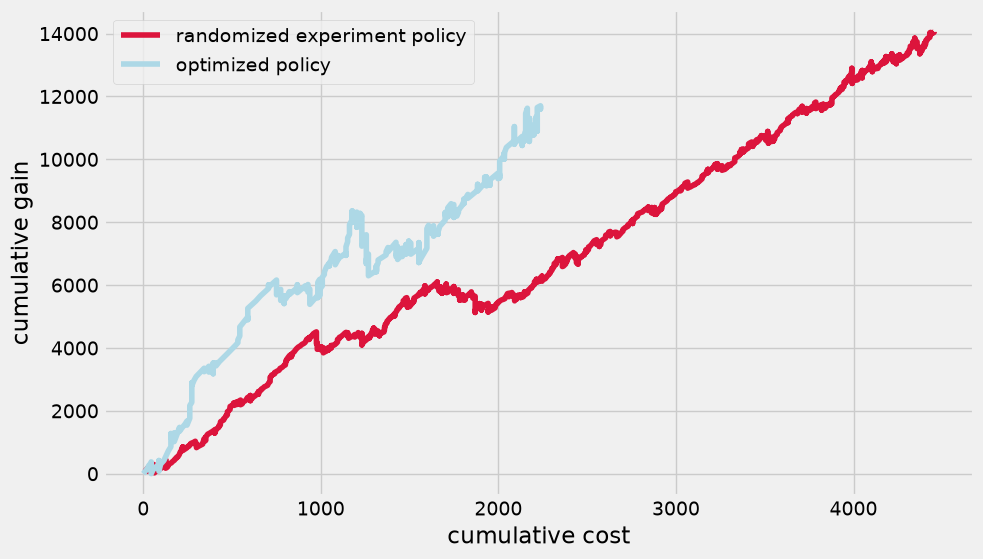

In [125]:
fig, ax = plt.subplots(1, 1, figsize = (10, 6))

n_limit = n_assigned_treatment_policy

ax.plot(cumulative_cost_random[:n_limit], cumulative_gain_random[:n_limit], color = 'crimson', label = 'randomized experiment policy')
ax.plot(cumulative_cost[:n_limit], cumulative_gain[:n_limit], color = 'lightblue', label = 'optimized policy')
ax.set_ylabel("cumulative gain")
ax.set_xlabel("cumulative cost")
ax.legend()
plt.close()
display(fig)

In [126]:
gb = (
    oot_data
    .groupby(treatment_col)
    .agg({
        utilization_col: 'mean',
        'aov_estimate': 'mean',
        cost_col: 'sum',
        id_col: 'count',
    })
    .reset_index()
)

gb['projected_cost'] = gb[treatment_col].map(labels_mapping).astype(int) / 100 * gb['aov_estimate'] * gb[utilization_col] 
gb['average_cost'] = gb[cost_col] / gb[id_col]
display(gb)


gb = (
    oot_data
    .groupby('treatment_assignment')
    .agg({
        utilization_col: 'mean',
        'aov_estimate': 'mean',
        cost_col: 'sum',
        id_col: 'count',
    })
    .reset_index()
)

gb['projected_cost'] = gb['treatment_assignment'].map(labels_mapping).astype(int) / 100 * gb['aov_estimate'] * gb[utilization_col] 
gb['average_cost'] = gb[cost_col] / gb[id_col]
display(gb)

,voucher_pct,voucher_used,aov_estimate,voucher_cost,user_id,projected_cost,average_cost
0,0,0.000000,21.645644,0.000000,12025,0.000000,0.000000
1,1,0.085600,21.814914,2704.231187,12021,0.186736,0.224959
2,2,0.113746,21.840031,7258.187348,12018,0.496843,0.603943
3,3,0.147969,21.784092,13177.607629,12016,0.967014,1.096672
4,4,0.186714,21.953966,19317.266970,12013,1.639649,1.608030


,treatment_assignment,voucher_used,aov_estimate,voucher_cost,user_id,projected_cost,average_cost
0,0,0.104836,21.519660,38002.886805,54924,0.000000,0.691918
1,1,0.138502,22.417326,3908.337574,4231,0.310483,0.923738
2,2,0.049133,19.165161,103.035149,346,0.188328,0.297789
3,3,0.088889,44.623936,98.525038,135,1.189972,0.729815
4,4,0.096280,46.042008,344.508567,457,1.773171,0.753848


Now we still underestimate the budget, but it is much much better already

Let's try to calibrate for current budget overspend

In [127]:
budget_conservative_coef = cumulative_cost[:n_limit][-1] / (total_budget_2weeks / 2)
budget_conservative_coef

1.2783339828886906

# Assembling everything together to make an inference on week 15

In [128]:
weekly_inference_data = inference_data.copy()
display(weekly_inference_data.tail())

,user_id,week,city,orders_90d,orders_30d,days_since_last_order,aov_90d,pct_orders_with_promo_90d,avg_voucher_pct_received_90d,voucher_redemption_rate_90d,...,is_observed_lag_1w,order_value_total_1w,orders_7d,next_week,aov_90d_fwd_1w,orders_90d_fwd_1w,is_observed_fwd_1w,weekly_value,weekly_orders,city_ENCODED
60203,79995,15,city_04,2,1,1.0,7.262467,0.000000,16.923077,0.000000,...,1,-3.476725,0.0,16,7.262467,2.0,1,0.000000,0.0,3
60204,79996,15,city_03,2,1,18.0,26.790615,0.500000,18.461538,0.000000,...,1,0.000000,0.0,16,26.790615,2.0,1,0.000000,0.0,2
60205,79997,15,city_06,4,2,2.0,17.116272,0.000000,18.461538,0.000000,...,1,16.393204,1.0,16,NaN,NaN,0,NaN,NaN,5
60206,79998,15,city_01,13,4,1.0,16.820773,0.307692,11.538462,0.400000,...,1,-9.637054,0.0,16,16.593755,13.0,1,-2.951233,0.0,0
60207,79999,15,city_06,4,1,15.0,30.538761,0.750000,20.000000,0.272727,...,1,-26.821091,-1.0,16,29.524445,4.0,1,-4.057266,0.0,5


### establish weekly budget

In [129]:
total_budget_2weeks = 3500
weekly_budget = total_budget_2weeks / 2

budget_conservative_coef = 1.25

### obtain AOV estimate

In [130]:
weekly_inference_data['aov_90d_forecast'] = aov_model.predict(weekly_inference_data[aov_model.feature_name_])
weekly_inference_data['aov_estimate'] = weekly_inference_data['aov_90d'].fillna(0)
weekly_inference_data.loc[weekly_inference_data['aov_estimate'] == 0, 'aov_estimate'] = weekly_inference_data.loc[weekly_inference_data['aov_estimate'] == 0, 'aov_90d_forecast']
aov = weekly_inference_data['aov_estimate']

print(aov_model.feature_name_)

['sessions_30d', 'days_since_last_session', 'push_opt_in', 'offers_tab_share_of_sessions_30d']


### create expected cost matrix from AOV estimate

In [131]:
discounts = (pd.Series([t for t in treatment_labels if t != CONTROL_LABEL]).map(labels_mapping).astype(int) / 100).values
discounts_grid = np.tile(discounts, (len(aov), 1))
expected_voucher_cost = np.clip(discounts_grid * aov.values[:, None], 0, 9)
display(expected_voucher_cost)

array([[2.20808739, 4.41617479, 6.62426218, 8.83234957],
       [2.25276432, 4.50552864, 6.75829296, 9.        ],
       [2.08685673, 4.17371347, 6.2605702 , 8.34742693],
       ...,
       [1.7116272 , 3.42325439, 5.13488159, 6.84650879],
       [1.68207726, 3.36415452, 5.04623178, 6.72830904],
       [3.05387611, 6.10775223, 9.        , 9.        ]])

### estimate conditional expected utilization under treatment

In [132]:
U_X = weekly_inference_data.loc[:, utilization_model.feature_name_].copy()

U_X[treatment_col] = CONTROL_LABEL

U_estimate = []
for t_label in tqdm(treatment_labels):
    if t_label == CONTROL_LABEL:
        continue
    U_X[treatment_col] = t_label
    U_estimate_t = pd.Series(utilization_model.predict_proba(U_X)[:, 1], index = U_X.index, name = f"U_estimate_{t_label}")
    U_estimate.append(U_estimate_t)

U_estimate = pd.concat(U_estimate, axis = 1)
# display(U_estimate.tail())

print(utilization_model.feature_name_)

  0%|          | 0/5 [00:00<?, ?it/s]

['orders_90d', 'orders_30d', 'days_since_last_order', 'aov_90d', 'pct_orders_with_promo_90d', 'avg_voucher_pct_received_90d', 'voucher_redemption_rate_90d', 'manual_voucher_entry_rate_90d', 'sessions_30d', 'days_since_last_session', 'push_opt_in', 'offers_tab_share_of_sessions_30d', 'voucher_pct_lag_1w', 'free_delivery_lag_1w', 'aov_90d_lag_1w', 'orders_90d_lag_1w', 'ordered_lag_1w', 'voucher_used_lag_1w', 'voucher_cost_lag_1w', 'voucher_pct', 'free_delivery']


### obtain uplift estimates

2026-10-28T23:03:17,923  INFO learners.py - Calculating predictions..


,uplift_1,uplift_2,uplift_3,uplift_4
60206,-0.019428,-0.004713,0.036293,-0.000732
60207,0.076736,0.154231,0.272296,0.334892


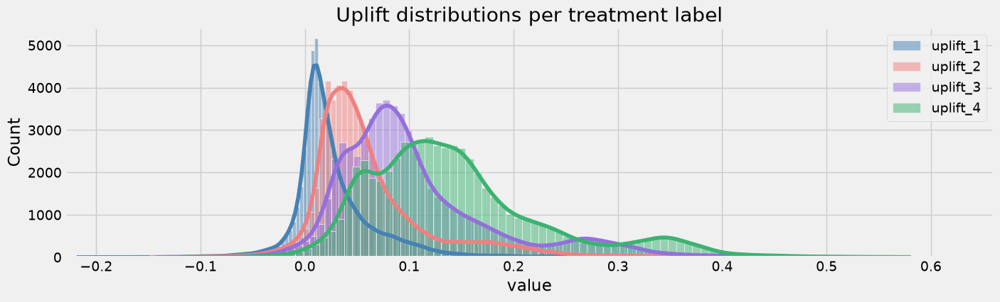

['orders_90d', 'orders_30d', 'days_since_last_order', 'aov_90d', 'pct_orders_with_promo_90d', 'avg_voucher_pct_received_90d', 'voucher_redemption_rate_90d', 'manual_voucher_entry_rate_90d', 'sessions_30d', 'days_since_last_session', 'push_opt_in', 'offers_tab_share_of_sessions_30d', 'voucher_pct_lag_1w', 'free_delivery_lag_1w', 'aov_90d_lag_1w', 'orders_90d_lag_1w', 'ordered_lag_1w', 'voucher_used_lag_1w', 'voucher_cost_lag_1w', 'city_ENCODED', 'free_delivery']


In [133]:
learner_type = 'URF'
learner = fitted_learners[learner_type]

uplift_predictions, control_prediction = learner.predict(weekly_inference_data[learner.features], return_baseline=True)
display(uplift_predictions.tail(2))
fig, ax = plot_metric_distribution_by_classes(
    data = uplift_predictions.melt(), class_name='variable', metric_name='value',
    figsize=(15, 4),
    title = "Uplift distributions per treatment label",
)
display(fig)

print(learner.features)

### combine inputs for optimization problem

In [134]:
# D: (N, 4) - expected uplift in conversion under treatment assignment
D = uplift_predictions.values
# U: (N, 4) - expected utilization under treatment assignment
U = U_estimate.values
# C: (N, 4) - expected promo cost from voucher discount given utilization happens under treatment assignment
C = expected_voucher_cost
# A: (N, ) - expected order value for the order given conversion
A = aov.values

# expected incremental value under treatment assignment
V =  A[:, None] * D
# expected spend under treatment assignment
S = U[:, :] * C[:, :]
# weekly budget constraint with extra conservative estimate 
B = weekly_budget / budget_conservative_coef

N, K = V.shape

### promo assignment matrix - technically continuous between 0 and 1, but we'll map to discrete values if required
X = cp.Variable((N, K), nonneg = True)
constraints = [
    cp.sum(X, axis=1) <= 1, ### at most 1 promo voucher per user
    cp.sum(cp.multiply(S, X)) <= B, ### budget limitations
]

### run the solver and interpret the readings

Problem status: optimal, expected total CU gain from incremental orders: 13650.092026538558
Total users with vouchers assigned: 4197
Projected spend: 1749.999999999999 CU (conservative estimate), 1399.9999999999993 CU (optimistic estimate)


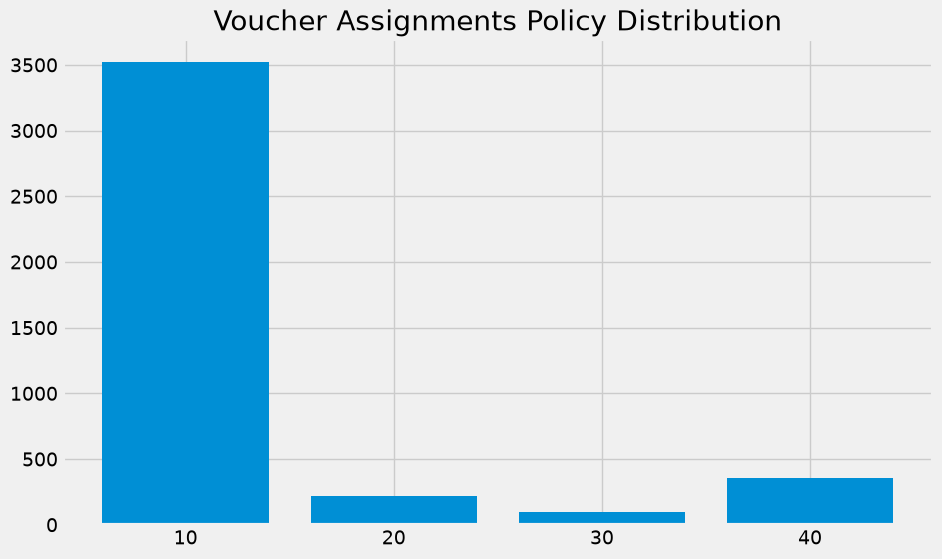

In [135]:
problem = cp.Problem(cp.Maximize(cp.sum(cp.multiply(V, X))), constraints=constraints)
problem.solve(solver = cp.HIGHS)
print(f"Problem status: {problem.status}, expected total CU gain from incremental orders: {problem.value}")

is_assigned_discount = (X.value.sum(axis=1) > 0.5).astype(int)
projected_spend = (S * X.value).sum()
n_assigned_treatment_policy = is_assigned_discount.sum()
weekly_inference_data['treatment_assignment'] = np.where(
    is_assigned_discount, 
    X.value.argmax(axis = 1) + 1, ### shifting because left-most col is not control, but treatment 1
    0 ### if no selection meaning we're assigning control group
)
print(f"Total users with vouchers assigned: {n_assigned_treatment_policy}")
print(f"Projected spend: {projected_spend * budget_conservative_coef} CU (conservative estimate), {projected_spend} CU (optimistic estimate)")
fig, ax = plt.subplots(1, 1, figsize = (10, 6))
vc = weekly_inference_data['treatment_assignment'].value_counts()
vc = vc.loc[vc.index != CONTROL_LABEL]
ax.bar(vc.index, vc)
ax.set_xticks(vc.index)
ax.set_xticklabels(vc.index.map(labels_mapping))
ax.set_title("Voucher Assignments Policy Distribution")
plt.close()
display(fig)

In [136]:
display(weekly_inference_data[[id_col, 'treatment_assignment']])

,user_id,treatment_assignment
0,1,0
1,2,0
2,3,0
3,6,1
4,7,0
...,...,...
60203,79995,0
60204,79996,0
60205,79997,0
60206,79998,0


In [137]:
pipeline_decisions = pd.read_csv('./outputs/decisions.csv')
pipeline_decisions = pd.merge(pipeline_decisions, weekly_inference_data[[id_col, 'treatment_assignment']], on = id_col, how = 'outer')
(pipeline_decisions['voucher_pct'].astype(int) != pipeline_decisions['treatment_assignment'].map(labels_mapping).astype(int)).sum()

0